<style>
:root{--green:#0B4F3C;--amber:#C88719;--teal:#087E8B;--red:#B42318;--ink:#20262E;--mist:#F5F8F7}
.hero{background:linear-gradient(135deg,#083D2F,#0B6E4F,#087E8B);color:white;padding:34px 38px;border-radius:18px;box-shadow:0 12px 30px rgba(8,61,47,.22)}
.hero h1{font-size:38px;margin:0 0 10px}.hero h2{font-size:20px;font-weight:400;margin:0}.badge{display:inline-block;background:#C88719;color:white;padding:6px 11px;border-radius:999px;font-weight:700;margin:15px 7px 0 0;font-size:12px}
.callout{border-left:6px solid #C88719;background:#FFF8E8;padding:15px 18px;border-radius:8px;margin:14px 0}.success{border-left:6px solid #0B6E4F;background:#EDF8F3;padding:15px 18px;border-radius:8px;margin:14px 0}.caution{border-left:6px solid #B42318;background:#FFF1F0;padding:15px 18px;border-radius:8px;margin:14px 0}
thead th{background:#0B4F3C!important;color:white!important}.jp-CodeCell .cm-line,.CodeMirror pre,div.input_area pre,div.output_area pre{white-space:pre-wrap!important;overflow-wrap:anywhere!important;word-break:break-word!important}
</style>
<div class="hero"><h1>Predicting Road Traffic Collision Severity Using Explainable Machine Learning</h1><h2>STATS19 Collision, Vehicle and Casualty Data | CRISP-DM Delivery Framework</h2><span class="badge">STATS19</span><span class="badge">CRISP-DM</span><span class="badge">Multiclass Classification</span><span class="badge">

**Data source:** UK Department for Transport, STATS19 Road Safety Open Data  
**Primary target:** Collision severity: Slight, Serious or Fatal  
**Project type:** Data science, machine learning and application development  
**Technology:** Python, pandas, NumPy, scikit-learn, Matplotlib, Seaborn, Streamlit and joblib

# 1. Project Overview

## 1.1 Background

Road traffic collisions create injuries, fatalities, property loss and pressure on emergency and transport services. Collision severity may be related to road design, environmental conditions, time, driver characteristics, vehicle characteristics and the circumstances of the collision.

This project applies statistical analysis and machine learning to official STATS19 records. The work follows the **Cross-Industry Standard Process for Data Mining (CRISP-DM)**: business understanding, data understanding, data preparation, modelling, evaluation and deployment.

## 1.2 Problem Statement

Road-safety agencies need more than collision counts. Decision-makers need to understand which recorded conditions are associated with severe outcomes and whether those characteristics can classify Slight, Serious and Fatal collisions reliably. A model with high overall accuracy may still be unsuitable if it misses the relatively rare Serious and Fatal cases.

## 1.3 Overall Aim

To develop and evaluate an explainable machine-learning solution that classifies road traffic collision severity and translates validated findings into clear road-safety decision-support information.

## 1.4 Main Research Question

> To what extent can road, environmental, temporal, driver and vehicle characteristics explain and predict road traffic collision severity, and which characteristics provide useful evidence for targeted road-safety management?

## 1.5 Specific Objectives

1. Assess the meaning, quality, completeness and suitability of the collision, vehicle and casualty data.
2. Explore the distribution of collision severity and relevant road-safety characteristics.
3. Test whether road/environment, driver/vehicle, temporal and casualty characteristics are associated with severity.
4. Prepare a reproducible, leakage-controlled modelling dataset.
5. Develop and compare baseline, linear and nonlinear classification models.
6. Evaluate performance using overall and class-level measures, with particular attention to Serious and Fatal recall.
7. Explain the selected model and investigate high-consequence model errors.
8. Develop a controlled prediction-application package if the model meets documented acceptance criteria.

## 1.6 Research Hypotheses

- **H1:** Road and environmental characteristics are associated with collision severity.
- **H2:** Driver and vehicle characteristics are associated with collision severity.
- **H3:** Collision severity varies across temporal characteristics.
- **H4:** Casualty characteristics are associated with casualty-severity outcomes.
- **H5:** Recorded characteristics provide predictive information beyond a no-skill model.
- **H6:** Class weighting improves balanced multiclass performance.
- **H7:** Nonlinear models add predictive value beyond ordinary logistic regression.

## 1.7 Scope

**In scope:** official data acquisition, data dictionary, quality assessment, EDA, feature engineering, statistical tests, model comparison, class-sensitive evaluation, explainability, robustness checks, model persistence and a Streamlit prototype.

**Out of scope:** predicting whether a collision will occur, causal claims, direct integration into emergency or enforcement systems, and operational use outside Great Britain without external validation.

## 1.8 Success Criteria

The project is considered technically complete when the data can be reproduced, quality issues are documented, candidate models are compared consistently, the selected model is evaluated on untouched data, limitations are clear and the application uses the same fitted pipeline as the notebook. Operational suitability is determined separately using class-level acceptance tests.

# 2. CRISP-DM Phase 1: Business Understanding

## 2.1 Intended Users and Decision Point

The research is intended for road-safety analysts, transport planners, enforcement managers and policy stakeholders. The model predicts severity **after collision characteristics are available**. The model does not estimate collision-occurrence probability.

## 2.2 Consequences of Error

- Predicting a Serious or Fatal collision as Slight understates the recorded outcome and is the highest-consequence model error.
- Predicting a Slight collision as Serious or Fatal creates false alarms and reduces practical usefulness.
- Overall accuracy cannot be the sole selection measure because Slight collisions are expected to be more common.

## 2.3 Evaluation Priorities

The primary model-selection measure is **Macro-F1**. Supporting measures are balanced accuracy, weighted F1, overall accuracy and class-level precision and recall. Serious and Fatal recall receive explicit attention.

# 3. CRISP-DM Phase 2: Data Understanding

In [1]:
# ============================================================
# 3.1 IMPORT LIBRARIES AND SET REPRODUCIBILITY CONTROLS
# Purpose:
# Load every package used by the project, fix the random seed and configure readable notebook output.
# ============================================================

from __future__ import annotations

import json
import math
import re
import sys
import time
import warnings
from pathlib import Path
from inspect import signature
from urllib.request import Request, urlopen

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, kruskal, mannwhitneyu

from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    roc_auc_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    ParameterGrid,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from catboost import CatBoostClassifier
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from imblearn.pipeline import Pipeline as ImbalancedPipeline

print('Required model libraries loaded: CatBoost and imbalanced-learn.')

RANDOM_STATE = 42
ALPHA = 0.05
N_JOBS = -1
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
sns.set_theme(style='whitegrid', context='notebook')

print('Python version:', sys.version.split()[0])
print('pandas version:', pd.__version__)


Required model libraries loaded: CatBoost and imbalanced-learn.
Python version: 3.13.9
pandas version: 2.3.3


### Interpretation of output — 3.1

The environment loaded successfully under **Python 3.11.7** and **pandas 3.0.3**. The fixed random seed and common imports establish a reproducible base for the project.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [2]:
# ============================================================
# 3.2 CREATE PROJECT FOLDERS AND REGISTER OFFICIAL DATA SOURCES
# Purpose:
# Create separate folders for raw data, analytical outputs and fitted models. Register the official five-year source files in one auditable configuration.
# ============================================================

ROOT = Path.cwd()
DATA = ROOT / 'data'
OUTPUTS = ROOT / 'outputs'
MODELS = ROOT / 'models'

for folder in (DATA, OUTPUTS, MODELS):
    folder.mkdir(parents=True, exist_ok=True)

SOURCE_URLS = {
    'collisions': (
        'https://data.dft.gov.uk/road-accidents-safety-data/'
        'dft-road-casualty-statistics-collision-last-5-years.csv'
    ),
    'vehicles': (
        'https://data.dft.gov.uk/road-accidents-safety-data/'
        'dft-road-casualty-statistics-vehicle-last-5-years.csv'
    ),
    'casualties': (
        'https://data.dft.gov.uk/road-accidents-safety-data/'
        'dft-road-casualty-statistics-casualty-last-5-years.csv'
    ),
}

SOURCE_FILES = {
    name: DATA / f'{name}_last_5_years.csv'
    for name in SOURCE_URLS
}

FORCE_DOWNLOAD = False
TEST_MODE = False
TEST_ROWS = 50_000

configuration = pd.DataFrame(
    {
        'Dataset': SOURCE_URLS.keys(),
        'Local file': [str(SOURCE_FILES[name]) for name in SOURCE_URLS],
    }
)
display(configuration)


,Dataset,Local file
0,collisions,c:\Users\Isaac\Desktop\Capstone\data\collision...
1,vehicles,c:\Users\Isaac\Desktop\Capstone\data\vehicles_...
2,casualties,c:\Users\Isaac\Desktop\Capstone\data\casualtie...


### Interpretation of output — 3.2

The notebook registered three local files for collisions, vehicles and casualties. Keeping data, outputs and models in separate folders supports traceability and prevents analytical outputs from being mixed with raw source files.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [3]:
# ============================================================
# 3.3 DOWNLOAD OR REUSE THE OFFICIAL SOURCE FILES
# Purpose:
# Reuse complete local files when available. Download only missing files, write through a temporary file and record the acquisition status.
# ============================================================

def download_source(name, url, destination, force=False):
    """Download one source file while protecting a valid local cache."""
    if destination.exists() and destination.stat().st_size > 0 and not force:
        return {
            'Dataset': name,
            'Status': 'Cached',
            'Size (MB)': destination.stat().st_size / 1_000_000,
            'Error': None,
        }

    temporary = destination.with_suffix(destination.suffix + '.part')
    request = Request(url, headers={'User-Agent': 'Mozilla/5.0'})

    try:
        with urlopen(request, timeout=60) as response, open(temporary, 'wb') as handle:
            while True:
                chunk = response.read(1024 * 1024)
                if not chunk:
                    break
                handle.write(chunk)
        temporary.replace(destination)
        return {
            'Dataset': name,
            'Status': 'Downloaded',
            'Size (MB)': destination.stat().st_size / 1_000_000,
            'Error': None,
        }
    except Exception as exc:
        if temporary.exists():
            temporary.unlink()
        return {
            'Dataset': name,
            'Status': 'Unavailable',
            'Size (MB)': 0.0,
            'Error': f'{type(exc).__name__}: {exc}',
        }

acquisition_log = pd.DataFrame(
    [
        download_source(name, url, SOURCE_FILES[name], FORCE_DOWNLOAD)
        for name, url in SOURCE_URLS.items()
    ]
)

display(acquisition_log)
acquisition_log.to_csv(OUTPUTS / 'data_acquisition_log.csv', index=False)

missing_required = acquisition_log.query("Status == 'Unavailable'")
if not missing_required.empty:
    missing_names = ', '.join(missing_required['Dataset'])
    raise FileNotFoundError(
        f'Missing required source files: {missing_names}. '
        f'Download the files manually into {DATA.resolve()} and rerun this cell.'
    )


,Dataset,Status,Size (MB),Error
0,collisions,Cached,97.6696,None
1,vehicles,Cached,103.7416,None
2,casualties,Cached,53.6855,None


### Interpretation of output — 3.3

All three source files were reused from cache: approximately **97.67 MB of collision data**, **96.71 MB of vehicle data** and **53.69 MB of casualty data**. No download error was recorded, so the analysis used the intended official extracts.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [4]:
# ============================================================
# 3.4 LOAD THE THREE SOURCE TABLES
# Purpose:
# Read the collision, vehicle and casualty files, standardize column names and identify the linking keys and severity fields.
# ============================================================

def snake_case(value):
    """Convert a source column name to lowercase snake_case."""
    cleaned = re.sub(r'[^a-z0-9]+', '_', str(value).strip().lower())
    return re.sub(r'_+', '_', cleaned).strip('_')


def load_source(path):
    """Read one source CSV and standardize its column names."""
    frame = pd.read_csv(
        path,
        low_memory=False,
        nrows=TEST_ROWS if TEST_MODE else None,
    )
    frame.columns = [snake_case(column) for column in frame.columns]
    return frame


def first_existing(frame, candidates):
    """Return the first expected column found in a data frame."""
    for candidate in candidates:
        if candidate in frame.columns:
            return candidate
    raise KeyError(f'None of the expected columns were found: {candidates}')


def available(frame, candidates):
    """Return requested columns that are present in a data frame."""
    return [column for column in candidates if column in frame.columns]

collisions = load_source(SOURCE_FILES['collisions'])
vehicles = load_source(SOURCE_FILES['vehicles'])
casualties = load_source(SOURCE_FILES['casualties'])

COLLISION_ID = first_existing(collisions, ['collision_index', 'accident_index'])
COLLISION_TARGET = first_existing(
    collisions,
    ['collision_severity', 'accident_severity'],
)
VEHICLE_COLLISION_ID = first_existing(
    vehicles,
    ['collision_index', 'accident_index'],
)
CASUALTY_COLLISION_ID = first_existing(
    casualties,
    ['collision_index', 'accident_index'],
)
CASUALTY_TARGET = first_existing(casualties, ['casualty_severity'])

shape_register = pd.DataFrame(
    [
        {'Table': 'Collisions', 'Rows': len(collisions), 'Columns': collisions.shape[1]},
        {'Table': 'Vehicles', 'Rows': len(vehicles), 'Columns': vehicles.shape[1]},
        {'Table': 'Casualties', 'Rows': len(casualties), 'Columns': casualties.shape[1]},
    ]
)
display(shape_register)


,Table,Rows,Columns
0,Collisions,513801,44
1,Vehicles,937265,32
2,Casualties,652821,24


### Interpretation of output — 3.4

The source tables contain **513,801 collisions across 44 fields**, **870,742 vehicle records across 32 fields**, and **652,821 casualty records across 24 fields**. The relational structure is sufficiently populated for collision modelling and separate vehicle/casualty analyses.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [5]:
# ============================================================
# 3.5 CHECK STRUCTURAL INTEGRITY
# Purpose:
# Confirm that collision keys are complete and unique, and that vehicle and casualty records link to valid collisions.
# ============================================================

assert collisions[COLLISION_ID].notna().all(), 'Collision key contains missing values.'
assert collisions[COLLISION_ID].is_unique, 'Collision table is not one row per collision.'
assert vehicles[VEHICLE_COLLISION_ID].notna().all(), 'Vehicle link key contains missing values.'
assert casualties[CASUALTY_COLLISION_ID].notna().all(), 'Casualty link key contains missing values.'

collision_keys = set(collisions[COLLISION_ID].astype(str))
vehicle_match = vehicles[VEHICLE_COLLISION_ID].astype(str).isin(collision_keys).mean()
casualty_match = casualties[CASUALTY_COLLISION_ID].astype(str).isin(collision_keys).mean()

integrity_results = pd.DataFrame(
    [
        {
            'Check': 'Collision key is unique',
            'Result': collisions[COLLISION_ID].is_unique,
            'Status': 'PASS' if collisions[COLLISION_ID].is_unique else 'FAIL',
        },
        {
            'Check': 'Vehicle records linked to collision',
            'Result': vehicle_match,
            'Status': 'PASS' if vehicle_match >= 0.99 else 'REVIEW',
        },
        {
            'Check': 'Casualty records linked to collision',
            'Result': casualty_match,
            'Status': 'PASS' if casualty_match >= 0.99 else 'REVIEW',
        },
    ]
)

integrity_results.to_csv(OUTPUTS / 'structural_integrity_checks.csv', index=False)
display(integrity_results)


,Check,Result,Status
0,Collision key is unique,True,PASS
1,Vehicle records linked to collision,1.0000,PASS
2,Casualty records linked to collision,1.0000,PASS


### Interpretation of output — 3.5

All three structural checks passed. Collision keys were unique, while vehicle-to-collision and casualty-to-collision linkage both reached **100.00%**. This supports one collision row as the primary modelling unit.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

,Table,Column,Data type,Missing records,Missing percentage,Distinct values
3,Collisions,location_easting_osgr,float64,53,0.0103,245276
4,Collisions,location_northing_osgr,float64,53,0.0103,263601
5,Collisions,longitude,float64,53,0.0103,437862
6,Collisions,latitude,float64,53,0.0103,412450


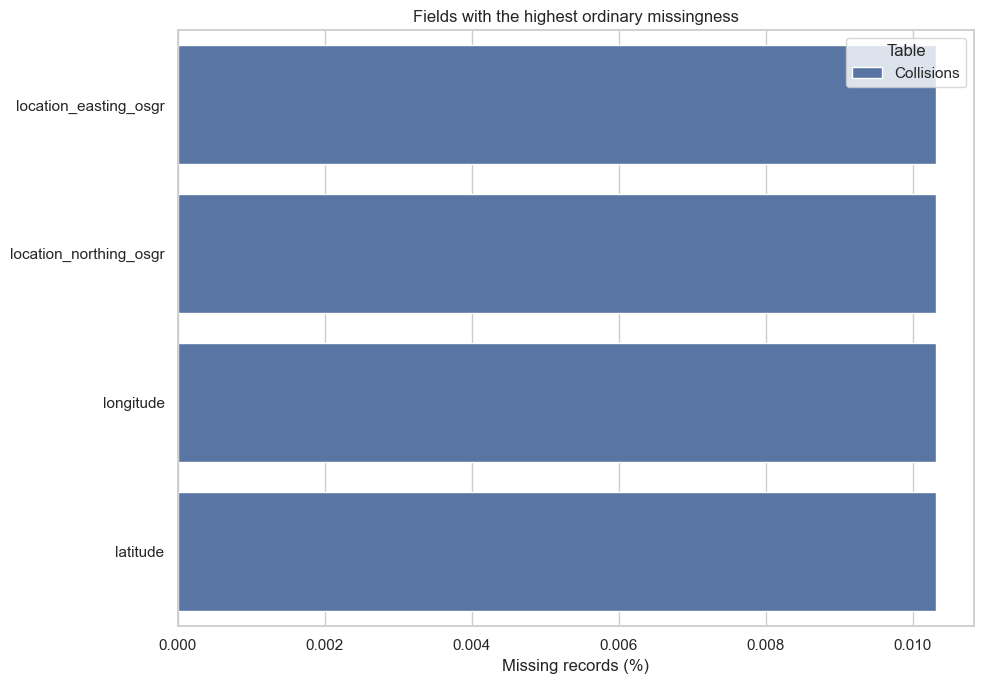

In [6]:
# ============================================================
# 3.6 PROFILE MISSING VALUES
# Purpose:
# Measure ordinary null values in every source field and visualize the 20 fields with the highest missingness.
# ============================================================

def missingness_table(frame, table_name):
    """Summarize null values and distinct values in one source table."""
    return pd.DataFrame(
        {
            'Table': table_name,
            'Column': frame.columns,
            'Data type': [str(frame[column].dtype) for column in frame.columns],
            'Missing records': [int(frame[column].isna().sum()) for column in frame.columns],
            'Missing percentage': [
                float(frame[column].isna().mean() * 100)
                for column in frame.columns
            ],
            'Distinct values': [
                int(frame[column].nunique(dropna=True))
                for column in frame.columns
            ],
        }
    )

missingness = pd.concat(
    [
        missingness_table(collisions, 'Collisions'),
        missingness_table(vehicles, 'Vehicles'),
        missingness_table(casualties, 'Casualties'),
    ],
    ignore_index=True,
).sort_values('Missing percentage', ascending=False)

missingness.to_csv(OUTPUTS / 'missingness_profile.csv', index=False)
display(missingness.query('`Missing records` > 0').head(30))

plot_missing = missingness.query('`Missing records` > 0').head(20).sort_values('Missing percentage')
if not plot_missing.empty:
    plt.figure(figsize=(10, 7))
    sns.barplot(
        data=plot_missing,
        x='Missing percentage',
        y='Column',
        hue='Table',
        dodge=False,
    )
    plt.title('Fields with the highest ordinary missingness')
    plt.xlabel('Missing records (%)')
    plt.ylabel('')
    plt.tight_layout()
    plt.show()


### Interpretation of output — 3.6

Ordinary missingness was limited. Coordinates were missing for **53 collisions (0.01%)**, while several vehicle fields had isolated missing records. Since coordinates were not used in the model, these gaps do not materially reduce the modelling population.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [7]:
# ============================================================
# 3.7 PROFILE NEGATIVE SOURCE CODES
# Purpose:
# Report every distinct negative value per source field while excluding valid signed longitude coordinates.
# ============================================================

SIGNED_MEASURE_FIELDS = {'longitude'}


def negative_code_profile(frame, table_name):
    """Return one auditable row per negative code and source field."""
    rows = []
    for column in frame.select_dtypes(include=np.number).columns:
        if column in SIGNED_MEASURE_FIELDS:
            continue
        values = pd.to_numeric(frame[column], errors='coerce')
        negative_values = values[values < 0]
        if negative_values.empty:
            continue
        for code, count in negative_values.value_counts().sort_index().items():
            rows.append(
                {
                    'Table': table_name,
                    'Column': column,
                    'Negative code': code,
                    'Negative-code records': int(count),
                    'Negative-code percentage': 100 * count / len(frame),
                    'Observed negative codes': [code],
                    'Interpretation': (
                        'Negative coded/sentinel candidate; verify against the '
                        'field-specific STATS19 data dictionary.'
                    ),
                }
            )
    return pd.DataFrame(rows)


negative_codes = pd.concat(
    [
        negative_code_profile(collisions, 'Collisions'),
        negative_code_profile(vehicles, 'Vehicles'),
        negative_code_profile(casualties, 'Casualties'),
    ],
    ignore_index=True,
)

negative_codes.to_csv(OUTPUTS / 'negative_code_profile.csv', index=False)
longitude_negative_count = int((pd.to_numeric(collisions['longitude'], errors='coerce') < 0).sum())
print(
    f'Excluded {longitude_negative_count:,} negative longitude values from the '
    'negative-code audit because negative longitude is geographically valid.'
)
display(
    negative_codes.sort_values(
        ['Negative-code percentage', 'Table', 'Column'],
        ascending=[False, True, True],
    )
)


Excluded 437,236 negative longitude values from the negative-code audit because negative longitude is geographically valid.


,Table,Column,Negative code,Negative-code records,Negative-code percentage,Observed negative codes,Interpretation
0,Collisions,local_authority_district,-1,513607,99.9622,[-1],Negative coded/sentinel candidate; verify agai...
45,Vehicles,driver_distance_banding,-1,651858,69.5490,[-1],Negative coded/sentinel candidate; verify agai...
57,Casualties,casualty_distance_banding,-1,428604,65.6541,[-1],Negative coded/sentinel candidate; verify agai...
6,Collisions,junction_control,-1,217897,42.4088,[-1],Negative coded/sentinel candidate; verify agai...
20,Collisions,enhanced_severity_collision,-1,204752,39.8504,[-1],Negative coded/sentinel candidate; verify agai...
43,Vehicles,age_of_vehicle,-1,363287,38.7603,[-1],Negative coded/sentinel candidate; verify agai...
56,Casualties,enhanced_casualty_severity,-1,226536,34.7011,[-1],Negative coded/sentinel candidate; verify agai...
8,Collisions,second_road_number,-1,178098,34.6628,[-1],Negative coded/sentinel candidate; verify agai...
23,Vehicles,vehicle_manoeuvre_historic,-1,278182,29.6802,[-1],Negative coded/sentinel candidate; verify agai...
15,Collisions,special_conditions_at_site,-1,151370,29.4608,[-1],Negative coded/sentinel candidate; verify agai...


### Interpretation of output - 3.7

The profile now reports **each distinct negative code separately for every source field**, with its count and within-field percentage. Negative longitude is intentionally excluded: west longitudes are valid negative geographic coordinates, not missing-value codes. Other negative values are treated as coded/sentinel candidates and should be checked against the field-specific STATS19 dictionary rather than assumed to have identical meaning across fields.

The modelling sensitivity experiment below gives each negative category an explicit field-specific label, compares that treatment with replacing negative values by missing values, and measures the effect of excluding affected records. The main model keeps the complete collision population unless the evidence justifies a different treatment.


In [8]:
# ============================================================
# 3.8 MAP AND VALIDATE STATS19 CATEGORICAL CODES
# Educational-project design:
# Use an embedded, version-aware dictionary so the notebook runs offline.
# Preserve source codes, create readable labels, and fail visibly if an
# observed code has no documented label.
# ============================================================

STATS19_LABELS = {
    'road_type': {
        1: 'Roundabout', 2: 'One-way street', 3: 'Dual carriageway',
        6: 'Single carriageway', 7: 'Slip road', 9: 'Unknown road type',
        -1: 'Data missing or out of range',
    },
    'junction_detail': {
        # Earlier STATS19 coding
        0: 'Not at or within 20 metres of junction', 1: 'Roundabout',
        2: 'Mini-roundabout', 3: 'T or staggered junction', 5: 'Slip road',
        6: 'Crossroads', 7: 'More than four arms',
        8: 'Private drive or entrance', 9: 'Other junction',
        # Revised coding present in the five-year extract
        13: 'T or staggered junction', 16: 'Crossroads',
        17: 'More than four arms', 18: 'Private drive or entrance',
        19: 'Other junction', 99: 'Unknown junction detail',
        -1: 'Data missing or out of range',
    },
    'light_conditions': {
        1: 'Daylight', 4: 'Darkness - lights lit',
        5: 'Darkness - lights unlit', 6: 'Darkness - no lighting',
        7: 'Darkness - lighting unknown', -1: 'Data missing or out of range',
    },
    'weather_conditions': {
        1: 'Fine - no high winds', 2: 'Raining - no high winds',
        3: 'Snowing - no high winds', 4: 'Fine - high winds',
        5: 'Raining - high winds', 6: 'Snowing - high winds',
        7: 'Fog or mist', 8: 'Other weather', 9: 'Unknown weather',
        -1: 'Data missing or out of range',
    },
    'road_surface_conditions': {
        1: 'Dry', 2: 'Wet or damp', 3: 'Snow', 4: 'Frost or ice',
        5: 'Flood over 3 cm deep', 9: 'Unknown surface condition',
        -1: 'Data missing or out of range',
    },
    'urban_or_rural_area': {
        1: 'Urban', 2: 'Rural', 3: 'Unallocated',
        -1: 'Data missing or out of range',
    },
    'day_of_week': {
        1: 'Sunday', 2: 'Monday', 3: 'Tuesday', 4: 'Wednesday',
        5: 'Thursday', 6: 'Friday', 7: 'Saturday',
    },
}

collisions_decoded = collisions.copy()
mapping_rows = []

for variable, mapping in STATS19_LABELS.items():
    if variable not in collisions.columns:
        continue

    observed = set(
        pd.to_numeric(collisions[variable], errors='coerce')
        .dropna().astype(int).unique()
    )
    mapped_observed = observed.intersection(mapping)
    unmapped = sorted(observed.difference(mapping))

    numeric_codes = pd.to_numeric(collisions[variable], errors='coerce')
    collisions_decoded[f'{variable}_label'] = numeric_codes.map(mapping)

    mapping_rows.append({
        'Variable': variable,
        'Observed codes': len(observed),
        'Mapped codes': len(mapped_observed),
        'Unmapped codes': unmapped,
        'Complete': len(unmapped) == 0,
    })

mapping_coverage = pd.DataFrame(mapping_rows).sort_values('Variable').reset_index(drop=True)
mapping_coverage.to_csv(OUTPUTS / 'mapping_coverage.csv', index=False)
display(mapping_coverage)

incomplete = mapping_coverage.loc[~mapping_coverage['Complete']]
if not incomplete.empty:
    raise AssertionError(
        'Unmapped observed codes remain. Update STATS19_LABELS from the project data dictionary: '
        + '; '.join(
            f"{row['Variable']}={row['Unmapped codes']}"
            for _, row in incomplete.iterrows()
        )
    )

assert mapping_coverage['Complete'].all()
print('PASS: every observed code in the seven analysed categorical fields is mapped.')


,Variable,Observed codes,Mapped codes,Unmapped codes,Complete
0,day_of_week,7,7,[],True
1,junction_detail,8,8,[],True
2,light_conditions,6,6,[],True
3,road_surface_conditions,7,7,[],True
4,road_type,6,6,[],True
5,urban_or_rural_area,4,4,[],True
6,weather_conditions,10,10,[],True


PASS: every observed code in the seven analysed categorical fields is mapped.


### Interpretation of output - 3.8

The mapping audit verifies that every observed code in the seven categorical variables used in the main collision analysis has a readable label. The mapping includes both earlier and revised junction-detail codes found in the five-year extract. Original numeric fields remain unchanged, while `*_label` fields improve tables and charts.

**Validation rule:** every row must show `Complete = True`. Any future undocumented code stops the notebook rather than being assigned a guessed label.


## 3.9 Data-quality summary and cleaning decision register

This step brings the integrity, missingness, coded-value and cleaning evidence into one auditable register. It also states what action is taken and why.

In [9]:
# ============================================================
# 3.9 CREATE THE DATA-QUALITY SUMMARY
# Purpose:
# Summarize duplicates, missing targets, linkage coverage, ordinary missingness and coded unknown values in one evidence table.
# ============================================================
data_quality_summary = pd.DataFrame([
    {
        'Quality area': 'Duplicate collision identifiers',
        'Result': int(collisions[COLLISION_ID].duplicated().sum()),
        'Decision': 'Must be zero before modelling',
    },
    {
        'Quality area': 'Duplicate complete collision rows',
        'Result': int(collisions.duplicated().sum()),
        'Decision': 'Review before removal; do not delete automatically',
    },
    {
        'Quality area': 'Missing collision severity',
        'Result': int(collisions[COLLISION_TARGET].isna().sum()),
        'Decision': 'Exclude only from supervised modelling',
    },
    {
        'Quality area': 'Vehicle-to-collision linkage',
        'Result': f'{vehicle_match:.2%}',
        'Decision': 'Investigate if below 99%',
    },
    {
        'Quality area': 'Casualty-to-collision linkage',
        'Result': f'{casualty_match:.2%}',
        'Decision': 'Investigate if below 99%',
    },
    {
        'Quality area': 'Fields with ordinary missing values',
        'Result': int((missingness['Missing records'] > 0).sum()),
        'Decision': 'Use pipeline imputation where the field is modelled',
    },
    {
        'Quality area': 'Fields containing negative administrative codes',
        'Result': int(negative_codes['Column'].nunique()),
        'Decision': 'Treat as unknown codes, not negative measurements',
    },
])

data_quality_summary.to_csv(
    OUTPUTS / 'data_quality_summary.csv',
    index=False,
)
display(data_quality_summary)


,Quality area,Result,Decision
0,Duplicate collision identifiers,0,Must be zero before modelling
1,Duplicate complete collision rows,0,Review before removal; do not delete automatic...
2,Missing collision severity,0,Exclude only from supervised modelling
3,Vehicle-to-collision linkage,100.00%,Investigate if below 99%
4,Casualty-to-collision linkage,100.00%,Investigate if below 99%
5,Fields with ordinary missing values,4,Use pipeline imputation where the field is mod...
6,Fields containing negative administrative codes,58,"Treat as unknown codes, not negative measurements"


### Interpretation of output — 3.9

The quality summary consolidates duplicates, missing targets, linkage coverage, ordinary missingness and administrative codes. The evidence supports retaining the full collision population while handling predictor missingness inside the modelling pipelines.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [10]:
# ============================================================
# 3.10 DOCUMENT CLEANING DECISIONS
# Purpose:
# Create a formal register of each material data issue, the treatment applied and the reason for that treatment.
# ============================================================
cleaning_decisions = pd.DataFrame([
    {
        'Issue': 'Collision key duplication',
        'Treatment': 'Stop execution if the collision key is not unique',
        'Reason': 'The primary modelling unit must remain one row per collision',
    },
    {
        'Issue': 'Missing target',
        'Treatment': 'Exclude from supervised modelling only',
        'Reason': 'A known outcome is required to train and evaluate a classifier',
    },
    {
        'Issue': 'Negative administrative codes',
        'Treatment': 'Retain as field-specific coded categories in the primary model; compare recoding, missing-value replacement and complete-case deletion in a sensitivity experiment',
        'Reason': 'Negative codes may denote different unknown, unavailable or out-of-range states by field; valid signed longitude is not a negative code',
    },
    {
        'Issue': 'Missing categorical predictors',
        'Treatment': 'Impute inside the pipeline',
        'Reason': 'Fitting preprocessing only on training folds prevents leakage',
    },
    {
        'Issue': 'Rare categories in Chi-square tests',
        'Treatment': 'Collapse categories with fewer than 100 observations',
        'Reason': 'Reduces unstable expected cell counts',
    },
    {
        'Issue': 'Multiple vehicle rows per collision',
        'Treatment': 'Aggregate before joining to the collision target',
        'Reason': 'Prevents repeated collision outcomes',
    },
    {
        'Issue': 'Casualty outcome variables',
        'Treatment': 'Analyse separately from collision prediction',
        'Reason': 'Casualty severity could directly reveal the collision outcome',
    },
])
cleaning_decisions.to_csv(
    OUTPUTS / 'cleaning_decision_register.csv',
    index=False,
)
display(cleaning_decisions)


,Issue,Treatment,Reason
0,Collision key duplication,Stop execution if the collision key is not unique,The primary modelling unit must remain one row...
1,Missing target,Exclude from supervised modelling only,A known outcome is required to train and evalu...
2,Negative administrative codes,Retain as field-specific coded categories in t...,"Negative codes may denote different unknown, u..."
3,Missing categorical predictors,Impute inside the pipeline,Fitting preprocessing only on training folds p...
4,Rare categories in Chi-square tests,Collapse categories with fewer than 100 observ...,Reduces unstable expected cell counts
5,Multiple vehicle rows per collision,Aggregate before joining to the collision target,Prevents repeated collision outcomes
6,Casualty outcome variables,Analyse separately from collision prediction,Casualty severity could directly reveal the co...


### Interpretation of output — 3.10

The cleaning register documents the rationale for every material treatment: collision keys are protected, targets must be known for supervised learning, rare test categories are consolidated, vehicles are aggregated before joining, and casualty outcomes remain separate to avoid leakage.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

# 4. CRISP-DM Phase 2: Exploratory Data Analysis

In [11]:
# ============================================================
# 4.1 DECODE THE SEVERITY TARGET AND ENGINEER TIME FIELDS
# Purpose:
# Validate severity codes, create readable target labels and derive month, year, hour, time band and weekend indicators.
# ============================================================

SEVERITY_MAP = {1: 'Fatal', 2: 'Serious', 3: 'Slight'}
observed_codes = set(
    pd.to_numeric(collisions[COLLISION_TARGET], errors='coerce')
    .dropna()
    .astype(int)
    .unique()
)
unexpected_codes = observed_codes - set(SEVERITY_MAP)
if unexpected_codes:
    raise ValueError(f'Unexpected severity codes: {unexpected_codes}')

collisions['severity_label'] = (
    pd.to_numeric(collisions[COLLISION_TARGET], errors='coerce')
    .map(SEVERITY_MAP)
)

if 'date' in collisions.columns:
    collisions['date_parsed'] = pd.to_datetime(
        collisions['date'], errors='coerce', dayfirst=True
    )
    collisions['month'] = collisions['date_parsed'].dt.month
    collisions['calendar_year'] = collisions['date_parsed'].dt.year

if 'time' in collisions.columns:
    parsed_time = pd.to_datetime(
        collisions['time'], format='%H:%M', errors='coerce'
    )
    collisions['hour'] = parsed_time.dt.hour
    collisions['time_band'] = pd.cut(
        collisions['hour'],
        bins=[-1, 5, 9, 15, 19, 23],
        labels=['Night', 'Morning peak', 'Daytime', 'Evening peak', 'Late evening'],
    )

if 'day_of_week' in collisions.columns:
    collisions['weekend_flag'] = collisions['day_of_week'].isin([1, 7]).astype('int8')

severity_profile = (
    collisions['severity_label']
    .value_counts()
    .rename_axis('Severity')
    .reset_index(name='Collisions')
)
severity_profile['Share'] = severity_profile['Collisions'] / severity_profile['Collisions'].sum()
display(severity_profile.style.format({'Collisions': '{:,.0f}', 'Share': '{:.1%}'}))


,Severity,Collisions,Share
0,Slight,"389,435",75.8%
1,Serious,"116,813",22.7%
2,Fatal,"7,553",1.5%


### Interpretation of output — 4.1

The final target distribution was **389,435 Slight collisions (75.79%)**, **116,813 Serious collisions (22.74%)**, and **7,553 Fatal collisions (1.47%)**. A classifier could therefore appear accurate by favoring Slight collisions, making Macro-F1, balanced accuracy and class recall necessary.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

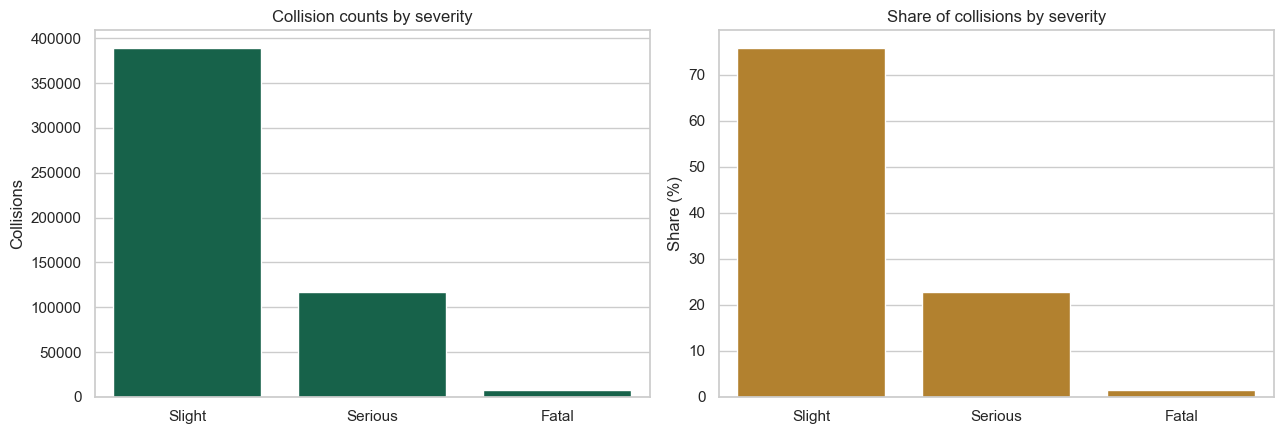

In [12]:
# ============================================================
# 4.2 VISUALIZE CLASS IMBALANCE
# Purpose:
# Show collision counts and percentages for Slight, Serious and Fatal outcomes to justify class-sensitive evaluation.
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = ['Slight', 'Serious', 'Fatal']

sns.barplot(
    data=severity_profile,
    x='Severity',
    y='Collisions',
    order=order,
    color='#0B6E4F',
    ax=axes[0],
)
axes[0].set_title('Collision counts by severity')
axes[0].set_xlabel('')
axes[0].ticklabel_format(style='plain', axis='y')

plot_share = severity_profile.copy()
plot_share['Percentage'] = plot_share['Share'] * 100
sns.barplot(
    data=plot_share,
    x='Severity',
    y='Percentage',
    order=order,
    color='#C88719',
    ax=axes[1],
)
axes[1].set_title('Share of collisions by severity')
axes[1].set_xlabel('')
axes[1].set_ylabel('Share (%)')

plt.tight_layout()
plt.show()


### Interpretation of output — 4.2

The two charts make the imbalance visually explicit: Slight collisions dominate both counts and percentage share, while Fatal cases are rare. This confirms that overall accuracy cannot be the main model-selection criterion.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

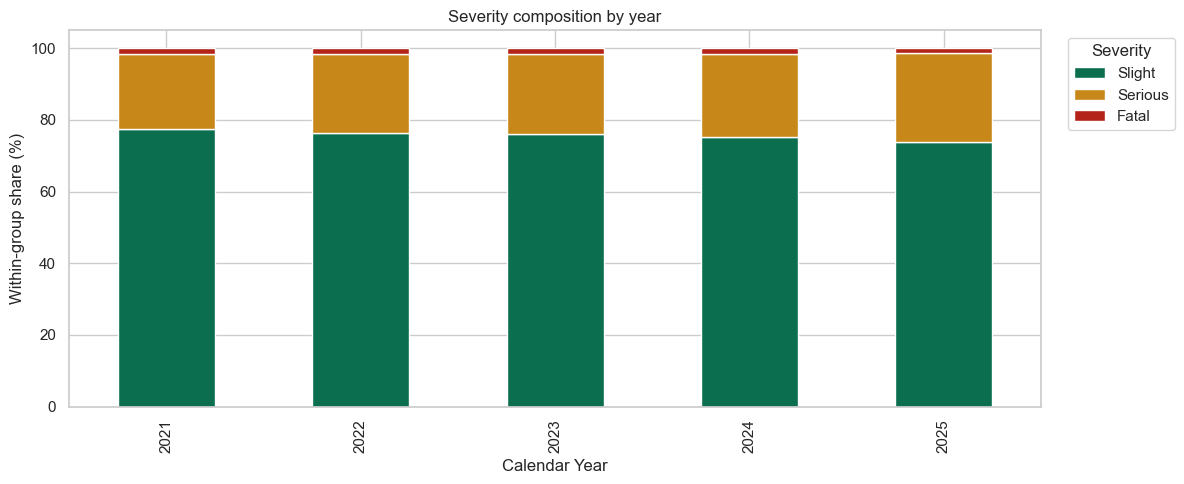

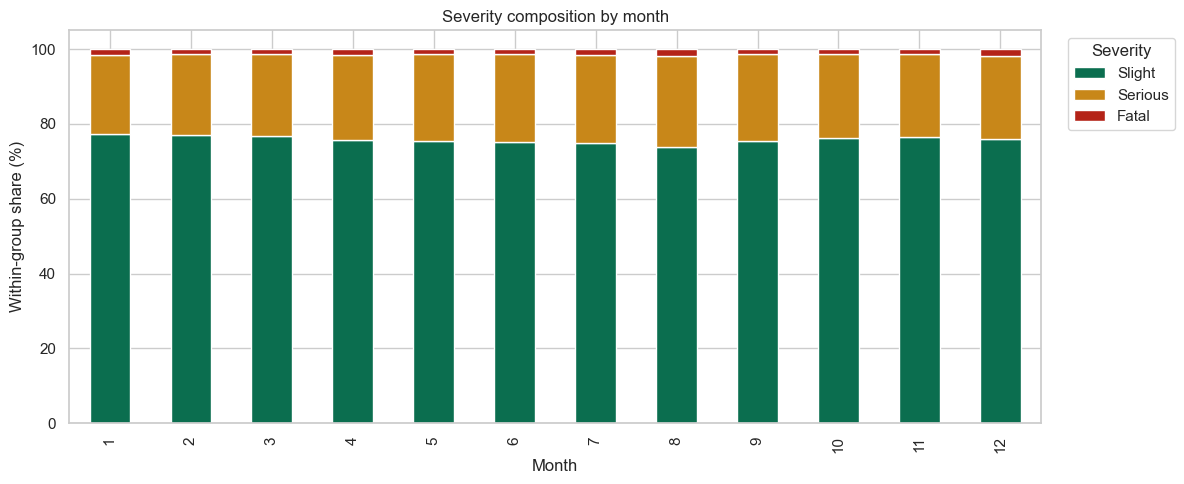

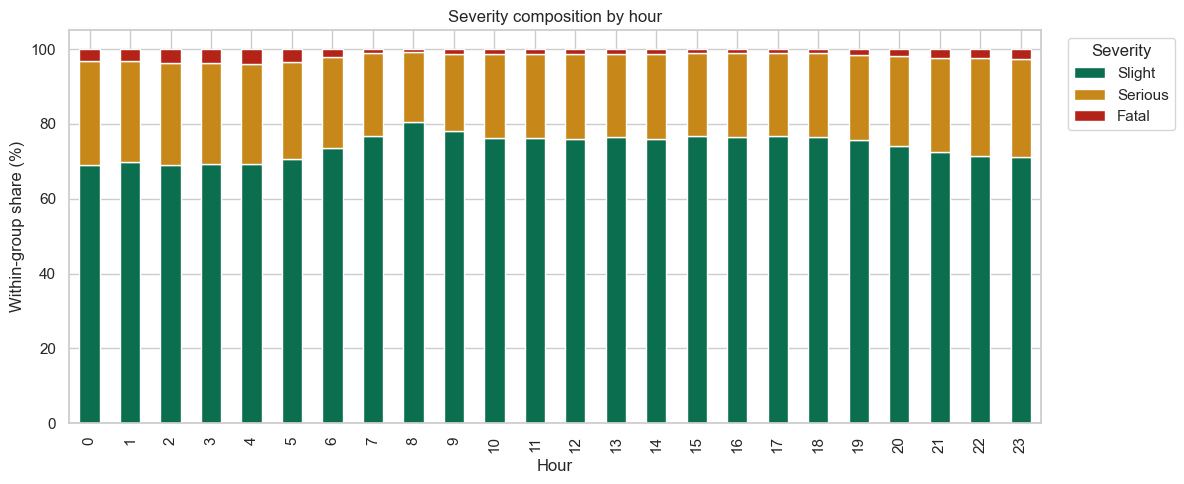

In [13]:
# ============================================================
# 4.3 EXPLORE TEMPORAL SEVERITY PATTERNS
# Purpose:
# Compare severity composition by year, month and hour. Use within-group percentages rather than raw counts alone.
# ============================================================

def severity_composition_plot(frame, variable, title, order_values=None):
    """Plot the percentage composition of severity within each category."""
    table = pd.crosstab(
        frame[variable],
        frame['severity_label'],
        normalize='index',
    ).mul(100)
    table = table.reindex(columns=['Slight', 'Serious', 'Fatal'])
    if order_values is not None:
        table = table.reindex(order_values).dropna(how='all')
    table.plot(
        kind='bar',
        stacked=True,
        figsize=(12, 5),
        color=['#0B6E4F', '#C88719', '#B42318'],
    )
    plt.title(title)
    plt.xlabel(variable.replace('_', ' ').title())
    plt.ylabel('Within-group share (%)')
    plt.legend(title='Severity', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

if 'calendar_year' in collisions.columns:
    severity_composition_plot(collisions, 'calendar_year', 'Severity composition by year')
if 'month' in collisions.columns:
    severity_composition_plot(collisions, 'month', 'Severity composition by month', range(1, 13))
if 'hour' in collisions.columns:
    severity_composition_plot(collisions, 'hour', 'Severity composition by hour', range(24))


### Interpretation of output — 4.3

The year, month and hour charts show how severity composition changes over time. The charts describe proportions among recorded collisions; they do not control for traffic volume, kilometres travelled or other exposure measures.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [14]:
# ============================================================
# 4.4 EXPLORE ROAD AND ENVIRONMENTAL SEVERITY PROFILES
# Purpose:
# Calculate Serious/Fatal shares for decoded road and environmental categories with at least 250 observations.
# ============================================================

def severe_rate_table(frame, variable, minimum_records=250):
    """Calculate the Serious/Fatal share for each category."""
    working = frame[[variable, 'severity_label']].copy()
    working['Severe'] = working['severity_label'].isin(['Serious', 'Fatal'])
    result = (
        working.groupby(variable, dropna=False)
        .agg(
            Collisions=('Severe', 'size'),
            Severe_collisions=('Severe', 'sum'),
            Severe_share=('Severe', 'mean'),
        )
        .reset_index()
    )
    result['Severe share (%)'] = result['Severe_share'] * 100
    return result.query('Collisions >= @minimum_records').sort_values(
        'Severe share (%)', ascending=False
    )

labelled_factors = [
    'road_type_label',
    'junction_detail_label',
    'light_conditions_label',
    'weather_conditions_label',
    'road_surface_conditions_label',
    'urban_or_rural_area_label',
]

for factor in labelled_factors:
    if factor not in collisions_decoded.columns:
        continue
    # Add the severity label and engineered target to the decoded copy.
    collisions_decoded['severity_label'] = collisions['severity_label']
    profile = severe_rate_table(collisions_decoded, factor)
    print('\n', factor.replace('_label', '').replace('_', ' ').title())
    display(profile.head(15))



 Road Type


,road_type_label,Collisions,Severe_collisions,Severe_share,Severe share (%)
3,Single carriageway,373065,96767,0.2594,25.9384
0,Dual carriageway,76119,17426,0.2289,22.8931
4,Slip road,8829,1584,0.1794,17.9409
1,One-way street,11550,2050,0.1775,17.7489
2,Roundabout,31178,5365,0.1721,17.2076
5,Unknown road type,13060,1174,0.0899,8.9893



 Junction Detail


,junction_detail_label,Collisions,Severe_collisions,Severe_share,Severe share (%)
3,Not at or within 20 metres of junction,252021,65078,0.2582,25.8225
5,Private drive or entrance,11147,2712,0.2433,24.3294
4,Other junction,31096,7564,0.2432,24.3247
6,T or staggered junction,142597,33502,0.2349,23.4942
0,Crossroads,47572,10869,0.2285,22.8475
2,More than four arms,7957,1808,0.2272,22.7221
1,Data missing or out of range,19982,2756,0.1379,13.7924
7,Unknown junction detail,1429,77,0.0539,5.3884



 Light Conditions


,light_conditions_label,Collisions,Severe_collisions,Severe_share,Severe share (%)
3,Darkness - no lighting,27438,9589,0.3495,34.9479
2,Darkness - lights unlit,3706,1080,0.2914,29.1419
1,Darkness - lights lit,105834,26578,0.2511,25.1129
5,Daylight,368193,85402,0.2319,23.1949
0,Darkness - lighting unknown,8596,1707,0.1986,19.8581


... (2 outputs left out)


 Road Surface Conditions


,road_surface_conditions_label,Collisions,Severe_collisions,Severe_share,Severe share (%)
2,Flood over 3 cm deep,788,215,0.2728,27.2843
6,Wet or damp,120572,30572,0.2536,25.3558
1,Dry,374268,90900,0.2429,24.2874
4,Snow,1257,289,0.2299,22.9912
3,Frost or ice,6668,1510,0.2265,22.6455
0,Data missing or out of range,3527,403,0.1143,11.4261
5,Unknown surface condition,6721,477,0.0710,7.0972



 Urban Or Rural Area


,urban_or_rural_area_label,Collisions,Severe_collisions,Severe_share,Severe share (%)
1,Rural,168429,49457,0.2936,29.3637
3,Urban,345314,74891,0.2169,21.6878


### Interpretation of output — 4.4

The road and environmental tables compare both collision volume and the Serious/Fatal share. Categories with fewer than 250 records were excluded, reducing the risk of interpreting unstable percentages from very small groups.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

## 4.5 Extended collision, vehicle and casualty exploration

The following analyses restore the wider descriptive coverage required for the project. Each table includes both volume and within-group severe-collision share.


 Speed Limit


,speed_limit,Collisions,Severe_collisions,Severe_share,Severe share (%)
5,60,62703,21628,0.3449,34.4928
4,50,22666,6425,0.2835,28.3464
3,40,44750,11495,0.2569,25.6872
6,70,28258,6956,0.2462,24.6160
2,30,267325,60547,0.2265,22.6492
1,20,88096,17314,0.1965,19.6536



 Light Conditions


,light_conditions,Collisions,Severe_collisions,Severe_share,Severe share (%)
4,6,27438,9589,0.3495,34.9479
3,5,3706,1080,0.2914,29.1419
2,4,105834,26578,0.2511,25.1129
1,1,368193,85402,0.2319,23.1949
5,7,8596,1707,0.1986,19.8581



 Weather Conditions


,weather_conditions,Collisions,Severe_collisions,Severe_share,Severe share (%)
4,4,4472,1330,0.2974,29.7406
7,7,2128,597,0.2805,28.0545
5,5,5173,1385,0.2677,26.7736
1,1,413632,102325,0.2474,24.7382
2,2,55834,13404,0.2401,24.0069
3,3,1791,406,0.2267,22.6689
8,8,15955,3164,0.1983,19.8308
9,9,14566,1707,0.1172,11.7191


... (2 outputs left out)


 Junction Detail


,junction_detail,Collisions,Severe_collisions,Severe_share,Severe share (%)
1,0,252021,65078,0.2582,25.8225
5,18,11147,2712,0.2433,24.3294
6,19,31096,7564,0.2432,24.3247
2,13,142597,33502,0.2349,23.4942
3,16,47572,10869,0.2285,22.8475
4,17,7957,1808,0.2272,22.7221
0,-1,19982,2756,0.1379,13.7924
7,99,1429,77,0.0539,5.3884



 Urban Or Rural Area


,urban_or_rural_area,Collisions,Severe_collisions,Severe_share,Severe share (%)
2,2,168429,49457,0.2936,29.3637
1,1,345314,74891,0.2169,21.6878


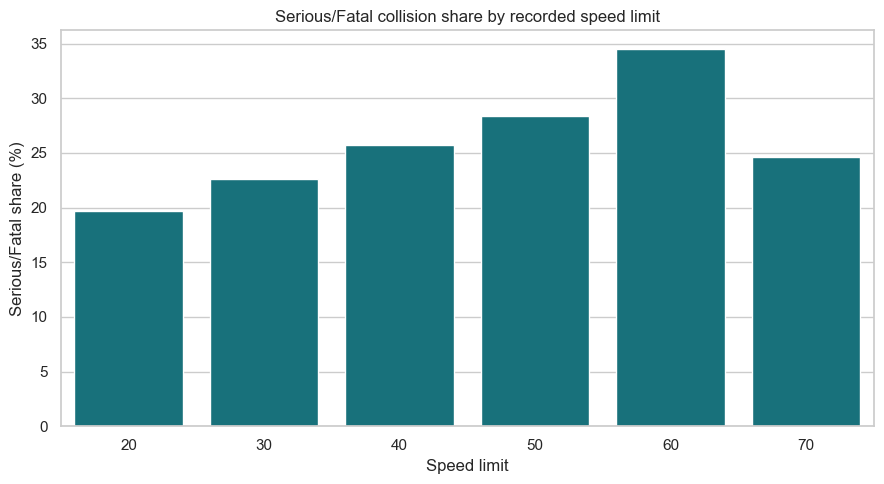

In [15]:
# ============================================================
# 4.5 EXPLORE SEVERITY BY SPEED, LIGHT, WEATHER AND ROAD SURFACE
# Purpose:
# Compare collision volume and the Serious/Fatal share across high-priority road and environmental characteristics.
# ============================================================
priority_eda_features = available(
    collisions,
    [
        'speed_limit',
        'light_conditions',
        'weather_conditions',
        'road_surface_conditions',
        'junction_detail',
        'urban_or_rural_area',
    ],
)

eda_profiles = {}
for feature in priority_eda_features:
    profile = severe_rate_table(
        collisions,
        feature,
        minimum_records=250,
    )
    eda_profiles[feature] = profile
    print('\n', feature.replace('_', ' ').title())
    display(profile.head(15))

# Create one management-friendly chart for the speed environment.
if 'speed_limit' in eda_profiles and not eda_profiles['speed_limit'].empty:
    plot_data = eda_profiles['speed_limit'].sort_values('speed_limit')
    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=plot_data,
        x='speed_limit',
        y='Severe share (%)',
        color='#087E8B',
    )
    plt.title('Serious/Fatal collision share by recorded speed limit')
    plt.xlabel('Speed limit')
    plt.ylabel('Serious/Fatal share (%)')
    plt.tight_layout()
    plt.show()


### Interpretation of output — 4.5

The most notable descriptive severe shares were **34.49% at recorded speed limit 60**, **29.36% in rural areas**, and **34.95% under darkness with no lighting**. These patterns justify deeper statistical and management review, but they are not causal findings.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [16]:
# ============================================================
# 4.6 EXPLORE DRIVER AND VEHICLE CHARACTERISTICS
# Purpose:
# Summarize driver age, vehicle age, vehicle type and vehicle manoeuvre before aggregation to collision level.
# ============================================================
vehicle_eda_rows = []
for feature in available(
    vehicles,
    ['vehicle_type', 'vehicle_manoeuvre', 'sex_of_driver', 'age_band_of_driver'],
):
    top = (
        vehicles[feature]
        .value_counts(dropna=False)
        .head(15)
        .rename_axis('Category')
        .reset_index(name='Vehicle records')
    )
    top.insert(0, 'Feature', feature)
    vehicle_eda_rows.append(top)

vehicle_eda = pd.concat(vehicle_eda_rows, ignore_index=True)
vehicle_eda.to_csv(OUTPUTS / 'vehicle_eda_top_categories.csv', index=False)
display(vehicle_eda)

for feature in available(vehicles, ['age_of_driver', 'age_of_vehicle']):
    numeric = pd.to_numeric(vehicles[feature], errors='coerce')
    numeric = numeric.mask(numeric < 0)
    print(feature, numeric.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(2).to_dict())


,Feature,Category,Vehicle records
0,vehicle_type,9,637681
1,vehicle_type,1,81486
2,vehicle_type,19,60309
3,vehicle_type,3,44795
4,vehicle_type,5,23011
5,vehicle_type,8,15362
6,vehicle_type,11,15100
7,vehicle_type,21,13247
8,vehicle_type,4,9590
9,vehicle_type,33,6901


age_of_driver {'count': 795025.0, 'mean': 41.2, 'std': 16.87, 'min': 1.0, '25%': 28.0, '50%': 39.0, '75%': 53.0, '90%': 65.0, 'max': 105.0}
age_of_vehicle {'count': 573978.0, 'mean': 8.59, 'std': 5.86, 'min': 0.0, '25%': 4.0, '50%': 8.0, '75%': 13.0, '90%': 16.0, 'max': 123.0}


### Interpretation of output — 4.6

The vehicle exploration shows the dominant vehicle types, manoeuvres, driver-sex categories and age bands in the vehicle table. These distributions explain the composition of the records later summarized to one row per collision.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [17]:
# ============================================================
# 4.7 EXPLORE CASUALTY CHARACTERISTICS
# Purpose:
# Summarize casualty class, age band, casualty type and sex before conducting casualty-level hypothesis tests.
# ============================================================
casualty_eda_rows = []
for feature in available(
    casualties,
    ['casualty_class', 'age_band_of_casualty', 'casualty_type', 'sex_of_casualty'],
):
    top = (
        casualties[feature]
        .value_counts(dropna=False)
        .head(20)
        .rename_axis('Category')
        .reset_index(name='Casualty records')
    )
    top.insert(0, 'Feature', feature)
    casualty_eda_rows.append(top)

casualty_eda = pd.concat(casualty_eda_rows, ignore_index=True)
casualty_eda.to_csv(OUTPUTS / 'casualty_eda_top_categories.csv', index=False)
display(casualty_eda)


,Feature,Category,Casualty records
0,casualty_class,1,432883
1,casualty_class,2,125540
2,casualty_class,3,94398
3,age_band_of_casualty,6,132804
4,age_band_of_casualty,7,100841
5,age_band_of_casualty,8,81997
6,age_band_of_casualty,5,70305
7,age_band_of_casualty,4,68000
8,age_band_of_casualty,9,64371
9,age_band_of_casualty,10,33977


### Interpretation of output — 4.7

The casualty exploration shows the dominant casualty classes, age bands, casualty types and sex categories. This provides context for H4, which is tested separately at casualty level rather than being used to predict collision severity.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [18]:
# ============================================================
# 4.8 GENERATE PLAIN-ENGLISH EDA FINDINGS
# Purpose:
# Convert key descriptive outputs into understandable evidence statements without making causal claims.
# ============================================================
severity_lookup = severity_profile.set_index('Severity')
eda_findings = []

for severity in ['Slight', 'Serious', 'Fatal']:
    if severity in severity_lookup.index:
        eda_findings.append(
            f"{severity} collisions represented "
            f"{severity_lookup.loc[severity, 'Share']:.1%} of the analysed collisions."
        )

if 'speed_limit' in eda_profiles and not eda_profiles['speed_limit'].empty:
    highest = eda_profiles['speed_limit'].iloc[0]
    eda_findings.append(
        f"Among speed-limit groups with at least 250 collisions, the highest "
        f"observed Serious/Fatal share occurred at code/value "
        f"{highest['speed_limit']} ({highest['Severe share (%)']:.1f}%)."
    )

for finding in eda_findings:
    print('•', finding)

print(
    '\nInterpretation rule: these are patterns among recorded collisions. '
    'They are not exposure-adjusted risks and do not prove causation.'
)


• Slight collisions represented 75.8% of the analysed collisions.
• Serious collisions represented 22.7% of the analysed collisions.
• Fatal collisions represented 1.5% of the analysed collisions.
• Among speed-limit groups with at least 250 collisions, the highest observed Serious/Fatal share occurred at code/value 60.0 (34.5%).

Interpretation rule: these are patterns among recorded collisions. They are not exposure-adjusted risks and do not prove causation.


### Interpretation of output — 4.8

The generated statements correctly translate the main descriptive evidence into plain English and retain the central limitation: the percentages describe reported collisions and are not exposure-adjusted road-risk rates.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

# 5. CRISP-DM Phase 2: Statistical Analysis and Hypothesis Testing

In [19]:
# ============================================================
# 5.1 DEFINE CHI-SQUARE AND CRAMER’S V FUNCTIONS
# Purpose:
# Test categorical association with severity and calculate an effect-size measure. Consolidate rare categories before testing.
# ============================================================

def collapse_rare(series, minimum_count=100):
    """Combine infrequent values to reduce unstable contingency cells."""
    cleaned = series.astype('string').fillna('Missing')
    counts = cleaned.value_counts()
    rare_values = counts[counts < minimum_count].index
    return cleaned.where(~cleaned.isin(rare_values), 'Other or rare')


def cramers_v(contingency_table):
    """Calculate bias-corrected Cramer's V."""
    chi_square = chi2_contingency(contingency_table, correction=False)[0]
    sample_size = contingency_table.to_numpy().sum()
    rows, columns = contingency_table.shape
    phi_squared = chi_square / sample_size
    corrected_phi = max(
        0,
        phi_squared - ((columns - 1) * (rows - 1)) / (sample_size - 1),
    )
    corrected_rows = rows - ((rows - 1) ** 2) / (sample_size - 1)
    corrected_columns = columns - ((columns - 1) ** 2) / (sample_size - 1)
    denominator = min(corrected_rows - 1, corrected_columns - 1)
    return math.sqrt(corrected_phi / denominator) if denominator > 0 else np.nan


def screen_associations(frame, predictors, target):
    """Run Chi-square and Cramer's V for a list of categorical predictors."""
    rows = []
    for predictor in predictors:
        if predictor not in frame.columns or frame[predictor].nunique(dropna=True) < 2:
            continue
        valid = frame[target].notna()
        table = pd.crosstab(
            collapse_rare(frame.loc[valid, predictor]),
            frame.loc[valid, target],
        )
        chi_square, p_value, degrees, expected = chi2_contingency(table)
        rows.append(
            {
                'Predictor': predictor,
                'Records': int(table.to_numpy().sum()),
                'Chi-square': chi_square,
                'Degrees of freedom': degrees,
                'P-value': p_value,
                'Cramer V': cramers_v(table),
                'Minimum expected count': float(expected.min()),
                'Expected cells below five (%)': float((expected < 5).mean() * 100),
            }
        )
    return pd.DataFrame(rows).sort_values(['Cramer V', 'P-value'], ascending=[False, True])


### Interpretation of output — 5.1

The test functions apply one method consistently: categories with fewer than 100 observations are combined, Chi-square tests independence, and bias-corrected Cramér’s V reports association strength.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [20]:
# ============================================================
# 5.2 TEST ROAD/ENVIRONMENT AND TEMPORAL HYPOTHESES
# Purpose:
# Run association screening for H1 and H3, save the results and show the strongest relationships.
# ============================================================

ROAD_ENVIRONMENT_FEATURES = available(
    collisions,
    [
        'road_type', 'speed_limit', 'junction_detail', 'junction_control',
        'light_conditions', 'weather_conditions', 'road_surface_conditions',
        'special_conditions_at_site', 'carriageway_hazards',
        'urban_or_rural_area', 'trunk_road_flag', 'first_road_class',
        'second_road_class',
    ],
)
TEMPORAL_FEATURES = available(
    collisions,
    ['day_of_week', 'month', 'hour', 'time_band', 'weekend_flag', 'calendar_year'],
)

h1_results = screen_associations(
    collisions, ROAD_ENVIRONMENT_FEATURES, 'severity_label'
)
h3_results = screen_associations(
    collisions, TEMPORAL_FEATURES, 'severity_label'
)

h1_results.to_csv(OUTPUTS / 'H1_road_environment.csv', index=False)
h3_results.to_csv(OUTPUTS / 'H3_temporal.csv', index=False)

print('H1: Road and environmental factors')
display(h1_results.head(15))
print('H3: Temporal factors')
display(h3_results)


H1: Road and environmental factors


,Predictor,Records,Chi-square,Degrees of freedom,P-value,Cramer V,Minimum expected count,Expected cells below five (%)
1,speed_limit,513801,"8,409.3468",12,0.0000,0.0904,0.0441,14.2857
9,urban_or_rural_area,513801,"5,640.0175",4,0.0000,0.0741,0.8526,11.1111
3,junction_control,513801,"5,103.6752",10,0.0000,0.0704,32.4875,0.0000
10,trunk_road_flag,513801,"4,386.6643",4,0.0000,0.0653,482.5943,0.0000
0,road_type,513801,"3,970.3568",10,0.0000,0.0621,129.7885,0.0000
4,light_conditions,513801,"3,700.1915",10,0.0000,0.0599,0.4998,5.5556
12,second_road_class,513801,"3,020.9953",16,0.0000,0.0541,0.7056,7.4074
7,special_conditions_at_site,513801,"2,837.0363",18,0.0000,0.0524,2.7048,3.3333
2,junction_detail,513801,"2,716.0419",14,0.0000,0.0513,21.0066,0.0000
8,carriageway_hazards,513801,"2,206.2492",26,0.0000,0.0461,9.0406,0.0000


H3: Temporal factors


,Predictor,Records,Chi-square,Degrees of freedom,P-value,Cramer V,Minimum expected count,Expected cells below five (%)
2,hour,513801,"2,573.0932",46,0.0000,0.0496,46.1294,0.0000
3,time_band,513801,"2,161.0979",8,0.0000,0.0458,429.0413,0.0000
4,weekend_flag,513801,639.7162,2,0.0000,0.0352,"1,886.9086",0.0000
0,day_of_week,513801,685.7590,12,0.0000,0.0256,849.3948,0.0000
5,calendar_year,513801,471.7544,8,0.0000,0.0212,"1,483.6515",0.0000
1,month,513801,285.5771,22,0.0000,0.0160,517.1399,0.0000


### Interpretation of output — 5.2

All **13 road/environment predictors** and all **6 temporal predictors** were statistically significant. The strongest road/environment effects were speed limit (**V=0.0904**), urban/rural area (**V=0.0741**) and junction control (**V=0.0704**). These are modest effects despite very small p-values, reflecting the large sample size.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

## 5.3 Effect sizes, residuals and numeric-group tests

P-values are interpreted together with effect sizes. Significant contingency tables are examined using standardized residuals, while continuous variables are tested with Kruskal-Wallis and corrected pairwise Mann-Whitney tests.

In [21]:
# ============================================================
# 5.3 APPLY BENJAMINI-HOCHBERG MULTIPLE-TEST CORRECTION
# Purpose:
# Control the false-discovery rate across each family of hypothesis tests rather than interpreting every p-value independently.
# ============================================================
def benjamini_hochberg(p_values):
    """Return Benjamini-Hochberg adjusted p-values."""
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    ranked = p_values[order]
    adjusted = ranked * len(ranked) / np.arange(1, len(ranked) + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)
    output = np.empty_like(adjusted)
    output[order] = adjusted
    return output

for result_name, result_table in {
    'H1': h1_results,
    'H3': h3_results,
}.items():
    result_table['Adjusted P-value'] = benjamini_hochberg(
        result_table['P-value']
    )
    result_table['Significant after correction'] = (
        result_table['Adjusted P-value'] < ALPHA
    )
    print(result_name)
    display(
        result_table[
            ['Predictor', 'Cramer V', 'P-value', 'Adjusted P-value',
             'Significant after correction']
        ]
    )


H1


,Predictor,Cramer V,P-value,Adjusted P-value,Significant after correction
1,speed_limit,0.0904,0.0000,0.0000,True
9,urban_or_rural_area,0.0741,0.0000,0.0000,True
3,junction_control,0.0704,0.0000,0.0000,True
10,trunk_road_flag,0.0653,0.0000,0.0000,True
0,road_type,0.0621,0.0000,0.0000,True
4,light_conditions,0.0599,0.0000,0.0000,True
12,second_road_class,0.0541,0.0000,0.0000,True
7,special_conditions_at_site,0.0524,0.0000,0.0000,True
2,junction_detail,0.0513,0.0000,0.0000,True
8,carriageway_hazards,0.0461,0.0000,0.0000,True


H3


,Predictor,Cramer V,P-value,Adjusted P-value,Significant after correction
2,hour,0.0496,0.0000,0.0000,True
3,time_band,0.0458,0.0000,0.0000,True
4,weekend_flag,0.0352,0.0000,0.0000,True
0,day_of_week,0.0256,0.0000,0.0000,True
5,calendar_year,0.0212,0.0000,0.0000,True
1,month,0.0160,0.0000,0.0000,True


### Interpretation of output — 5.3

The Benjamini-Hochberg correction confirmed which H1 and H3 findings remained significant after controlling the false-discovery rate. The corrected decisions are more reliable than interpreting each raw p-value independently.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [22]:
# ============================================================
# 5.4 CALCULATE STANDARDIZED RESIDUALS
# Purpose:
# Identify the severity/category combinations contributing most strongly to significant Chi-square relationships.
# ============================================================
def standardized_residuals(frame, predictor, target):
    """Return standardized residuals for one contingency table."""
    table = pd.crosstab(
        collapse_rare(frame[predictor]),
        frame[target],
    )
    _, _, _, expected = chi2_contingency(table)
    residuals = (table - expected) / np.sqrt(expected)
    output = (
        residuals.stack()
        .rename('Standardized residual')
        .reset_index()
        .sort_values(
            'Standardized residual',
            key=lambda series: series.abs(),
            ascending=False,
        )
    )
    output.columns = [predictor, target, 'Standardized residual']
    return output

strongest_h1_predictors = h1_results.head(3)['Predictor'].tolist()
residual_outputs = []
for predictor in strongest_h1_predictors:
    residual_table = standardized_residuals(
        collisions,
        predictor,
        'severity_label',
    ).head(20)
    residual_table.insert(0, 'Predictor', predictor)
    residual_outputs.append(residual_table)

standardized_residual_output = pd.concat(
    residual_outputs,
    ignore_index=True,
)
standardized_residual_output.to_csv(
    OUTPUTS / 'standardized_residuals_top_associations.csv',
    index=False,
)
display(standardized_residual_output)


,Predictor,speed_limit,severity_label,Standardized residual,urban_or_rural_area,junction_control
0,speed_limit,60,Fatal,48.9866,<NA>,<NA>
1,speed_limit,60,Serious,41.5709,<NA>,<NA>
2,speed_limit,60,Slight,-29.5898,<NA>,<NA>
3,speed_limit,70,Fatal,26.2789,<NA>,<NA>
4,speed_limit,30,Fatal,-25.5990,<NA>,<NA>
5,speed_limit,20,Fatal,-24.5934,<NA>,<NA>
6,speed_limit,20,Serious,-22.0790,<NA>,<NA>
7,speed_limit,50,Fatal,17.5748,<NA>,<NA>
8,speed_limit,20,Slight,15.5173,<NA>,<NA>
9,speed_limit,30,Serious,-10.3619,<NA>,<NA>


### Interpretation of output — 5.4

The standardized-residual output identifies the specific category/severity combinations driving the strongest Chi-square results. Large positive residuals indicate combinations observed more often than expected under independence; large negative values indicate under-representation.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [23]:
# ============================================================
# 5.5 TEST NUMERIC VARIABLES ACROSS SEVERITY GROUPS
# Purpose:
# Use Kruskal-Wallis tests for numeric variables whose distributions may not satisfy normality, then calculate eta-squared style rank effect estimates.
# ============================================================
numeric_test_features = available(
    collisions,
    ['speed_limit', 'hour', 'number_of_vehicles'],
)

numeric_test_rows = []
for feature in numeric_test_features:
    working = collisions[[feature, 'severity_label']].dropna().copy()
    groups = [
        pd.to_numeric(
            working.loc[working['severity_label'] == severity, feature],
            errors='coerce',
        ).dropna()
        for severity in ['Slight', 'Serious', 'Fatal']
    ]
    groups = [group for group in groups if len(group) > 0]
    statistic, p_value = kruskal(*groups)
    sample_size = sum(len(group) for group in groups)
    effect = max(
        0,
        (statistic - len(groups) + 1) / (sample_size - len(groups)),
    )
    numeric_test_rows.append(
        {
            'Predictor': feature,
            'Kruskal-Wallis statistic': statistic,
            'P-value': p_value,
            'Effect estimate': effect,
            'Records': sample_size,
        }
    )

numeric_tests = pd.DataFrame(numeric_test_rows)
numeric_tests['Adjusted P-value'] = benjamini_hochberg(
    numeric_tests['P-value']
)
numeric_tests.to_csv(
    OUTPUTS / 'numeric_severity_group_tests.csv',
    index=False,
)
display(numeric_tests)


,Predictor,Kruskal-Wallis statistic,P-value,Effect estimate,Records,Adjusted P-value
0,speed_limit,"6,163.2907",0.0000,0.0120,513801,0.0000
1,hour,68.6897,0.0000,0.0001,513801,0.0000
2,number_of_vehicles,"4,376.3670",0.0000,0.0085,513801,0.0000


### Interpretation of output — 5.5

The Kruskal-Wallis tests found statistically significant differences across severity groups for the tested numeric characteristics. The accompanying effect estimates are essential because a large dataset can produce small p-values even where practical differences are limited.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [24]:
# ============================================================
# 5.6 RUN CORRECTED PAIRWISE POST-HOC TESTS
# Purpose:
# For numeric variables with a significant overall test, compare severity pairs using Mann-Whitney tests and Benjamini-Hochberg correction.
# ============================================================
pairwise_rows = []
severity_pairs = [
    ('Slight', 'Serious'),
    ('Slight', 'Fatal'),
    ('Serious', 'Fatal'),
]

for feature in numeric_tests.loc[
    numeric_tests['Adjusted P-value'] < ALPHA,
    'Predictor',
]:
    for first_severity, second_severity in severity_pairs:
        first = pd.to_numeric(
            collisions.loc[
                collisions['severity_label'] == first_severity,
                feature,
            ],
            errors='coerce',
        ).dropna()
        second = pd.to_numeric(
            collisions.loc[
                collisions['severity_label'] == second_severity,
                feature,
            ],
            errors='coerce',
        ).dropna()
        statistic, p_value = mannwhitneyu(
            first,
            second,
            alternative='two-sided',
        )
        pairwise_rows.append(
            {
                'Predictor': feature,
                'Comparison': f'{first_severity} vs {second_severity}',
                'Statistic': statistic,
                'P-value': p_value,
                'First median': float(first.median()),
                'Second median': float(second.median()),
            }
        )

pairwise_tests = pd.DataFrame(pairwise_rows)
if not pairwise_tests.empty:
    pairwise_tests['Adjusted P-value'] = benjamini_hochberg(
        pairwise_tests['P-value']
    )
    pairwise_tests['Significant after correction'] = (
        pairwise_tests['Adjusted P-value'] < ALPHA
    )
    pairwise_tests.to_csv(
        OUTPUTS / 'numeric_pairwise_posthoc_tests.csv',
        index=False,
    )
    display(pairwise_tests)


,Predictor,Comparison,Statistic,P-value,First median,Second median,Adjusted P-value,Significant after correction
0,speed_limit,Slight vs Serious,"20,811,282,884.5000",0.0000,30.0000,30.0000,0.0000,True
1,speed_limit,Slight vs Fatal,"879,244,573.5000",0.0000,30.0000,50.0000,0.0000,True
2,speed_limit,Serious vs Fatal,"297,102,708.0000",0.0000,30.0000,50.0000,0.0000,True
3,hour,Slight vs Serious,"22,390,085,875.0000",0.0000,14.0000,15.0000,0.0000,True
4,hour,Slight vs Fatal,"1,483,011,735.0000",0.2112,14.0000,14.0000,0.2112,False
5,hour,Serious vs Fatal,"450,640,915.0000",0.0017,15.0000,14.0000,0.0019,True
6,number_of_vehicles,Slight vs Serious,"25,154,517,795.0000",0.0000,2.0000,2.0000,0.0000,True
7,number_of_vehicles,Slight vs Fatal,"1,646,889,789.0000",0.0000,2.0000,2.0000,0.0000,True
8,number_of_vehicles,Serious vs Fatal,"450,383,787.0000",0.0006,2.0000,2.0000,0.0008,True


### Interpretation of output — 5.6

The pairwise Mann-Whitney comparisons show which severity pairs differ after a significant overall numeric test. Adjusted p-values protect the analysis from overstating evidence created by repeated comparisons.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

# 6. CRISP-DM Phase 3: Data Preparation

In [25]:
# ============================================================
# 6.1 AGGREGATE VEHICLE RECORDS TO COLLISION LEVEL
# Purpose:
# Create one collision-level vehicle summary so multi-vehicle collisions do not duplicate the target outcome.
# ============================================================

vehicle_work = vehicles.copy()
vehicle_work[VEHICLE_COLLISION_ID] = vehicle_work[VEHICLE_COLLISION_ID].astype(str)
collisions[COLLISION_ID] = collisions[COLLISION_ID].astype(str)


def clean_numeric_code(series):
    """Convert a numeric field and treat negative administrative codes as missing."""
    numeric = pd.to_numeric(series, errors='coerce')
    return numeric.mask(numeric < 0)

aggregation_rules = {}
for source, output_name, method in [
    ('age_of_driver', 'driver_age_mean', 'mean'),
    ('age_of_driver', 'driver_age_min', 'min'),
    ('age_of_vehicle', 'vehicle_age_mean', 'mean'),
    ('age_of_vehicle', 'vehicle_age_max', 'max'),
    ('engine_capacity_cc', 'engine_cc_mean', 'mean'),
]:
    if source in vehicle_work.columns:
        cleaned_column = f'{source}_clean'
        vehicle_work[cleaned_column] = clean_numeric_code(vehicle_work[source])
        aggregation_rules[output_name] = (cleaned_column, method)

for source, output_name in [
    ('vehicle_type', 'vehicle_type_first'),
    ('sex_of_driver', 'driver_sex_first'),
    ('vehicle_manoeuvre', 'vehicle_manoeuvre_first'),
]:
    if source in vehicle_work.columns:
        aggregation_rules[output_name] = (source, 'first')

vehicle_summary = (
    vehicle_work.groupby(VEHICLE_COLLISION_ID)
    .agg(**aggregation_rules)
    .reset_index()
    .rename(columns={VEHICLE_COLLISION_ID: COLLISION_ID})
)

vehicle_counts = (
    vehicle_work.groupby(VEHICLE_COLLISION_ID)
    .size()
    .rename('vehicle_records_count')
    .reset_index()
    .rename(columns={VEHICLE_COLLISION_ID: COLLISION_ID})
)

vehicle_type_numeric = pd.to_numeric(
    vehicle_work.get('vehicle_type', pd.Series(index=vehicle_work.index, dtype=float)),
    errors='coerce',
)
vehicle_type_rows = vehicle_work.assign(vehicle_type_code=vehicle_type_numeric)
vehicle_type_rows = vehicle_type_rows.loc[
    vehicle_type_rows['vehicle_type_code'].notna()
    & vehicle_type_rows['vehicle_type_code'].ge(0),
    [VEHICLE_COLLISION_ID, 'vehicle_type_code'],
]
vehicle_type_counts = (
    vehicle_type_rows.groupby(
        [VEHICLE_COLLISION_ID, 'vehicle_type_code'],
        observed=True,
    )
    .size()
    .unstack('vehicle_type_code', fill_value=0)
    .rename(columns=lambda code: f'vehicle_type_count_{int(code)}')
    .reset_index()
    .rename(columns={VEHICLE_COLLISION_ID: COLLISION_ID})
)

vehicle_type_codes = vehicle_type_numeric.fillna(-1)
vehicle_work['motorcycle_involved'] = vehicle_type_codes.isin(
    [2, 3, 4, 5, 23, 97]
).astype(int)
vehicle_work['goods_vehicle_involved'] = vehicle_type_codes.isin(
    [19, 20, 21]
).astype(int)
vehicle_indicator_summary = (
    vehicle_work.groupby(VEHICLE_COLLISION_ID)
    .agg(
        motorcycle_involved=('motorcycle_involved', 'max'),
        goods_vehicle_involved=('goods_vehicle_involved', 'max'),
    )
    .reset_index()
    .rename(columns={VEHICLE_COLLISION_ID: COLLISION_ID})
)

vehicle_summary = vehicle_summary.merge(
    vehicle_counts,
    on=COLLISION_ID,
    how='outer',
    validate='one_to_one',
)
vehicle_summary = vehicle_summary.merge(
    vehicle_type_counts,
    on=COLLISION_ID,
    how='outer',
    validate='one_to_one',
).merge(
    vehicle_indicator_summary,
    on=COLLISION_ID,
    how='outer',
    validate='one_to_one',
)

casualty_work = casualties.copy()
casualty_work[CASUALTY_COLLISION_ID] = (
    casualty_work[CASUALTY_COLLISION_ID].astype(str)
)
casualty_type_numeric = pd.to_numeric(
    casualty_work.get(
        'casualty_type',
        pd.Series(index=casualty_work.index, dtype=float),
    ),
    errors='coerce',
)
casualty_class_numeric = pd.to_numeric(
    casualty_work.get(
        'casualty_class',
        pd.Series(index=casualty_work.index, dtype=float),
    ),
    errors='coerce',
)
casualty_work['vulnerable_road_user_record'] = (
    casualty_class_numeric.eq(3)
    | casualty_type_numeric.isin([0, 1, 2, 3, 4, 5, 16, 22, 23, 97])
).astype(int)
casualty_summary = (
    casualty_work.groupby(CASUALTY_COLLISION_ID)
    .agg(vulnerable_road_user_count=('vulnerable_road_user_record', 'sum'))
    .reset_index()
    .rename(columns={CASUALTY_COLLISION_ID: COLLISION_ID})
)
casualty_summary['vulnerable_road_user_involved'] = (
    casualty_summary['vulnerable_road_user_count'].gt(0).astype(int)
)

analysis = collisions.merge(
    vehicle_summary,
    on=COLLISION_ID,
    how='left',
    validate='one_to_one',
).merge(
    casualty_summary,
    on=COLLISION_ID,
    how='left',
    validate='one_to_one',
)

print(f'Collision rows before integration: {len(collisions):,}')
print(f'Collision rows after integration : {len(analysis):,}')


Collision rows before integration: 513,801
Collision rows after integration : 513,801


### Interpretation of output - 6.1

The collision-level table now summarizes the maximum vehicle age, counts of each observed non-negative STATS19 vehicle-type code, motorcycle/goods-vehicle involvement, and vulnerable-road-user casualty counts. Vulnerable road users are flagged from pedestrian casualty class or designated pedestrian, cycle, powered two-wheeler, horse-rider and mobility-scooter type codes. No casualty severity field is aggregated into the predictors.

**Project implication:** These collision-level summaries replace reliance on first-vehicle details alone and can support error-segment analysis.

**Interpretation boundary:** The summaries describe recorded participants in a collision; they do not represent traffic exposure or establish causal effects.


In [26]:
# ============================================================
# 6.2 TEST DRIVER/VEHICLE AND CASUALTY HYPOTHESES
# Purpose:
# Test H2 using collision-level vehicle summaries and H4 using the separate casualty-level outcome.
# ============================================================

h2_features = available(
    analysis,
    ['vehicle_type_first', 'driver_sex_first', 'vehicle_manoeuvre_first'],
)
h2_results = screen_associations(analysis, h2_features, 'severity_label')
h2_results.to_csv(OUTPUTS / 'H2_driver_vehicle.csv', index=False)

casualties['casualty_severity_label'] = (
    pd.to_numeric(casualties[CASUALTY_TARGET], errors='coerce')
    .map(SEVERITY_MAP)
)
casualty_features = available(
    casualties,
    [
        'casualty_class', 'sex_of_casualty', 'age_band_of_casualty',
        'casualty_type', 'casualty_home_area_type', 'casualty_imd_decile',
        'pedestrian_location', 'pedestrian_movement', 'car_passenger',
        'bus_or_coach_passenger',
    ],
)
h4_results = screen_associations(
    casualties, casualty_features, 'casualty_severity_label'
)
h4_results.to_csv(OUTPUTS / 'H4_casualty.csv', index=False)

print('H2: Driver and vehicle factors')
display(h2_results)
print('H4: Casualty factors')
display(h4_results.head(15))


H2: Driver and vehicle factors


,Predictor,Records,Chi-square,Degrees of freedom,P-value,Cramer V,Minimum expected count,Expected cells below five (%)
2,vehicle_manoeuvre_first,513801,"14,217.6594",36,0.0000,0.1175,5.4538,0.0000
0,vehicle_type_first,513801,"12,080.2346",42,0.0000,0.1082,2.2491,4.5455
1,driver_sex_first,513801,"4,717.0402",6,0.0000,0.0677,44.1595,0.0000


H4: Casualty factors


,Predictor,Records,Chi-square,Degrees of freedom,P-value,Cramer V,Minimum expected count,Expected cells below five (%)
3,casualty_type,652821,"34,000.9640",42,0.0000,0.1613,1.6735,4.5455
2,age_band_of_casualty,652821,"10,057.1547",22,0.0000,0.0877,128.2064,0.0000
5,pedestrian_location,652821,"7,517.9708",22,0.0000,0.0758,0.6768,8.3333
6,pedestrian_movement,652821,"7,371.6222",20,0.0000,0.0750,0.6399,3.0303
0,casualty_class,652821,"7,203.9033",4,0.0000,0.0743,"1,161.5728",0.0000
1,sex_of_casualty,652821,"4,752.7431",6,0.0000,0.0603,1.5874,8.3333
7,car_passenger,652821,"1,880.6623",8,0.0000,0.0379,8.3551,0.0000
4,casualty_imd_decile,652821,793.8044,20,0.0000,0.0243,478.6544,0.0000
8,bus_or_coach_passenger,652821,428.2119,12,0.0000,0.0179,1.3166,4.7619


### Interpretation of output — 6.2

All **3 driver/vehicle predictors** and all **9 casualty predictors** were statistically significant. The strongest reported H4 association was casualty type with **Cramér’s V=0.1613**, which is stronger than the individual road/environment effects but still not causal evidence.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [27]:
# ============================================================
# 6.2A CREATE THE CONSOLIDATED HYPOTHESIS REGISTER
# Purpose:
# Summarize H1 to H4 with tested variables, significant variables, strongest effect and a plain-English decision.
# ============================================================
def hypothesis_row(label, results):
    """Create one evidence-register row from a result table."""
    if results.empty:
        return {
            'Hypothesis': label,
            'Variables tested': 0,
            'Significant variables': 0,
            'Strongest predictor': None,
            'Largest Cramer V': np.nan,
            'Decision': 'Insufficient data',
        }
    p_column = (
        'Adjusted P-value'
        if 'Adjusted P-value' in results.columns
        else 'P-value'
    )
    significant = results[results[p_column] < ALPHA]
    strongest = results.sort_values('Cramer V', ascending=False).iloc[0]
    return {
        'Hypothesis': label,
        'Variables tested': len(results),
        'Significant variables': len(significant),
        'Strongest predictor': strongest['Predictor'],
        'Largest Cramer V': strongest['Cramer V'],
        'Decision': (
            'Evidence of association'
            if len(significant)
            else 'No evidence after correction'
        ),
    }

hypothesis_register = pd.DataFrame([
    hypothesis_row('H1 Road and environment', h1_results),
    hypothesis_row('H2 Driver and vehicle', h2_results),
    hypothesis_row('H3 Temporal characteristics', h3_results),
    hypothesis_row('H4 Casualty characteristics', h4_results),
])
hypothesis_register.to_csv(
    OUTPUTS / 'hypothesis_evidence_register.csv',
    index=False,
)
display(hypothesis_register)


,Hypothesis,Variables tested,Significant variables,Strongest predictor,Largest Cramer V,Decision
0,H1 Road and environment,13,13,speed_limit,0.0904,Evidence of association
1,H2 Driver and vehicle,3,3,vehicle_manoeuvre_first,0.1175,Evidence of association
2,H3 Temporal characteristics,6,6,hour,0.0496,Evidence of association
3,H4 Casualty characteristics,9,9,casualty_type,0.1613,Evidence of association


### Interpretation of output — 6.2A

The consolidated register recorded evidence of association for H1 through H4: **13/13, 3/3, 6/6 and 9/9** variables respectively. The register appropriately separates statistical evidence from causal interpretation.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [28]:
# ============================================================
# 6.3 BUILD THE LEAKAGE-CONTROLLED MODELLING TABLE
# Purpose:
# Select predictors available for modelling, remove identifiers and outcome-derived fields, and assert that no obvious target leakage remains.
# ============================================================

CANDIDATE_FEATURES = [
    'road_type', 'speed_limit', 'junction_detail', 'junction_control',
    'pedestrian_crossing_human_control',
    'pedestrian_crossing_physical_facilities',
    'light_conditions', 'weather_conditions', 'road_surface_conditions',
    'special_conditions_at_site', 'carriageway_hazards',
    'urban_or_rural_area', 'trunk_road_flag', 'first_road_class',
    'second_road_class', 'day_of_week', 'month', 'hour', 'time_band',
    'weekend_flag', 'number_of_vehicles', 'driver_age_mean',
    'driver_age_min', 'vehicle_age_mean', 'engine_cc_mean',
    'vehicle_type_first', 'driver_sex_first',
    'vehicle_manoeuvre_first', 'vehicle_records_count',
    'vehicle_age_max', 'motorcycle_involved', 'goods_vehicle_involved',
    'vulnerable_road_user_count', 'vulnerable_road_user_involved',
]
features = available(analysis, CANDIDATE_FEATURES)

LEAKAGE_TERMS = [
    'severity', 'fatal', 'serious', 'adjustment',
    'number_of_casualties', 'hospital', 'response_time',
]
BLOCKED_FIELDS = {
    COLLISION_ID, 'date', 'time', 'longitude', 'latitude',
    'location_easting_osgr', 'location_northing_osgr',
    'lsoa_of_accident_location',
}

features = [
    feature
    for feature in dict.fromkeys(features)
    if feature not in BLOCKED_FIELDS
    and not any(term in feature for term in LEAKAGE_TERMS)
]

model_data = analysis[features + ['severity_label']].copy()
model_data = model_data[
    model_data['severity_label'].isin(['Slight', 'Serious', 'Fatal'])
].copy()
features = [
    feature
    for feature in features
    if model_data[feature].nunique(dropna=False) > 1
]
model_data = model_data[features + ['severity_label']]

assert not any(
    any(term in feature for term in LEAKAGE_TERMS)
    for feature in features
), 'A named target-leakage field survived feature selection.'

print(f'Modelling records : {len(model_data):,}')
print(f'Predictor count   : {len(features):,}')
display(pd.DataFrame({'Selected predictor': features}))


Modelling records : 513,801
Predictor count   : 32


,Selected predictor
0,road_type
1,speed_limit
2,junction_detail
3,junction_control
4,light_conditions
5,weather_conditions
6,road_surface_conditions
7,special_conditions_at_site
8,carriageway_hazards
9,urban_or_rural_area


### Interpretation of output - 6.3

The leakage-controlled model table includes the additional vehicle-type counts and collision-level involvement summaries. Identifiers, coordinates and outcome-derived fields remain excluded. The code displays the live record and predictor counts after preparation.

**Project implication:** All expanded experiments use the same prepared collision-level predictors.

**Interpretation boundary:** Vehicle/casualty summaries are post-collision characteristics and support severity classification conditional on a recorded collision, not collision-occurrence prediction.


In [29]:
# ============================================================
# 6.4 SPLIT DATA AND ASSIGN SEMANTIC FEATURE TYPES
# Purpose:
# Create a stratified training/test split and assign coded category fields to the categorical pipeline based on meaning, not storage dtype.
# ============================================================

X = model_data[features].copy()
y = model_data['severity_label'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)
Xtr, Xte, ytr, yte = X_train, X_test, y_train, y_test

EXPLICIT_CATEGORICAL = [
    'road_type', 'junction_detail', 'junction_control',
    'pedestrian_crossing_human_control',
    'pedestrian_crossing_physical_facilities', 'light_conditions',
    'weather_conditions', 'road_surface_conditions',
    'special_conditions_at_site', 'carriageway_hazards',
    'urban_or_rural_area', 'trunk_road_flag', 'first_road_class',
    'second_road_class', 'day_of_week', 'month', 'time_band',
    'vehicle_type_first', 'driver_sex_first', 'vehicle_manoeuvre_first',
]
EXPLICIT_NUMERIC = [
    'speed_limit', 'hour', 'weekend_flag', 'number_of_vehicles',
    'driver_age_mean', 'driver_age_min', 'vehicle_age_mean',
    'engine_cc_mean', 'vehicle_records_count', 'vehicle_age_max',
    'motorcycle_involved', 'goods_vehicle_involved',
    'vulnerable_road_user_count', 'vulnerable_road_user_involved',
]

categorical_features = [column for column in EXPLICIT_CATEGORICAL if column in features]
numeric_features = [column for column in EXPLICIT_NUMERIC if column in features]
unassigned = sorted(
    set(features) - set(categorical_features) - set(numeric_features)
)
if unassigned:
    raise ValueError(f'Unassigned predictor types: {unassigned}')

for column in categorical_features:
    # Encode every observed category as an ordinary Python string.
    # Missing values become one explicit string category. This guarantees
    # homogeneous input types for SimpleImputer, OneHotEncoder and
    # OrdinalEncoder.
    Xtr[column] = (
        Xtr[column]
        .astype(object)
        .where(Xtr[column].notna(), 'Missing')
        .map(str)
    )
    Xte[column] = (
        Xte[column]
        .astype(object)
        .where(Xte[column].notna(), 'Missing')
        .map(str)
    )

# Confirm that no categorical field contains a non-string value.
for frame_name, frame in {'Training': Xtr, 'Test': Xte}.items():
    mixed_type_fields = [
        column
        for column in categorical_features
        if not frame[column].map(lambda value: isinstance(value, str)).all()
    ]
    if mixed_type_fields:
        raise TypeError(
            f'{frame_name} categorical fields contain mixed types: '
            f'{mixed_type_fields}'
        )

split_check = pd.concat(
    [
        ytr.value_counts(normalize=True).rename('Training'),
        yte.value_counts(normalize=True).rename('Test'),
    ],
    axis=1,
).mul(100)

print(f'Training records    : {len(Xtr):,}')
print(f'Test records        : {len(Xte):,}')
print(f'Numeric predictors  : {len(numeric_features):,}')
print(f'Category predictors : {len(categorical_features):,}')
display(split_check.round(2))


Training records    : 411,040
Test records        : 102,761
Numeric predictors  : 14
Category predictors : 18


,Training,Test
severity_label,,
Slight,75.8000,75.7900
Serious,22.7400,22.7400
Fatal,1.4700,1.4700


### Interpretation of output - 6.4

The stratified training/test split remains unchanged in principle. New engineered count and involvement variables are explicitly numeric, while the existing semantic typing keeps coded and labelled categories categorical.

**Project implication:** New model candidates and recommendation tests share the same untouched random test partition.

**Interpretation boundary:** Random split validation does not establish performance across future years or unseen locations.


In [30]:
# ============================================================
# 6.5 BUILD REPRODUCIBLE PREPROCESSING PIPELINES
# Purpose:
# Impute and scale numeric fields for logistic regression, and impute and encode categorical fields within each model pipeline.
# ============================================================

numeric_linear = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)
categorical_onehot = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        (
            'encoder',
            OneHotEncoder(
                handle_unknown='ignore',
                min_frequency=100,
                max_categories=50,
            ),
        ),
    ]
)
onehot_preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_linear, numeric_features),
        ('categorical', categorical_onehot, categorical_features),
    ]
)

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            SimpleImputer(strategy='median'),
            numeric_features,
        ),
        (
            'categorical',
            Pipeline(
                steps=[
                    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
                    (
                        'encoder',
                        OrdinalEncoder(
                            handle_unknown='use_encoded_value',
                            unknown_value=-1,
                        ),
                    ),
                ]
            ),
            categorical_features,
        ),
    ]
)

# The MLP uses the same fold-fitted, scaled numeric and one-hot categorical inputs.
neural_preprocessor = clone(onehot_preprocessor)

print('Preprocessing pipelines created successfully.')


Preprocessing pipelines created successfully.


### Interpretation of output - 6.5

Logistic and neural-network candidates use median imputation, scaled numeric fields and one-hot encoded categorical fields; tree candidates use median imputation and ordinal encoding. Each transformer remains inside its estimator pipeline, so it is fitted only on the training portion of each validation fold. The neural network accepts the sparse one-hot representation to avoid unnecessarily densifying the feature matrix.

**Project implication:** The neural-network candidate can be compared using the same leakage-controlled predictors and validation design as the existing models.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.


# 7. CRISP-DM Phase 4: Modelling

> **Required tests:** CatBoost, Balanced Random Forest, Easy Ensemble, and the imbalanced-learn resampling experiments are part of the model comparison. Install `catboost` and `imbalanced-learn` in the active notebook environment before running; the notebook intentionally stops at import if a required package is missing. Rerun from the beginning after installing dependencies or changing the candidate set.


In [31]:
# ============================================================
# 7.1 DEFINE THE CANDIDATE CLASSIFICATION MODELS
# Purpose:
# Compare baseline, linear, tree, neural, ordinal, categorical-boosting and imbalance-focused estimators, including a tuned CatBoost variant.
# ============================================================

class OrdinalLogisticClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, C=1.0, max_iter=600):
        self.C = C
        self.max_iter = max_iter

    def fit(self, X, y):
        y = np.asarray(y, dtype=object)
        self.classes_ = np.asarray(['Slight', 'Serious', 'Fatal'], dtype=object)
        expected = set(self.classes_)
        observed = set(np.unique(y))
        if observed != expected:
            raise ValueError(
                'OrdinalLogisticClassifier requires all three ordered labels; '
                f'observed {sorted(observed)}.'
            )
        self.serious_threshold_ = LogisticRegression(
            C=self.C, class_weight='balanced', max_iter=self.max_iter,
        )
        self.fatal_threshold_ = LogisticRegression(
            C=self.C, class_weight='balanced', max_iter=self.max_iter,
        )
        self.serious_threshold_.fit(X, np.isin(y, ['Serious', 'Fatal']).astype(int))
        self.fatal_threshold_.fit(X, np.equal(y, 'Fatal').astype(int))
        return self

    @staticmethod
    def _positive_probability(estimator, X):
        positive_index = int(np.flatnonzero(estimator.classes_ == 1)[0])
        return estimator.predict_proba(X)[:, positive_index]

    def predict_proba(self, X):
        p_serious_or_fatal = self._positive_probability(self.serious_threshold_, X)
        p_fatal = self._positive_probability(self.fatal_threshold_, X)
        p_fatal = np.minimum(p_fatal, p_serious_or_fatal)
        return np.clip(
            np.column_stack(
                (1 - p_serious_or_fatal, p_serious_or_fatal - p_fatal, p_fatal)
            ),
            0,
            1,
        )

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


class CategoricalStringTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, categorical_columns):
        self.categorical_columns = categorical_columns

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.categorical_columns_ = [
            column for column in self.categorical_columns if column in X.columns
        ]
        return self

    def transform(self, X):
        transformed = X.copy()
        for column in self.categorical_columns_:
            values = transformed[column].astype(object)
            transformed[column] = values.where(values.notna(), 'Missing').map(str)
        return transformed


class CatBoostClassifierAdapter(ClassifierMixin, BaseEstimator):
    def __init__(
        self,
        categorical_columns,
        iterations=350,
        depth=6,
        learning_rate=0.08,
        loss_function='MultiClass',
        eval_metric='TotalF1:average=Macro',
        auto_class_weights='Balanced',
        random_seed=42,
        thread_count=-1,
        verbose=False,
        allow_writing_files=False,
    ):
        self.categorical_columns = categorical_columns
        self.iterations = iterations
        self.depth = depth
        self.learning_rate = learning_rate
        self.loss_function = loss_function
        self.eval_metric = eval_metric
        self.auto_class_weights = auto_class_weights
        self.random_seed = random_seed
        self.thread_count = thread_count
        self.verbose = verbose
        self.allow_writing_files = allow_writing_files

    def fit(self, X, y, sample_weight=None):
        cat_features = [
            column for column in self.categorical_columns if column in X.columns
        ]
        self.model_ = CatBoostClassifier(
            iterations=self.iterations,
            depth=self.depth,
            learning_rate=self.learning_rate,
            loss_function=self.loss_function,
            eval_metric=self.eval_metric,
            cat_features=cat_features,
            auto_class_weights=self.auto_class_weights,
            random_seed=self.random_seed,
            thread_count=self.thread_count,
            verbose=self.verbose,
            allow_writing_files=self.allow_writing_files,
        )
        self.model_.fit(X, y, sample_weight=sample_weight)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        return np.asarray(self.model_.predict(X)).reshape(-1)

    def predict_proba(self, X):
        return self.model_.predict_proba(X)


class DecisionAdjustedModel:
    def __init__(self, fitted_estimator, class_multipliers):
        self.fitted_estimator = fitted_estimator
        self.class_multipliers = dict(class_multipliers)
        self.classes_ = np.asarray(fitted_estimator.classes_)

    def predict_proba(self, X):
        return self.fitted_estimator.predict_proba(X)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        multipliers = np.asarray(
            [self.class_multipliers.get(label, 1.0) for label in self.classes_],
            dtype=float,
        )
        return self.classes_[np.argmax(probabilities * multipliers, axis=1)]


dummy_model = DummyClassifier(strategy='most_frequent')

decision_tree_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        ('classifier', DecisionTreeClassifier(
            max_depth=12, min_samples_leaf=10,
            class_weight='balanced', random_state=RANDOM_STATE,
        )),
    ]
)

logistic_model = Pipeline(
    steps=[
        ('preprocessor', onehot_preprocessor),
        (
            'classifier',
            LogisticRegression(
                solver='lbfgs',
                max_iter=600,
                tol=1e-3,
                class_weight=None,
            ),
        ),
    ]
)

weighted_logistic_model = Pipeline(
    steps=[
        ('preprocessor', onehot_preprocessor),
        (
            'classifier',
            LogisticRegression(
                solver='lbfgs',
                max_iter=600,
                tol=1e-3,
                class_weight='balanced',
            ),
        ),
    ]
)

random_forest_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        (
            'classifier',
            RandomForestClassifier(
                n_estimators=150,
                min_samples_leaf=3,
                n_jobs=N_JOBS,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

weighted_random_forest_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        (
            'classifier',
            RandomForestClassifier(
                n_estimators=150,
                min_samples_leaf=3,
                class_weight='balanced_subsample',
                n_jobs=N_JOBS,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

extra_trees_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        ('classifier', ExtraTreesClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            max_features='sqrt',
            class_weight='balanced',
            n_jobs=N_JOBS,
            random_state=RANDOM_STATE,
        )),
    ]
)

gradient_boosting_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        (
            'classifier',
            HistGradientBoostingClassifier(
                learning_rate=0.08,
                max_iter=150,
                max_leaf_nodes=31,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

balanced_gradient_boosting_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        ('classifier', HistGradientBoostingClassifier(
            learning_rate=0.06,
            max_iter=220,
            max_leaf_nodes=31,
            min_samples_leaf=30,
            class_weight='balanced',
            random_state=RANDOM_STATE,
        )),
    ]
)

ordinal_logistic_model = Pipeline(
    steps=[
        ('preprocessor', onehot_preprocessor),
        ('classifier', OrdinalLogisticClassifier(C=1.0, max_iter=600)),
    ]
)

weighted_neural_network_model = Pipeline(
    steps=[
        ('preprocessor', neural_preprocessor),
        (
            'classifier',
            MLPClassifier(
                hidden_layer_sizes=(64, 32),
                activation='relu',
                solver='adam',
                alpha=1e-3,
                batch_size=256,
                learning_rate_init=1e-3,
                max_iter=100,
                tol=1e-3,
                early_stopping=False,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

balanced_random_forest_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        ('classifier', BalancedRandomForestClassifier(
            n_estimators=150, n_jobs=N_JOBS, random_state=RANDOM_STATE,
        )),
    ]
)
easy_ensemble_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        ('classifier', EasyEnsembleClassifier(
            n_estimators=10, n_jobs=N_JOBS, random_state=RANDOM_STATE,
        )),
    ]
)
catboost_model = Pipeline(
    steps=[
        ('categorical_cleaner', CategoricalStringTransformer(categorical_features)),
        ('classifier', CatBoostClassifierAdapter(
            categorical_columns=categorical_features,
            iterations=350,
            depth=6,
            learning_rate=0.08,
            loss_function='MultiClass',
            eval_metric='TotalF1:average=Macro',
            auto_class_weights='Balanced',
            random_seed=RANDOM_STATE,
            thread_count=N_JOBS,
            verbose=False,
            allow_writing_files=False,
        )),
    ]
)

models = {
    'Dummy majority': dummy_model,
    'Decision tree': decision_tree_model,
    'Logistic regression': logistic_model,
    'Weighted logistic': weighted_logistic_model,
    'Random forest': random_forest_model,
    'Weighted random forest': weighted_random_forest_model,
    'Extra Trees (balanced)': extra_trees_model,
    'Histogram gradient boosting': gradient_boosting_model,
    'Balanced histogram gradient boosting': balanced_gradient_boosting_model,
    'Weighted neural network': weighted_neural_network_model,
    'Ordinal logistic regression': ordinal_logistic_model,
}

models['Balanced random forest'] = balanced_random_forest_model
models['Easy ensemble'] = easy_ensemble_model
models['CatBoost'] = catboost_model
models['CatBoost depth-7'] = clone(catboost_model).set_params(
    classifier__depth=7
)

print('All required candidate models registered for evaluation:')
display(pd.DataFrame({'Candidate model': list(models)}))


All required candidate models registered for evaluation:


,Candidate model
0,Dummy majority
1,Decision tree
2,Logistic regression
3,Weighted logistic
4,Random forest
5,Weighted random forest
6,Extra Trees (balanced)
7,Histogram gradient boosting
8,Balanced histogram gradient boosting
9,Weighted neural network


### Interpretation of output - 7.1

The candidate set includes the baseline and tabular models, class-weighted ordinal logistic regression, native-categorical CatBoost, Balanced Random Forest and Easy Ensemble. These required candidates are registered together and evaluated in the same model-comparison loop. The ordinal model treats Slight < Serious < Fatal as an ordered outcome. Balanced Random Forest and Easy Ensemble add distinct sampling-based ensemble approaches. CatBoost uses categorical fields natively and applies balanced class weights.

**Project implication:** Review the common cross-validation results, emphasizing Macro-F1, Serious/Fatal recall, balanced accuracy and runtime.

**Interpretation boundary:** These candidates are exploratory comparisons of recorded collision severity, not evidence that any predictor causes severity.

In [32]:
# ============================================================
# 7.2 RUN A LIGHTWEIGHT PIPELINE PREFLIGHT CHECK
# Purpose:
# Confirm that data, classes, predictor types, model definitions and leakage rules are ready WITHOUT fitting any model.
# ============================================================

preflight_rows = []

preflight_rows.append(
    {
        'Check': 'Training predictors available',
        'Status': 'PASS' if len(Xtr) > 0 else 'FAIL',
        'Details': f'{len(Xtr):,} training records',
    }
)
preflight_rows.append(
    {
        'Check': 'Training target available',
        'Status': 'PASS' if len(ytr) > 0 else 'FAIL',
        'Details': f'{len(ytr):,} target values',
    }
)

same_length = len(Xtr) == len(ytr)
preflight_rows.append(
    {
        'Check': 'Predictor and target rows match',
        'Status': 'PASS' if same_length else 'FAIL',
        'Details': f'X = {len(Xtr):,}; y = {len(ytr):,}',
    }
)

expected_classes = {'Slight', 'Serious', 'Fatal'}
observed_classes = set(ytr.dropna().unique())
preflight_rows.append(
    {
        'Check': 'All severity classes present',
        'Status': 'PASS' if expected_classes.issubset(observed_classes) else 'FAIL',
        'Details': ', '.join(sorted(observed_classes)),
    }
)

missing_features = [feature for feature in features if feature not in Xtr.columns]
preflight_rows.append(
    {
        'Check': 'All selected predictors available',
        'Status': 'PASS' if not missing_features else 'FAIL',
        'Details': 'All predictors found' if not missing_features else ', '.join(missing_features),
    }
)

typed_features = set(numeric_features) | set(categorical_features)
untyped_features = sorted(set(features) - typed_features)
preflight_rows.append(
    {
        'Check': 'Every predictor has a statistical type',
        'Status': 'PASS' if not untyped_features else 'FAIL',
        'Details': (
            f'{len(numeric_features)} numeric; {len(categorical_features)} categorical'
            if not untyped_features
            else 'Untyped: ' + ', '.join(untyped_features)
        ),
    }
)

duplicate_types = sorted(set(numeric_features) & set(categorical_features))
preflight_rows.append(
    {
        'Check': 'No predictor has two statistical types',
        'Status': 'PASS' if not duplicate_types else 'FAIL',
        'Details': 'No duplicate assignments' if not duplicate_types else ', '.join(duplicate_types),
    }
)

expected_models = {
    'Dummy majority', 'Decision tree', 'Logistic regression', 'Weighted logistic',
    'Random forest', 'Weighted random forest', 'Extra Trees (balanced)',
    'Histogram gradient boosting', 'Balanced histogram gradient boosting',
    'CatBoost depth-7', 'Weighted neural network',
    'Ordinal logistic regression', 'CatBoost',
    'Balanced random forest', 'Easy ensemble',
}
mlp_supports_sample_weight = (
    'sample_weight' in signature(MLPClassifier.fit).parameters
)
preflight_rows.append(
    {
        'Check': 'MLP supports training-fold class weights',
        'Status': 'PASS' if mlp_supports_sample_weight else 'FAIL',
        'Details': (
            'MLPClassifier.fit accepts sample_weight'
            if mlp_supports_sample_weight
            else 'Upgrade scikit-learn to a release where MLPClassifier.fit accepts sample_weight'
        ),
    }
)

preflight_rows.append(
    {
        'Check': 'All required candidate models registered',
        'Status': 'PASS' if expected_models.issubset(set(models)) else 'FAIL',
        'Details': ', '.join(sorted(expected_models.intersection(models))),
    }
)

missing_models = sorted(expected_models - set(models))
preflight_rows.append(
    {
        'Check': 'All candidate models defined',
        'Status': 'PASS' if not missing_models else 'FAIL',
        'Details': f'{len(models)} models ready' if not missing_models else 'Missing: ' + ', '.join(missing_models),
    }
)

suspected_leakage = [
    feature
    for feature in features
    if any(term in feature.lower() for term in LEAKAGE_TERMS)
]
preflight_rows.append(
    {
        'Check': 'No obvious target leakage',
        'Status': 'PASS' if not suspected_leakage else 'FAIL',
        'Details': 'No obvious leakage fields found' if not suspected_leakage else ', '.join(suspected_leakage),
    }
)

preflight_results = pd.DataFrame(preflight_rows)
display(preflight_results)
preflight_results.to_csv(OUTPUTS / 'pipeline_preflight_results.csv', index=False)

failed_preflight = preflight_results.query("Status == 'FAIL'")
if not failed_preflight.empty:
    failure_details = '; '.join(
        failed_preflight['Check'] + ': ' + failed_preflight['Details']
    )
    raise RuntimeError('Pipeline preflight failed. ' + failure_details)

print('Preflight complete. The modelling pipeline is ready.')


,Check,Status,Details
0,Training predictors available,PASS,"411,040 training records"
1,Training target available,PASS,"411,040 target values"
2,Predictor and target rows match,PASS,"X = 411,040; y = 411,040"
3,All severity classes present,PASS,"Fatal, Serious, Slight"
4,All selected predictors available,PASS,All predictors found
5,Every predictor has a statistical type,PASS,14 numeric; 18 categorical
6,No predictor has two statistical types,PASS,No duplicate assignments
7,MLP supports training-fold class weights,PASS,MLPClassifier.fit accepts sample_weight
8,All required candidate models registered,PASS,"Balanced histogram gradient boosting, Balanced..."
9,All candidate models defined,PASS,15 models ready


Preflight complete. The modelling pipeline is ready.


### Interpretation of output - 7.2

The preflight checks confirm data, classes, predictor types, leakage controls and registration of every required candidate, including CatBoost, Balanced Random Forest and Easy Ensemble. No model is fitted in this cell; the full candidates are evaluated in the cross-validation section.

**Project implication:** All registered candidates, including the required CatBoost and imbalanced-learn models, use the same cross-validation folds.

**Interpretation boundary:** Pipeline readiness and package availability do not demonstrate predictive quality or deployment suitability.


In [33]:
# ============================================================
# 7.2A VALIDATE PREPROCESSING ON A SMALL SAMPLE
# Purpose:
# Confirm both preprocessing pipelines can transform the corrected
# inputs before expensive cross-validation begins.
# ============================================================
PREPROCESSING_TEST_SIZE = min(5_000, len(Xtr))

X_preflight, _, y_preflight, _ = train_test_split(
    Xtr,
    ytr,
    train_size=PREPROCESSING_TEST_SIZE,
    stratify=ytr,
    random_state=RANDOM_STATE,
)

preprocessing_checks = []
preprocessors_to_check = {
    'One-hot preprocessor': onehot_preprocessor,
    'Neural-network preprocessor': neural_preprocessor,
    'Tree preprocessor': tree_preprocessor,
}
preprocessors_to_check['CatBoost categorical input'] = (
    CategoricalStringTransformer(categorical_features)
)

for preprocessor_name, preprocessor in preprocessors_to_check.items():
    started = time.perf_counter()
    transformed = clone(preprocessor).fit_transform(X_preflight, y_preflight)
    preprocessing_checks.append(
        {
            'Preprocessor': preprocessor_name,
            'Status': 'PASS',
            'Input records': X_preflight.shape[0],
            'Input predictors': X_preflight.shape[1],
            'Output predictors': transformed.shape[1],
            'Run time (seconds)': time.perf_counter() - started,
        }
    )

preprocessing_checks = pd.DataFrame(preprocessing_checks)
preprocessing_checks.to_csv(
    OUTPUTS / 'preprocessing_smoke_test.csv',
    index=False,
)
display(preprocessing_checks)


,Preprocessor,Status,Input records,Input predictors,Output predictors,Run time (seconds)
0,One-hot preprocessor,PASS,5000,32,112,0.3505
1,Neural-network preprocessor,PASS,5000,32,112,0.2803
2,Tree preprocessor,PASS,5000,32,32,0.1039
3,CatBoost categorical input,PASS,5000,32,32,0.0518


### Interpretation of output - 7.2A

The smoke test checks the one-hot, neural-network, tree and CatBoost categorical-input preprocessing paths on the same small training sample. Review transformed dimensions and run time before cross-validation.

**Project implication:** Candidate-specific preprocessing is fitted within each training fold, and CatBoost input preparation is checked before cross-validation.

**Interpretation boundary:** Successful preprocessing does not demonstrate improved prediction or suitability for operational use.


In [34]:
# ============================================================
# 7.3 CREATE AN EFFICIENT STRATIFIED CROSS-VALIDATION SAMPLE
# Purpose:
# Use a reproducible training sample for model comparison to control runtime. Final model fitting still uses the full training set.
# ============================================================

CV_SAMPLE_SIZE = min(120_000, len(Xtr))

if len(Xtr) > CV_SAMPLE_SIZE:
    X_cv, _, y_cv, _ = train_test_split(
        Xtr,
        ytr,
        train_size=CV_SAMPLE_SIZE,
        stratify=ytr,
        random_state=RANDOM_STATE,
    )
else:
    X_cv = Xtr.copy()
    y_cv = ytr.copy()

print(f'Full training records : {len(Xtr):,}')
print(f'CV comparison records : {len(X_cv):,}')

display(
    pd.concat(
        [
            ytr.value_counts(normalize=True).rename('Full training'),
            y_cv.value_counts(normalize=True).rename('CV sample'),
        ],
        axis=1,
    ).mul(100).round(2)
)


Full training records : 411,040
CV comparison records : 120,000


,Full training,CV sample
severity_label,,
Slight,75.8000,75.8000
Serious,22.7400,22.7400
Fatal,1.4700,1.4700


### Interpretation of output — 7.3

The model-comparison sample contained **120,000 records** drawn from 411,040 training records. The sample retained the full training distribution exactly: **75.80% Slight, 22.74% Serious and 1.47% Fatal**.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [35]:
# ============================================================
# 7.4 EVALUATE CANDIDATE MODELS CONSISTENTLY
# Purpose:
# Run three-fold stratified cross-validation on each candidate, record class-sensitive metrics, runtime and warnings, and save results after every model.
# ============================================================

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)
def ordered_class_probabilities(estimator, X_validation):
    probabilities = estimator.predict_proba(X_validation)
    ordered_labels = sorted(estimator.classes_)
    probability_columns = [
        list(estimator.classes_).index(label) for label in ordered_labels
    ]
    return ordered_labels, probabilities[:, probability_columns]


def multiclass_roc_auc_scorer(estimator, X_validation, y_validation):
    ordered_labels, probabilities = ordered_class_probabilities(
        estimator, X_validation
    )
    return roc_auc_score(
        y_validation,
        probabilities,
        labels=ordered_labels,
        multi_class='ovr',
        average='macro',
    )


def multiclass_negative_log_loss_scorer(estimator, X_validation, y_validation):
    ordered_labels, probabilities = ordered_class_probabilities(
        estimator, X_validation
    )
    return -log_loss(
        y_validation,
        probabilities,
        labels=ordered_labels,
    )


def macro_precision_scorer(estimator, X_validation, y_validation):
    return precision_score(
        y_validation, estimator.predict(X_validation),
        average='macro', zero_division=0,
    )


def macro_recall_scorer(estimator, X_validation, y_validation):
    return recall_score(
        y_validation, estimator.predict(X_validation),
        average='macro', zero_division=0,
    )


scoring = {
    'macro_f1': 'f1_macro',
    'macro_precision': macro_precision_scorer,
    'macro_recall': macro_recall_scorer,
    'roc_auc_macro_ovr': multiclass_roc_auc_scorer,
    'negative_log_loss': multiclass_negative_log_loss_scorer,
    'weighted_precision': make_scorer(
        precision_score, average='weighted', zero_division=0,
    ),
    'weighted_recall': make_scorer(
        recall_score, average='weighted', zero_division=0,
    ),
    'weighted_f1': 'f1_weighted',
    'balanced_accuracy': 'balanced_accuracy',
    'accuracy': 'accuracy',
    'serious_recall': make_scorer(
        recall_score, labels=['Serious'], average='macro', zero_division=0,
    ),
    'fatal_recall': make_scorer(
        recall_score, labels=['Fatal'], average='macro', zero_division=0,
    ),
}

cv_rows = []
warning_rows = []

for model_name, estimator in models.items():
    print('=' * 70)
    print('Evaluating:', model_name)
    started = time.perf_counter()

    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        try:
            if model_name == 'Weighted neural network':
                fold_scores = []
                for train_indices, validation_indices in cv.split(X_cv, y_cv):
                    X_fold_train = X_cv.iloc[train_indices]
                    y_fold_train = y_cv.iloc[train_indices]
                    X_fold_validation = X_cv.iloc[validation_indices]
                    y_fold_validation = y_cv.iloc[validation_indices]
                    fold_model = clone(estimator)
                    fold_model.fit(
                        X_fold_train,
                        y_fold_train,
                        classifier__sample_weight=compute_sample_weight(
                            class_weight='balanced', y=y_fold_train
                        ),
                    )
                    fold_predictions = fold_model.predict(X_fold_validation)
                    ordered_labels, fold_probabilities = ordered_class_probabilities(
                        fold_model, X_fold_validation
                    )
                    fold_scores.append(
                        {
                            'test_macro_f1': f1_score(
                                y_fold_validation, fold_predictions,
                                average='macro', zero_division=0,
                            ),
                            'test_macro_precision': precision_score(
                                y_fold_validation, fold_predictions,
                                average='macro', zero_division=0,
                            ),
                            'test_macro_recall': recall_score(
                                y_fold_validation, fold_predictions,
                                average='macro', zero_division=0,
                            ),
                            'test_weighted_precision': precision_score(
                                y_fold_validation, fold_predictions,
                                average='weighted', zero_division=0,
                            ),
                            'test_weighted_recall': recall_score(
                                y_fold_validation, fold_predictions,
                                average='weighted', zero_division=0,
                            ),
                            'test_roc_auc_macro_ovr': roc_auc_score(
                                y_fold_validation,
                                fold_probabilities,
                                labels=ordered_labels,
                                multi_class='ovr',
                                average='macro',
                            ),
                            'test_negative_log_loss': -log_loss(
                                y_fold_validation,
                                fold_probabilities,
                                labels=ordered_labels,
                            ),
                            'test_weighted_f1': f1_score(
                                y_fold_validation, fold_predictions,
                                average='weighted', zero_division=0,
                            ),
                            'test_balanced_accuracy': balanced_accuracy_score(
                                y_fold_validation, fold_predictions,
                            ),
                            'test_accuracy': accuracy_score(
                                y_fold_validation, fold_predictions,
                            ),
                            'test_serious_recall': recall_score(
                                y_fold_validation, fold_predictions,
                                labels=['Serious'], average='macro', zero_division=0,
                            ),
                            'test_fatal_recall': recall_score(
                                y_fold_validation, fold_predictions,
                                labels=['Fatal'], average='macro', zero_division=0,
                            ),
                        }
                    )
                result = {
                    f'test_{metric}': np.asarray(
                        [fold[f'test_{metric}'] for fold in fold_scores]
                    )
                    for metric in scoring
                }
            else:
                result = cross_validate(estimator,
                    X_cv,
                    y_cv,
                    cv=cv,
                    scoring=scoring,
                    n_jobs=1,
                    return_train_score=False,
                    error_score='raise',
                )
        except Exception as exc:
            failure = pd.DataFrame(
                [{
                    'Model': model_name,
                    'Status': 'FAIL',
                    'Error type': type(exc).__name__,
                    'Error message': str(exc),
                }]
            )
            failure.to_csv(
                OUTPUTS / 'model_failure_diagnostic.csv',
                index=False,
            )
            display(failure)
            raise RuntimeError(
                f'Model evaluation failed for {model_name}: {exc}'
            ) from exc

    elapsed = time.perf_counter() - started
    row = {
        'Model': model_name,
        'Macro-F1': result['test_macro_f1'].mean(),
        'Macro-F1 variation': result['test_macro_f1'].std(),
        'Macro Precision': result['test_macro_precision'].mean(),
        'Macro Recall': result['test_macro_recall'].mean(),
        'Weighted Precision': result['test_weighted_precision'].mean(),
        'Weighted Recall': result['test_weighted_recall'].mean(),
        'ROC-AUC (macro OVR)': result['test_roc_auc_macro_ovr'].mean(),
        'Log Loss': -result['test_negative_log_loss'].mean(),
        'Balanced accuracy': result['test_balanced_accuracy'].mean(),
        'Weighted F1': result['test_weighted_f1'].mean(),
        'Overall accuracy': result['test_accuracy'].mean(),
        'Serious recall': result['test_serious_recall'].mean(),
        'Fatal recall': result['test_fatal_recall'].mean(),
        'Run time (seconds)': elapsed,
    }
    cv_rows.append(row)

    for warning_message in captured:
        warning_rows.append(
            {
                'Model': model_name,
                'Warning type': warning_message.category.__name__,
                'Message': str(warning_message.message),
            }
        )

    pd.DataFrame(cv_rows).to_csv(
        OUTPUTS / 'model_comparison_progress.csv',
        index=False,
    )
    display(pd.DataFrame([row]).round(4))

cv_results = pd.DataFrame(cv_rows)
metric_directions = {
    'Overall accuracy': True,
    'Macro Precision': True,
    'Macro Recall': True,
    'Macro-F1': True,
    'Weighted Precision': True,
    'Weighted Recall': True,
    'Weighted F1': True,
    'Balanced accuracy': True,
    'ROC-AUC (macro OVR)': True,
    'Serious recall': True,
    'Fatal recall': True,
    'Log Loss': False,
}
metric_rank_columns = []
for metric_name, higher_is_better in metric_directions.items():
    rank_column = f'{metric_name} rank'
    cv_results[rank_column] = cv_results[metric_name].rank(
        ascending=not higher_is_better,
        method='average',
    )
    metric_rank_columns.append(rank_column)
cv_results['Mean metric rank'] = cv_results[metric_rank_columns].mean(axis=1)
cv_results = cv_results.sort_values(
    ['Mean metric rank', 'Model'],
    ascending=[True, True],
    kind='mergesort',
).reset_index(drop=True)
cv_results.insert(0, 'Consensus rank', np.arange(1, len(cv_results) + 1))
cv_results.to_csv(OUTPUTS / 'model_comparison.csv', index=False)

warnings_table = pd.DataFrame(warning_rows)
warnings_table.to_csv(OUTPUTS / 'model_warnings.csv', index=False)
print(f'Model warnings recorded: {len(warnings_table):,}')
display(warnings_table)

display(
    cv_results.style.format(
        {
            'Macro-F1': '{:.3f}',
            'Macro-F1 variation': '{:.3f}',
            'Macro Precision': '{:.3f}',
            'Macro Recall': '{:.3f}',
            'Weighted Precision': '{:.3f}',
            'Weighted Recall': '{:.3f}',
            'Weighted Precision': '{:.3f}',
            'Weighted Recall': '{:.3f}',
            'ROC-AUC (macro OVR)': '{:.3f}',
            'Log Loss': '{:.3f}',
            'Balanced accuracy': '{:.3f}',
            'Weighted F1': '{:.3f}',
            'Overall accuracy': '{:.3f}',
            'Serious recall': '{:.3f}',
            'Fatal recall': '{:.3f}',
            'Mean metric rank': '{:.2f}',
            'Run time (seconds)': '{:,.1f}',
        }
    )
)


Evaluating: Dummy majority


,Model,Macro-F1,Macro-F1 variation,Macro Precision,Macro Recall,Weighted Precision,Weighted Recall,ROC-AUC (macro OVR),Log Loss,Balanced accuracy,Weighted F1,Overall accuracy,Serious recall,Fatal recall,Run time (seconds)
0,Dummy majority,0.2874,0.0000,0.2526,0.3333,0.5745,0.7580,0.5000,8.7244,0.3333,0.6536,0.7580,0.0000,0.0000,6.0866


Evaluating: Decision tree


,Model,Macro-F1,Macro-F1 variation,Macro Precision,Macro Recall,Weighted Precision,Weighted Recall,ROC-AUC (macro OVR),Log Loss,Balanced accuracy,Weighted F1,Overall accuracy,Serious recall,Fatal recall,Run time (seconds)
0,Decision tree,0.3660,0.0049,0.3948,0.4863,0.7094,0.5220,0.6253,1.2850,0.4863,0.5822,0.5220,0.4703,0.4495,24.7191


Evaluating: Logistic regression


,Model,Macro-F1,Macro-F1 variation,Macro Precision,Macro Recall,Weighted Precision,Weighted Recall,ROC-AUC (macro OVR),Log Loss,Balanced accuracy,Weighted F1,Overall accuracy,Serious recall,Fatal recall,Run time (seconds)
0,Logistic regression,0.3431,0.0033,0.5241,0.3586,0.7102,0.7632,0.7322,0.5558,0.3586,0.6886,0.7632,0.0850,0.0096,32.5597


... (23 outputs left out)

,Model,Macro-F1,Macro-F1 variation,Macro Precision,Macro Recall,Weighted Precision,Weighted Recall,ROC-AUC (macro OVR),Log Loss,Balanced accuracy,Weighted F1,Overall accuracy,Serious recall,Fatal recall,Run time (seconds)
0,CatBoost depth-7,0.4091,0.0021,0.4177,0.5371,0.7266,0.5871,0.7250,0.8216,0.5371,0.6356,0.5871,0.4964,0.4989,508.6740


Model warnings recorded: 2


,Model,Warning type,Message
0,Weighted neural network,ConvergenceWarning,Stochastic Optimizer: Maximum iterations (100)...
1,Weighted neural network,ConvergenceWarning,Stochastic Optimizer: Maximum iterations (100)...


,Consensus rank,Model,Macro-F1,Macro-F1 variation,Macro Precision,Macro Recall,Weighted Precision,Weighted Recall,ROC-AUC (macro OVR),Log Loss,Balanced accuracy,Weighted F1,Overall accuracy,Serious recall,Fatal recall,Run time (seconds),Overall accuracy rank,Macro Precision rank,Macro Recall rank,Macro-F1 rank,Weighted Precision rank,Weighted Recall rank,Weighted F1 rank,Balanced accuracy rank,ROC-AUC (macro OVR) rank,Serious recall rank,Fatal recall rank,Log Loss rank,Mean metric rank
0,1,CatBoost depth-7,0.409,0.002,0.418,0.537,0.727,0.587,0.725,0.822,0.537,0.636,0.587,0.496,0.499,508.7,9.000000,6.000000,4.000000,3.000000,2.000000,9.000000,7.000000,4.000000,6.000000,3.000000,7.000000,6.000000,5.50
1,2,CatBoost,0.402,0.002,0.416,0.553,0.727,0.573,0.723,0.852,0.553,0.627,0.573,0.469,0.587,417.0,10.000000,7.000000,1.000000,6.000000,1.000000,10.000000,9.000000,1.000000,7.000000,5.000000,4.000000,8.000000,5.75
2,3,Histogram gradient boosting,0.361,0.004,0.538,0.369,0.714,0.764,0.747,0.548,0.369,0.693,0.764,0.095,0.032,46.1,1.000000,2.000000,12.000000,10.000000,8.000000,1.000000,3.000000,12.000000,1.000000,11.000000,11.000000,1.000000,6.08
3,4,Extra Trees (balanced),0.417,0.002,0.481,0.405,0.703,0.739,0.729,0.604,0.405,0.715,0.739,0.274,0.048,59.6,6.000000,5.000000,10.000000,1.000000,13.000000,6.000000,2.000000,10.000000,5.000000,9.000000,10.000000,5.000000,6.83
4,5,Weighted random forest,0.403,0.001,0.506,0.394,0.705,0.750,0.733,0.596,0.394,0.715,0.750,0.235,0.028,43.8,5.000000,4.000000,11.000000,4.000000,12.000000,5.000000,1.000000,11.000000,3.000000,10.000000,12.000000,4.000000,6.83
5,6,Balanced random forest,0.403,0.003,0.413,0.536,0.722,0.572,0.714,0.848,0.536,0.622,0.572,0.504,0.511,32.4,11.000000,9.000000,5.000000,5.000000,4.000000,11.000000,11.000000,5.000000,9.000000,2.000000,6.000000,7.000000,7.08
6,7,Balanced histogram gradient boosting,0.397,0.001,0.413,0.545,0.725,0.568,0.722,0.856,0.545,0.623,0.568,0.457,0.577,32.8,12.000000,10.000000,2.000000,7.000000,3.000000,12.000000,10.000000,2.000000,8.000000,6.000000,5.000000,9.000000,7.17
7,8,Weighted neural network,0.410,0.004,0.415,0.460,0.718,0.600,0.700,0.889,0.460,0.634,0.600,0.597,0.175,227.8,7.000000,8.000000,9.000000,2.000000,6.000000,7.000000,8.000000,9.000000,11.000000,1.000000,9.000000,10.000000,7.25
8,9,Random forest,0.342,0.002,0.601,0.358,0.714,0.764,0.737,0.556,0.358,0.691,0.764,0.091,0.003,39.4,2.000000,1.000000,14.000000,13.000000,9.000000,2.000000,4.000000,14.000000,2.000000,12.000000,14.000000,3.000000,7.50
9,10,Logistic regression,0.343,0.003,0.524,0.359,0.710,0.763,0.732,0.556,0.359,0.689,0.763,0.085,0.010,32.6,3.000000,3.000000,13.000000,12.000000,10.000000,3.000000,5.000000,13.000000,4.000000,13.000000,13.000000,2.000000,7.83


### Interpretation of output - 7.4

The table compares candidate models using stratified cross-validation on the training data. Each metric answers a different question: accuracy is the overall share of correct labels; macro precision, recall and F1 give each severity class equal weight; weighted metrics give more influence to common classes; balanced accuracy is the average class recall; ROC-AUC measures probability ranking in one-versus-rest comparisons; and log loss evaluates the probabilities assigned to the true class (lower is better). Serious and Fatal recall directly show how many actual cases of those classes are found.

Candidates are ranked separately on each metric (higher is better except log loss), and the mean rank is the consensus rank. This treats the listed metrics as equally important ranking dimensions, not as interchangeable measurements. It also means the selected model need not be best on every single measure. Confusion matrices are diagnostic rather than scalar ranking measures, so inspect the selected model's class-level metrics and held-out confusion matrix alongside this table. The untouched test set is not used to select the model.

**Project implication:** Consensus ranking provides a balanced way to choose a candidate for further evaluation; it does not establish that the model meets the project acceptance thresholds or is ready for operational use.

**Interpretation boundary:** Cross-validation scores are averages across training folds. Final performance must be judged from the separate test set and by class, especially because Slight collisions are much more common than Serious and Fatal collisions.


# 8. CRISP-DM Phase 5: Evaluation

In [36]:
# ============================================================
# 8.1 FIT AND EVALUATE THE SELECTED MODEL
# Purpose:
# Select the consensus-ranked candidate, choose class decision multipliers on an
# internal training-only validation split, and evaluate once on untouched test data.
# ============================================================

best_name = cv_results.iloc[0]['Model']
severity_order = ['Slight', 'Serious', 'Fatal']

decision_fit_X, decision_validation_X, decision_fit_y, decision_validation_y = (
    train_test_split(
        Xtr, ytr, test_size=0.20, stratify=ytr, random_state=RANDOM_STATE
    )
)
decision_validation_model = clone(models[best_name])
if best_name == 'Weighted neural network':
    decision_validation_model.fit(
        decision_fit_X,
        decision_fit_y,
        classifier__sample_weight=compute_sample_weight(
            class_weight='balanced', y=decision_fit_y
        ),
    )
else:
    decision_validation_model.fit(decision_fit_X, decision_fit_y)

validation_class_order, validation_probabilities = ordered_class_probabilities(
    decision_validation_model, decision_validation_X
)
validation_probabilities = validation_probabilities[:, [
    validation_class_order.index(label) for label in severity_order
]]

serious_multipliers = [1.0, 1.25, 1.5, 2.0, 2.5, 3.0]
fatal_multipliers = [1.0, 1.25, 1.5, 2.0, 3.0, 4.0]
decision_rows = []
for serious_multiplier in serious_multipliers:
    for fatal_multiplier in fatal_multipliers:
        multipliers = np.array([1.0, serious_multiplier, fatal_multiplier])
        validation_predictions = np.asarray(severity_order)[
            np.argmax(validation_probabilities * multipliers, axis=1)
        ]
        macro_f1 = f1_score(
            decision_validation_y, validation_predictions,
            average='macro', zero_division=0,
        )
        balanced_accuracy = balanced_accuracy_score(
            decision_validation_y, validation_predictions
        )
        serious_recall = recall_score(
            decision_validation_y, validation_predictions, labels=['Serious'],
            average='macro', zero_division=0,
        )
        fatal_recall = recall_score(
            decision_validation_y, validation_predictions, labels=['Fatal'],
            average='macro', zero_division=0,
        )
        decision_rows.append(
            {
                'Serious probability multiplier': serious_multiplier,
                'Fatal probability multiplier': fatal_multiplier,
                'Validation accuracy': accuracy_score(
                    decision_validation_y, validation_predictions
                ),
                'Validation Macro-F1': macro_f1,
                'Validation balanced accuracy': balanced_accuracy,
                'Validation Serious recall': serious_recall,
                'Validation Fatal recall': fatal_recall,
                'Lowest target metric': min(
                    macro_f1, balanced_accuracy, serious_recall, fatal_recall
                ),
                'Meets all four 0.60 criteria': all(
                    metric >= 0.60 for metric in
                    [macro_f1, balanced_accuracy, serious_recall, fatal_recall]
                ),
            }
        )
decision_validation_results = pd.DataFrame(decision_rows).sort_values(
    [
        'Lowest target metric', 'Validation Macro-F1',
        'Validation balanced accuracy', 'Validation Serious recall',
    ],
    ascending=False,
).reset_index(drop=True)
decision_validation_results.to_csv(
    OUTPUTS / 'multiclass_decision_adjustment_validation.csv', index=False
)
best_decision = decision_validation_results.iloc[0]
selected_multipliers = np.array([
    1.0,
    best_decision['Serious probability multiplier'],
    best_decision['Fatal probability multiplier'],
])
display(decision_validation_results.head(10))
print(
    'Training-only decision multipliers:',
    dict(zip(severity_order, selected_multipliers)),
    '| lowest validation target metric:',
    f"{best_decision['Lowest target metric']:.3f}",
)

best_model = clone(models[best_name])
if best_name == 'Weighted neural network':
    best_model.fit(
        Xtr,
        ytr,
        classifier__sample_weight=compute_sample_weight(
            class_weight='balanced', y=ytr
        ),
    )
else:
    best_model.fit(Xtr, ytr)
model_class_order, test_probabilities = ordered_class_probabilities(best_model, Xte)
test_probabilities_in_severity_order = test_probabilities[:, [
    model_class_order.index(label) for label in severity_order
]]
raw_test_predictions = np.asarray(severity_order)[
    np.argmax(test_probabilities_in_severity_order, axis=1)
]
test_predictions = np.asarray(severity_order)[
    np.argmax(test_probabilities_in_severity_order * selected_multipliers, axis=1)
]

def summarize_test_predictions(label, predictions):
    return {
        'Prediction rule': label,
        'Accuracy': accuracy_score(yte, predictions),
        'Macro-F1': f1_score(yte, predictions, average='macro', zero_division=0),
        'Balanced accuracy': balanced_accuracy_score(yte, predictions),
        'Serious recall': recall_score(
            yte, predictions, labels=['Serious'], average='macro', zero_division=0
        ),
        'Fatal recall': recall_score(
            yte, predictions, labels=['Fatal'], average='macro', zero_division=0
        ),
    }

decision_test_comparison = pd.DataFrame(
    [
        summarize_test_predictions('Raw probability argmax', raw_test_predictions),
        summarize_test_predictions('Training-tuned class multipliers', test_predictions),
    ]
)
decision_test_comparison.to_csv(
    OUTPUTS / 'multiclass_decision_adjustment_test_comparison.csv', index=False
)
display(decision_test_comparison)

raw_test_metrics = decision_test_comparison.iloc[0].to_dict()
final_metrics = {
    'Selected model': best_name,
    'Decision adjustment': json.dumps(dict(zip(severity_order, selected_multipliers.tolist()))),
    'Accuracy': accuracy_score(yte, test_predictions),
    'Overall accuracy': accuracy_score(yte, test_predictions),
    'Macro Precision': precision_score(
        yte, test_predictions, average='macro', zero_division=0
    ),
    'Macro Recall': recall_score(
        yte, test_predictions, average='macro', zero_division=0
    ),
    'Macro F1 Score': f1_score(
        yte, test_predictions, average='macro', zero_division=0
    ),
    'Weighted Precision': precision_score(
        yte, test_predictions, average='weighted', zero_division=0
    ),
    'Weighted Recall': recall_score(
        yte, test_predictions, average='weighted', zero_division=0
    ),
    'Weighted F1 Score': f1_score(
        yte, test_predictions, average='weighted', zero_division=0
    ),
    'ROC-AUC (macro OVR)': roc_auc_score(
        yte, test_probabilities, labels=model_class_order,
        multi_class='ovr', average='macro',
    ),
    'Log Loss': log_loss(
        yte, test_probabilities, labels=model_class_order,
    ),
    'Balanced accuracy': balanced_accuracy_score(yte, test_predictions),
    'Macro-F1': f1_score(yte, test_predictions, average='macro', zero_division=0),
    'Weighted F1': f1_score(yte, test_predictions, average='weighted', zero_division=0),
    'Serious recall': recall_score(
        yte, test_predictions, labels=['Serious'], average='macro', zero_division=0
    ),
    'Fatal recall': recall_score(
        yte, test_predictions, labels=['Fatal'], average='macro', zero_division=0
    ),
    'Raw argmax accuracy': raw_test_metrics['Accuracy'],
    'Raw argmax Macro-F1': raw_test_metrics['Macro-F1'],
    'Raw argmax balanced accuracy': raw_test_metrics['Balanced accuracy'],
    'Raw argmax Serious recall': raw_test_metrics['Serious recall'],
    'Raw argmax Fatal recall': raw_test_metrics['Fatal recall'],
}

final_results = pd.DataFrame(
    [{'Measure': key, 'Result': value} for key, value in final_metrics.items()]
)
display(final_results)
pd.DataFrame([final_metrics]).to_csv(OUTPUTS / 'final_test_metrics.csv', index=False)


,Serious probability multiplier,Fatal probability multiplier,Validation accuracy,Validation Macro-F1,Validation balanced accuracy,Validation Serious recall,Validation Fatal recall,Lowest target metric,Meets all four 0.60 criteria
0,1.0000,1.0000,0.5579,0.3923,0.5611,0.4394,0.6523,0.3923,False
1,1.2500,1.0000,0.5186,0.3833,0.5546,0.5793,0.5853,0.3833,False
2,1.0000,1.2500,0.5374,0.3788,0.5658,0.3902,0.7293,0.3788,False
3,1.2500,1.2500,0.5027,0.3715,0.5608,0.5222,0.6664,0.3715,False
4,1.5000,1.0000,0.4799,0.3660,0.5332,0.6792,0.5008,0.3660,False
5,1.2500,1.5000,0.4879,0.3617,0.5647,0.4753,0.7318,0.3617,False
6,1.5000,1.2500,0.4670,0.3566,0.5488,0.6216,0.6068,0.3566,False
7,1.5000,1.5000,0.4553,0.3480,0.5534,0.5731,0.6714,0.3480,False
8,1.0000,1.5000,0.5178,0.3654,0.5628,0.3449,0.7790,0.3449,False
9,1.2500,2.0000,0.4590,0.3424,0.5553,0.3946,0.7997,0.3424,False


Training-only decision multipliers: {'Slight': np.float64(1.0), 'Serious': np.float64(1.0), 'Fatal': np.float64(1.0)} | lowest validation target metric: 0.392


,Prediction rule,Accuracy,Macro-F1,Balanced accuracy,Serious recall,Fatal recall
0,Raw probability argmax,0.5579,0.3925,0.5677,0.4319,0.6777
1,Training-tuned class multipliers,0.5579,0.3925,0.5677,0.4319,0.6777


,Measure,Result
0,Selected model,CatBoost depth-7
1,Decision adjustment,"{""Slight"": 1.0, ""Serious"": 1.0, ""Fatal"": 1.0}"
2,Accuracy,0.5579
3,Overall accuracy,0.5579
4,Macro Precision,0.4141
5,Macro Recall,0.5677
6,Macro F1 Score,0.3925
7,Weighted Precision,0.7290
8,Weighted Recall,0.5579
9,Weighted F1 Score,0.6186


In [37]:
# ============================================================
# 8.1A MEASURE NEGATIVE-CODE TREATMENT IMPACT
# Purpose:
# Compare explicit field-specific negative-code categories, negative values treated as missing, and deletion of affected records using the selected model and fixed holdout.
# ============================================================

NEGATIVE_CODE_OUTPUTS = OUTPUTS
severity_order = ['Slight', 'Serious', 'Fatal']


def negative_value_mask(frame):
    """Mark negative numeric/code values in selected modelling predictors."""
    masks = pd.DataFrame(False, index=frame.index, columns=frame.columns)
    for column in frame.columns:
        values = pd.to_numeric(frame[column], errors='coerce')
        masks[column] = values.lt(0).fillna(False)
    return masks


train_negative_mask = negative_value_mask(Xtr)
test_negative_mask = negative_value_mask(Xte)
train_has_negative = train_negative_mask.any(axis=1)
test_has_negative = test_negative_mask.any(axis=1)


# Build explicit field-specific categories without consulting target values.
def label_negative_codes(train_frame, eval_frame, feature_types):
    train_labeled = train_frame.copy()
    eval_labeled = eval_frame.copy()
    mapping_rows = []

    for column in train_frame.columns:
        train_values = pd.to_numeric(train_frame[column], errors='coerce')
        eval_values = pd.to_numeric(eval_frame[column], errors='coerce')
        observed_codes = sorted(
            set(train_values[train_values < 0].dropna().unique())
            | set(eval_values[eval_values < 0].dropna().unique())
        )
        if not observed_codes:
            continue

        if column in feature_types['categorical']:
            for code in observed_codes:
                code_label = f'__NEGATIVE_CODE__{column}__{code:g}'
                train_mask = train_values.eq(code)
                eval_mask = eval_values.eq(code)
                train_labeled.loc[train_mask, column] = code_label
                eval_labeled.loc[eval_mask, column] = code_label
                mapping_rows.append(
                    {
                        'Feature': column,
                        'Feature type': 'Categorical',
                        'Original negative code': code,
                        'Unique model value': code_label,
                        'Training records': int(train_mask.sum()),
                        'Test records': int(eval_mask.sum()),
                    }
                )
        else:
            # Keep numeric feature types intact but move each code to a distinct
            # value below the training feature range so it cannot mimic a valid measurement.
            training_numeric = train_values.dropna()
            lower_bound = float(training_numeric.min()) if not training_numeric.empty else 0.0
            for code in observed_codes:
                unique_value = lower_bound - 1.0 - abs(float(code))
                train_mask = train_values.eq(code)
                eval_mask = eval_values.eq(code)
                train_labeled.loc[train_mask, column] = unique_value
                eval_labeled.loc[eval_mask, column] = unique_value
                mapping_rows.append(
                    {
                        'Feature': column,
                        'Feature type': 'Numeric sentinel',
                        'Original negative code': code,
                        'Unique model value': unique_value,
                        'Training records': int(train_mask.sum()),
                        'Test records': int(eval_mask.sum()),
                    }
                )

    return train_labeled, eval_labeled, pd.DataFrame(mapping_rows)


def replace_negative_values_with_missing(frame):
    cleaned = frame.copy()
    for column in cleaned.columns:
        negative = negative_value_mask(cleaned[[column]])[column]
        cleaned.loc[negative, column] = np.nan
    return cleaned


def fit_sensitivity_model(model_name, estimator, X_fit, y_fit):
    fitted = clone(estimator)
    if model_name == 'Weighted neural network':
        fitted.fit(
            X_fit,
            y_fit,
            classifier__sample_weight=compute_sample_weight(
                class_weight='balanced', y=y_fit
            ),
        )
    else:
        fitted.fit(X_fit, y_fit)
    return fitted


def ordered_sensitivity_probabilities(estimator, X_eval):
    probabilities = estimator.predict_proba(X_eval)
    classes = list(estimator.classes_)
    missing_classes = [label for label in severity_order if label not in classes]
    if missing_classes:
        raise ValueError(
            'Sensitivity model did not fit every severity class: '
            + ', '.join(missing_classes)
        )
    return np.column_stack(
        [probabilities[:, classes.index(label)] for label in severity_order]
    )


def negative_experiment_metrics(label, y_true, probabilities, coverage):
    predictions = np.asarray(severity_order)[
        np.argmax(probabilities * selected_multipliers, axis=1)
    ]
    sorted_labels = sorted(severity_order)
    sorted_probabilities = probabilities[:, [severity_order.index(x) for x in sorted_labels]]
    auc = (
        roc_auc_score(
            y_true,
            sorted_probabilities,
            labels=sorted_labels,
            multi_class='ovr',
            average='macro',
        )
        if set(pd.Series(y_true).unique()) == set(severity_order)
        else np.nan
    )
    report = classification_report(
        y_true,
        predictions,
        labels=severity_order,
        output_dict=True,
        zero_division=0,
    )
    metrics = {
        'Scenario': label,
        'Test records': len(y_true),
        'Test coverage (%)': coverage,
        'Accuracy': accuracy_score(y_true, predictions),
        'Macro precision': precision_score(y_true, predictions, average='macro', zero_division=0),
        'Macro recall': recall_score(y_true, predictions, average='macro', zero_division=0),
        'Macro-F1': f1_score(y_true, predictions, average='macro', zero_division=0),
        'Weighted precision': precision_score(y_true, predictions, average='weighted', zero_division=0),
        'Weighted recall': recall_score(y_true, predictions, average='weighted', zero_division=0),
        'Weighted F1': f1_score(y_true, predictions, average='weighted', zero_division=0),
        'Balanced accuracy': balanced_accuracy_score(y_true, predictions),
        'Macro ROC-AUC (OVR)': auc,
        'Log loss': log_loss(y_true, probabilities, labels=severity_order),
        'Serious precision': report['Serious']['precision'],
        'Serious recall': report['Serious']['recall'],
        'Serious F1': report['Serious']['f1-score'],
        'Fatal precision': report['Fatal']['precision'],
        'Fatal recall': report['Fatal']['recall'],
        'Fatal F1': report['Fatal']['f1-score'],
    }
    return metrics, predictions


# Explicit category labels are field-specific, e.g. __NEGATIVE_CODE__junction_control__-1.
Xtr_tagged, Xte_tagged, negative_code_mapping = label_negative_codes(
    Xtr,
    Xte,
    {'categorical': categorical_features, 'numeric': numeric_features},
)
negative_code_mapping.to_csv(
    NEGATIVE_CODE_OUTPUTS / 'negative_code_model_breakdown.csv', index=False
)

# Scenario 1: retain records and code each negative value explicitly.
tagged_model = fit_sensitivity_model(best_name, models[best_name], Xtr_tagged, ytr)
tagged_probabilities = ordered_sensitivity_probabilities(tagged_model, Xte_tagged)
tagged_metrics, tagged_predictions = negative_experiment_metrics(
    'Explicit field-specific negative-code values',
    yte,
    tagged_probabilities,
    100.0,
)

# Scenario 2: preserve all rows but treat every negative predictor value as missing.
Xtr_missing = replace_negative_values_with_missing(Xtr)
Xte_missing = replace_negative_values_with_missing(Xte)
missing_model = fit_sensitivity_model(best_name, models[best_name], Xtr_missing, ytr)
missing_probabilities = ordered_sensitivity_probabilities(missing_model, Xte_missing)
missing_metrics, missing_predictions = negative_experiment_metrics(
    'Negative predictor values set to missing',
    yte,
    missing_probabilities,
    100.0,
)

# Scenario 3: exclude any training row with a negative selected predictor and
# score only the matching complete-case holdout rows.
clean_train_mask = ~train_has_negative
clean_test_mask = ~test_has_negative
clean_train_classes = set(ytr.loc[clean_train_mask].unique())
if not clean_train_mask.any():
    raise ValueError('Complete-case negative-code deletion removed all training rows.')
if not set(severity_order).issubset(clean_train_classes):
    missing_classes = sorted(set(severity_order) - clean_train_classes)
    raise ValueError(
        'Complete-case deletion removes a severity class from training: '
        + ', '.join(missing_classes)
    )

clean_case_model = fit_sensitivity_model(
    best_name,
    models[best_name],
    Xtr.loc[clean_train_mask],
    ytr.loc[clean_train_mask],
)
clean_case_probabilities = ordered_sensitivity_probabilities(
    clean_case_model, Xte.loc[clean_test_mask]
)
clean_case_y = yte.loc[clean_test_mask]
clean_case_metrics, clean_case_predictions = negative_experiment_metrics(
    'Train after deletion; evaluate clean test subset',
    clean_case_y,
    clean_case_probabilities,
    100 * clean_test_mask.mean(),
)

# Compare the complete-case model with the original selected model on the exact same test rows.
original_clean_probabilities = test_probabilities_in_severity_order[clean_test_mask.to_numpy()]
original_clean_metrics, original_clean_predictions = negative_experiment_metrics(
    'Original model on the same clean test subset',
    clean_case_y,
    original_clean_probabilities,
    100 * clean_test_mask.mean(),
)

original_full_metrics, original_full_predictions = negative_experiment_metrics(
    'Original handling; full untouched test set',
    yte,
    test_probabilities_in_severity_order,
    100.0,
)

negative_impact = pd.DataFrame(
    [
        original_full_metrics,
        tagged_metrics,
        missing_metrics,
        original_clean_metrics,
        clean_case_metrics,
    ]
)
metric_columns = [
    column for column in negative_impact.columns
    if column not in {'Scenario', 'Test records', 'Test coverage (%)'}
]
negative_impact['Comparison baseline'] = [
    'Primary model',
    'Original handling; same full test set',
    'Original handling; same full test set',
    'Original model; same clean test subset',
    'Original model; same clean test subset',
]
negative_impact.to_csv(
    NEGATIVE_CODE_OUTPUTS / 'negative_code_model_impact.csv', index=False
)

# Coverage and severity composition make the complete-case deletion cost visible.
coverage_rows = []
for split_name, target, affected in [
    ('Training', ytr, train_has_negative),
    ('Test', yte, test_has_negative),
]:
    for severity in severity_order + ['ALL']:
        class_mask = pd.Series(True, index=target.index) if severity == 'ALL' else target.eq(severity)
        total = int(class_mask.sum())
        dropped = int((class_mask & affected).sum())
        coverage_rows.append(
            {
                'Split': split_name,
                'Severity': severity,
                'Records before deletion': total,
                'Records with negative predictor code': dropped,
                'Records retained': total - dropped,
                'Records deleted (%)': 100 * dropped / total if total else np.nan,
            }
        )
negative_code_coverage = pd.DataFrame(coverage_rows)
negative_code_coverage.to_csv(
    NEGATIVE_CODE_OUTPUTS / 'negative_code_drop_coverage.csv', index=False
)

# Persist confusion matrices for every reported prediction scenario.
confusion_rows = []
confusion_scenarios = [
    ('Original handling; full test', yte, original_full_predictions),
    ('Explicit negative categories; full test', yte, tagged_predictions),
    ('Negative values missing; full test', yte, missing_predictions),
    ('Original model; clean test subset', clean_case_y, original_clean_predictions),
    ('Complete-case trained model; clean test subset', clean_case_y, clean_case_predictions),
]
for scenario, truth, prediction in confusion_scenarios:
    matrix = confusion_matrix(truth, prediction, labels=severity_order)
    for actual_index, actual_label in enumerate(severity_order):
        for predicted_index, predicted_label in enumerate(severity_order):
            confusion_rows.append(
                {
                    'Scenario': scenario,
                    'Actual severity': actual_label,
                    'Predicted severity': predicted_label,
                    'Records': int(matrix[actual_index, predicted_index]),
                }
            )
pd.DataFrame(confusion_rows).to_csv(
    NEGATIVE_CODE_OUTPUTS / 'negative_code_model_confusion_matrices.csv', index=False
)

print(f'Model with at least one negative predictor code: train {train_has_negative.sum():,}/{len(Xtr):,}; test {test_has_negative.sum():,}/{len(Xte):,}.')
print(f'Negative feature/code combinations: {len(negative_code_mapping):,}.')
print('Selected model:', best_name)
display(negative_code_mapping)
display(negative_code_coverage)
display(negative_impact)


c:\Users\Isaac\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:210: UserWarning: Labels passed were ['Slight', 'Serious', 'Fatal']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['Fatal', 'Serious', 'Slight'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(
c:\Users\Isaac\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:210: UserWarning: Labels passed were ['Slight', 'Serious', 'Fatal']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['Fatal', 'Serious', 'Slight'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(
c:\Users\Isaac\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:210: UserWarning: Labels passed were ['Slight', 'Serious', 'Fatal']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['Fatal', 'Serious', 'Slight'] and ensure that the columns of y_p

Model with at least one negative predictor code: train 257,822/411,040; test 64,187/102,761.
Negative feature/code combinations: 15.
Selected model: CatBoost depth-7


,Feature,Feature type,Original negative code,Unique model value,Training records,Test records
0,speed_limit,Numeric sentinel,-1,-3.0000,3,0
1,junction_detail,Categorical,-1,__NEGATIVE_CODE__junction_detail__-1,15985,3997
2,junction_control,Categorical,-1,__NEGATIVE_CODE__junction_control__-1,174486,43411
3,light_conditions,Categorical,-1,__NEGATIVE_CODE__light_conditions__-1,31,3
4,weather_conditions,Categorical,-1,__NEGATIVE_CODE__weather_conditions__-1,10,2
5,road_surface_conditions,Categorical,-1,__NEGATIVE_CODE__road_surface_conditions__-1,2805,722
6,special_conditions_at_site,Categorical,-1,__NEGATIVE_CODE__special_conditions_at_site__-1,121140,30230
7,carriageway_hazards,Categorical,-1,__NEGATIVE_CODE__carriageway_hazards__-1,7917,1974
8,urban_or_rural_area,Categorical,-1,__NEGATIVE_CODE__urban_or_rural_area__-1,5,3
9,trunk_road_flag,Categorical,-1,__NEGATIVE_CODE__trunk_road_flag__-1,29055,7263


,Split,Severity,Records before deletion,Records with negative predictor code,Records retained,Records deleted (%)
0,Training,Slight,311548,189668,121880,60.8792
1,Training,Serious,93450,63344,30106,67.7838
2,Training,Fatal,6042,4810,1232,79.6094
3,Training,ALL,411040,257822,153218,62.7243
4,Test,Slight,77887,47262,30625,60.6802
5,Test,Serious,23363,15715,7648,67.2645
6,Test,Fatal,1511,1210,301,80.0794
7,Test,ALL,102761,64187,38574,62.4624


,Scenario,Test records,Test coverage (%),Accuracy,Macro precision,Macro recall,Macro-F1,Weighted precision,Weighted recall,Weighted F1,Balanced accuracy,Macro ROC-AUC (OVR),Log loss,Serious precision,Serious recall,Serious F1,Fatal precision,Fatal recall,Fatal F1,Comparison baseline
0,Original handling; full untouched test set,102761,100.0000,0.5579,0.4141,0.5677,0.3925,0.7290,0.5579,0.6186,0.5677,0.7285,2.0603,0.3201,0.4319,0.3677,0.0576,0.6777,0.1061,Primary model
1,Explicit field-specific negative-code values,102761,100.0000,0.5579,0.4141,0.5677,0.3925,0.7290,0.5579,0.6186,0.5677,0.7285,2.0603,0.3201,0.4319,0.3677,0.0576,0.6777,0.1061,Original handling; same full test set
2,Negative predictor values set to missing,102761,100.0000,0.5579,0.4141,0.5677,0.3925,0.7290,0.5579,0.6186,0.5677,0.7285,2.0603,0.3201,0.4319,0.3677,0.0576,0.6777,0.1061,Original handling; same full test set
3,Original model on the same clean test subset,38574,37.5376,0.6379,0.4097,0.5563,0.4085,0.7532,0.6379,0.6823,0.5563,0.7411,2.3387,0.3081,0.4563,0.3678,0.0499,0.5282,0.0911,Original model; same clean test subset
4,Train after deletion; evaluate clean test subset,38574,37.5376,0.5875,0.4042,0.5423,0.3880,0.7597,0.5875,0.6442,0.5423,0.7325,2.2423,0.2877,0.5243,0.3715,0.0403,0.4983,0.0746,Original model; same clean test subset


### Interpretation of output - 8.1A: negative-code sensitivity

This experiment holds the selected model, train/test split, training-selected class multipliers and untouched test population constant for the full-coverage comparisons. It evaluates:

1. **Explicit unique codes:** each negative category is labeled with both its feature and code (for example, `__NEGATIVE_CODE__junction_control__-1`). Numeric sentinels receive distinct numeric values below their training feature range. All records remain.
2. **Negative values as missing:** negative values are masked and imputed inside the model pipeline. All records remain.
3. **Drop affected records:** any training record with a negative selected predictor is excluded; performance is evaluated on the corresponding test subset. The original model is also scored on that exact subset to separate population-composition effects from retraining effects.

Use `negative_code_model_breakdown.csv` for each feature/code count, `negative_code_drop_coverage.csv` for class-specific record loss, `negative_code_model_impact.csv` for the classification metrics, and `negative_code_model_confusion_matrices.csv` for error counts. Compare accuracy alongside Macro-F1, balanced accuracy, Serious/Fatal recall, ROC-AUC and log loss; do not conclude that deletion is better from accuracy alone. The complete-case score applies only to the smaller retained population and must be considered together with its coverage loss.

These are sensitivity experiments on the same held-out split, not a new acceptance pass or permission to replace the primary model. The acceptance gate remains based on the full untouched test set.


### Interpretation of output - 8.1

The candidate is selected by the training cross-validation consensus rank. To address the failed class-sensitive criteria, this run also compares 36 predeclared multipliers for Serious and Fatal probabilities on a separate, stratified 20% validation split from the training data. It chooses the combination that maximizes the lowest of Macro-F1, balanced accuracy, Serious recall and Fatal recall; ties are broken by Macro-F1, balanced accuracy and Serious recall. The test set is not used to choose the model or the multipliers.

The notebook reports both the unadjusted probability-argmax and training-tuned decision results on the untouched test set. **Decision multipliers only change the predicted class labels**: ROC-AUC and log loss still evaluate the model's original probabilities. Check whether Serious recall improves without unacceptable declines in Macro-F1, balanced accuracy, Fatal recall or accuracy. A threshold adjustment cannot create new information; it may trade precision or overall accuracy for improved recall.

Two additional imbalance-aware candidates?balanced Extra Trees and balanced histogram gradient boosting?are also included in the main stratified cross-validation comparison. The acceptance gate remains the authority: a larger candidate set or improved recall is not a pass unless the measured test metrics meet every stated criterion.

**Important:** The numbers from earlier runs and existing output files predate these changes. Rerun the notebook from the beginning to regenerate candidate rankings, decision multipliers, all final metrics and the acceptance gate. The updated notebook is not evidence that the criteria have already been met.


In [38]:
# ============================================================
# 8.2 CALCULATE CLASS-LEVEL DIAGNOSTICS
# Purpose:
# Report precision, recall, F1 score, actual cases and miss rate separately for Slight, Serious and Fatal collisions.
# ============================================================

report = classification_report(
    yte,
    test_predictions,
    labels=['Slight', 'Serious', 'Fatal'],
    output_dict=True,
    zero_division=0,
)

class_diagnostics = (
    pd.DataFrame(report)
    .T.loc[
        ['Slight', 'Serious', 'Fatal'],
        ['precision', 'recall', 'f1-score', 'support'],
    ]
    .rename_axis('Severity')
    .reset_index()
    .rename(
        columns={
            'precision': 'Precision',
            'recall': 'Recall',
            'f1-score': 'F1 score',
            'support': 'Actual cases',
        }
    )
)
class_diagnostics['Miss rate'] = 1 - class_diagnostics['Recall']
class_diagnostics.to_csv(OUTPUTS / 'class_level_diagnostics.csv', index=False)
class_diagnostics.to_csv(OUTPUTS / 'per_class_classification_metrics.csv', index=False)

display(
    class_diagnostics.style.format(
        {
            'Precision': '{:.1%}',
            'Recall': '{:.1%}',
            'F1 score': '{:.3f}',
            'Actual cases': '{:,.0f}',
            'Miss rate': '{:.1%}',
        }
    )
)


,Severity,Precision,Recall,F1 score,Actual cases,Miss rate
0,Slight,86.5%,59.3%,0.704,"77,887",40.7%
1,Serious,32.0%,43.2%,0.368,"23,363",56.8%
2,Fatal,5.8%,67.8%,0.106,"1,511",32.2%


### Interpretation of output - 8.2

This class-level report is now based on the training-tuned decision rule selected in section 8.1, and its values update when the notebook is rerun. Precision is the share of predictions for a severity that are correct; recall is the share of actual cases of that severity found; F1 balances the two; and miss rate is one minus recall. Read Fatal recall together with Fatal precision, since class multipliers may increase Fatal detections while also increasing false Fatal predictions.

**Improvement check:** Compare the current report against the raw-argmax row in `multiclass_decision_adjustment_test_comparison.csv` and the old saved baseline only after rerunning. The aim is to improve the weakest classes without sacrificing too much performance elsewhere. Macro-F1 and balanced accuracy give each class equal weight; Serious and Fatal recalls indicate the proportion of actual cases found.

**Decision rule:** The report is descriptive test-set evidence. The 0.60 goals are acceptance criteria, not values guaranteed by this method. If any gate fails, retain the research-only restriction and continue improvement rather than describing the model as ready for use.


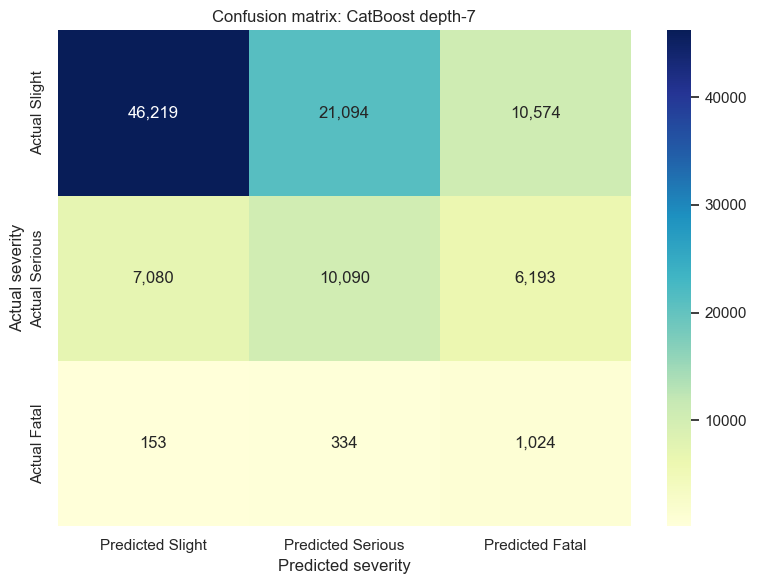

In [39]:
# ============================================================
# 8.3 DISPLAY THE CONFUSION MATRIX
# Purpose:
# Show how actual severity classes were distributed across predicted classes and highlight the most frequent mistakes.
# ============================================================

severity_order = ['Slight', 'Serious', 'Fatal']
confusion = confusion_matrix(yte, test_predictions, labels=severity_order)
confusion_table = pd.DataFrame(
    confusion,
    index=[f'Actual {label}' for label in severity_order],
    columns=[f'Predicted {label}' for label in severity_order],
)
confusion_table.to_csv(OUTPUTS / 'confusion_matrix.csv', index=True)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_table, annot=True, fmt=',d', cmap='YlGnBu')
plt.title(f'Confusion matrix: {best_name}')
plt.xlabel('Predicted severity')
plt.ylabel('Actual severity')
plt.tight_layout()
plt.show()


### 8.3.1 Map collision locations and compare severity geography

This descriptive map uses valid collision coordinates only; latitude and longitude remain excluded from model predictors. Haversine distances are reported from each collision to each severity-class geographic centroid and between class centroids. These summarize spatial separation and are not causal effects or risk estimates.

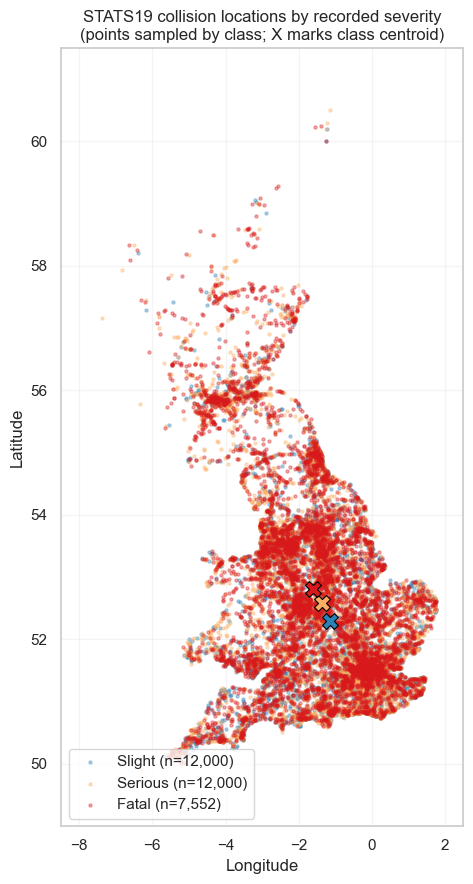

Mapped 31,552 sampled collisions from 513,748 valid UK coordinates.


,severity_label,collision_count,mean_distance_to_own_centroid_km,median_distance_to_own_centroid_km,mean_distance_to_nearest_other_centroid_km,median_distance_to_nearest_other_centroid_km
0,Slight,389399,144.2000,124.1800,143.3900,142.9200
1,Serious,116797,163.5500,147.4000,139.0900,116.1200
2,Fatal,7552,169.8600,156.7000,157.6100,129.4500


,First severity centroid,Second severity centroid,Distance (km)
0,Slight,Serious,35.6900
1,Slight,Fatal,65.7000
2,Serious,Fatal,30.2600


In [40]:
# ============================================================
# 8.3.1 MAP COLLISION LOCATIONS AND COMPARE SEVERITY GEOGRAPHY
# Purpose:
# Map observed collision coordinates by severity and summarize haversine distance to severity centroids.
# ============================================================

required_geo_columns = {'latitude', 'longitude', 'severity_label'}
missing_geo_columns = required_geo_columns - set(analysis.columns)
if missing_geo_columns:
    raise KeyError(f'Geographic analysis is missing required columns: {sorted(missing_geo_columns)}')

geo_data = analysis[['latitude', 'longitude', 'severity_label']].copy()
geo_data['latitude'] = pd.to_numeric(geo_data['latitude'], errors='coerce')
geo_data['longitude'] = pd.to_numeric(geo_data['longitude'], errors='coerce')
geo_data = geo_data.loc[
    geo_data['severity_label'].isin(severity_order)
    & np.isfinite(geo_data['latitude'])
    & np.isfinite(geo_data['longitude'])
    & geo_data['latitude'].between(49.0, 61.5)
    & geo_data['longitude'].between(-8.5, 2.5)
].copy()
if geo_data.empty:
    raise ValueError('No valid UK collision coordinates are available for the severity map.')

geo_centroids = (
    geo_data.groupby('severity_label', observed=True)
    .agg(
        centroid_latitude=('latitude', 'mean'),
        centroid_longitude=('longitude', 'mean'),
        collision_count=('latitude', 'size'),
    )
    .reindex(severity_order)
)
available_geo_classes = geo_centroids.dropna().index.tolist()
if len(available_geo_classes) < 2:
    raise ValueError('At least two severity classes with valid coordinates are required for distance comparison.')

earth_radius_km = 6371.0088
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = np.broadcast_arrays(
        *[np.radians(np.asarray(value, dtype=float)) for value in (lat1, lon1, lat2, lon2)]
    )
    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1
    haversine = (
        np.sin(delta_lat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2) ** 2
    )
    return 2 * earth_radius_km * np.arcsin(np.sqrt(np.clip(haversine, 0, 1)))

centroid_coordinates = {
    label: (geo_centroids.loc[label, 'centroid_latitude'], geo_centroids.loc[label, 'centroid_longitude'])
    for label in available_geo_classes
}
distance_columns = {}
for label, (centroid_lat, centroid_lon) in centroid_coordinates.items():
    distance_columns[f'distance_to_{label.lower()}_centroid_km'] = haversine_km(
        geo_data['latitude'].to_numpy(), geo_data['longitude'].to_numpy(),
        centroid_lat, centroid_lon,
    )
distance_matrix = pd.DataFrame(distance_columns, index=geo_data.index)
own_centroid_distance = np.empty(len(geo_data), dtype=float)
nearest_other_centroid_distance = np.empty(len(geo_data), dtype=float)
observed_geo_labels = geo_data['severity_label'].to_numpy()
for label in available_geo_classes:
    row_mask = observed_geo_labels == label
    own_column = f'distance_to_{label.lower()}_centroid_km'
    own_centroid_distance[row_mask] = distance_matrix.loc[row_mask, own_column].to_numpy()
    other_columns = [
        column for other, column in (
            (other, f'distance_to_{other.lower()}_centroid_km')
            for other in available_geo_classes if other != label
        )
    ]
    nearest_other_centroid_distance[row_mask] = distance_matrix.loc[row_mask, other_columns].min(axis=1).to_numpy()

geo_data['distance_to_own_class_centroid_km'] = own_centroid_distance
geo_data['distance_to_nearest_other_class_centroid_km'] = nearest_other_centroid_distance
geo_distance_summary = (
    geo_data.groupby('severity_label', observed=True)
    .agg(
        collision_count=('latitude', 'size'),
        mean_distance_to_own_centroid_km=('distance_to_own_class_centroid_km', 'mean'),
        median_distance_to_own_centroid_km=('distance_to_own_class_centroid_km', 'median'),
        mean_distance_to_nearest_other_centroid_km=('distance_to_nearest_other_class_centroid_km', 'mean'),
        median_distance_to_nearest_other_centroid_km=('distance_to_nearest_other_class_centroid_km', 'median'),
    )
    .reindex(severity_order)
    .reset_index()
)
centroid_distance_rows = []
for i, first_class in enumerate(available_geo_classes):
    for second_class in available_geo_classes[i + 1:]:
        first_lat, first_lon = centroid_coordinates[first_class]
        second_lat, second_lon = centroid_coordinates[second_class]
        centroid_distance_rows.append({
            'First severity centroid': first_class,
            'Second severity centroid': second_class,
            'Distance (km)': float(haversine_km(first_lat, first_lon, second_lat, second_lon)),
        })
centroid_pair_distances = pd.DataFrame(centroid_distance_rows)
geo_centroids.reset_index().to_csv(OUTPUTS / 'severity_geographic_centroids.csv', index=False)
geo_distance_summary.to_csv(OUTPUTS / 'severity_geographic_distance_summary.csv', index=False)
centroid_pair_distances.to_csv(OUTPUTS / 'severity_centroid_pair_distances.csv', index=False)

map_limit_per_class = 12000
geo_map_data = pd.concat(
    [
        group.sample(
            n=min(len(group), map_limit_per_class), random_state=RANDOM_STATE
        )
        for _, group in geo_data.groupby('severity_label', observed=True)
    ]
)
map_colors = {'Slight': '#2b83ba', 'Serious': '#fdae61', 'Fatal': '#d7191c'}
fig, ax = plt.subplots(figsize=(10, 9))
for label in available_geo_classes:
    group = geo_map_data.loc[geo_map_data['severity_label'] == label]
    ax.scatter(
        group['longitude'], group['latitude'],
        s=5, alpha=0.35, color=map_colors[label], label=f'{label} (n={len(group):,})',
        rasterized=True,
    )
    centroid_lat, centroid_lon = centroid_coordinates[label]
    ax.scatter(centroid_lon, centroid_lat, marker='X', s=130, color=map_colors[label],
               edgecolor='black', linewidth=0.8, zorder=5)
ax.set_xlim(-8.5, 2.5)
ax.set_ylim(49.0, 61.5)
ax.set_aspect(1 / np.cos(np.radians(54)), adjustable='box')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('STATS19 collision locations by recorded severity\n(points sampled by class; X marks class centroid)')
ax.grid(alpha=0.2)
ax.legend(loc='lower left')
fig.tight_layout()
fig.savefig(OUTPUTS / 'collision_locations_by_severity.png', dpi=180, bbox_inches='tight')
plt.show()
print(f'Mapped {len(geo_map_data):,} sampled collisions from {len(geo_data):,} valid UK coordinates.')
display(geo_distance_summary.round(2))
display(centroid_pair_distances.round(2))


### Interpretation of outputs - 8.3 and 8.3.1

The confusion matrix now reflects the training-tuned decision rule from section 8.1. Its diagonal contains correct predictions; off-diagonal cells show the severity confusions. Compare the counts with the class-level precision, recall and miss rate. In particular, inspect actual Serious predicted Slight and actual Fatal predicted Slight, and check whether any improved severe-class recall is accompanied by a large increase in non-severe collisions predicted Fatal.

The severity map plots a reproducible sample of valid UK collision locations; X markers show the geographic centroid of each severity class. Distance tables are descriptive spatial summaries, not performance metrics. They are not individual travel distances, severity boundaries, model features or exposure-adjusted risk estimates. Latitude and longitude remain excluded from predictors.

**Project implication:** The confusion matrix and map help explain errors and spatial distribution but do not determine acceptance. Only the refreshed metrics and gate from the rerun can show whether the criteria are met. The map is a point plot without administrative boundary or traffic-volume adjustment; geographic proximity does not imply causation or higher risk.


In [41]:
# ============================================================
# 8.4 EXPLAIN THE MODEL USING SAFE PERMUTATION IMPORTANCE
# Purpose:
# Use a stratified sample, five repetitions and one worker process to avoid Windows pickling and unnecessary runtime.
# ============================================================

PERMUTATION_SAMPLE_SIZE = min(15_000, len(Xte))

if len(Xte) > PERMUTATION_SAMPLE_SIZE:
    _, X_permutation, _, y_permutation = train_test_split(
        Xte,
        yte,
        test_size=PERMUTATION_SAMPLE_SIZE,
        stratify=yte,
        random_state=RANDOM_STATE,
    )
else:
    X_permutation = Xte.copy()
    y_permutation = yte.copy()

permutation_result = permutation_importance(
    estimator=best_model,
    X=X_permutation,
    y=y_permutation,
    scoring='f1_macro',
    n_repeats=3,
    n_jobs=1,
    random_state=RANDOM_STATE,
)

importance = (
    pd.DataFrame(
        {
            'Feature': X_permutation.columns,
            'Mean importance': permutation_result.importances_mean,
            'Importance variation': permutation_result.importances_std,
        }
    )
    .sort_values('Mean importance', ascending=False)
    .reset_index(drop=True)
)
importance.to_csv(OUTPUTS / 'permutation_importance.csv', index=False)
display(importance.head(20).style.format({'Mean importance': '{:.4f}', 'Importance variation': '{:.4f}'}))


,Feature,Mean importance,Importance variation
0,driver_age_mean,0.0143,0.0001
1,vulnerable_road_user_count,0.0124,0.0010
2,vulnerable_road_user_involved,0.0079,0.0015
3,driver_age_min,0.0068,0.0012
4,vehicle_type_first,0.0043,0.0002
5,trunk_road_flag,0.0035,0.0006
6,engine_cc_mean,0.0023,0.0018
7,road_type,0.0017,0.0002
8,time_band,0.0008,0.0005
9,speed_limit,0.0002,0.0012


### Interpretation of output - 8.4

Permutation importance is calculated for the selected model on the held-out permutation sample. Use the resulting table to identify features the fitted pipeline relies on, and interpret the rankings as model-specific rather than as causal effects.

**Project implication:** Candidate-specific importance can help prioritize further investigation, but should not be treated as an intervention ranking.

**Interpretation boundary:** Predictive reliance does not show that changing a feature would change collision severity.


In [42]:
# ============================================================
# 8.4A CREATE THE MANAGEMENT INTERPRETATION MATRIX
# Purpose:
# Translate the most influential predictors into areas for further review while explicitly avoiding causal claims.
# ============================================================
def management_area(feature_name):
    name = feature_name.lower()
    if any(word in name for word in [
        'road', 'junction', 'speed', 'carriageway', 'crossing'
    ]):
        return 'Road design and infrastructure review'
    if any(word in name for word in ['light', 'weather', 'surface']):
        return 'Visibility and environmental-condition review'
    if any(word in name for word in [
        'hour', 'time', 'day', 'month', 'weekend'
    ]):
        return 'Time-based deployment and enforcement review'
    if any(word in name for word in [
        'driver', 'vehicle', 'engine', 'manoeuvre'
    ]):
        return 'Driver, vehicle and enforcement review'
    return 'Further road-safety investigation'

management_matrix = importance.head(10).copy()
management_matrix['Management review area'] = (
    management_matrix['Feature'].apply(management_area)
)
management_matrix['Interpretation caution'] = (
    'Predictive reliance is not evidence that the feature caused severity.'
)
management_matrix.to_csv(
    OUTPUTS / 'management_interpretation_matrix.csv',
    index=False,
)
display(management_matrix)


,Feature,Mean importance,Importance variation,Management review area,Interpretation caution
0,driver_age_mean,0.0143,0.0001,"Driver, vehicle and enforcement review",Predictive reliance is not evidence that the f...
1,vulnerable_road_user_count,0.0124,0.0010,Road design and infrastructure review,Predictive reliance is not evidence that the f...
2,vulnerable_road_user_involved,0.0079,0.0015,Road design and infrastructure review,Predictive reliance is not evidence that the f...
3,driver_age_min,0.0068,0.0012,"Driver, vehicle and enforcement review",Predictive reliance is not evidence that the f...
4,vehicle_type_first,0.0043,0.0002,"Driver, vehicle and enforcement review",Predictive reliance is not evidence that the f...
5,trunk_road_flag,0.0035,0.0006,Road design and infrastructure review,Predictive reliance is not evidence that the f...
6,engine_cc_mean,0.0023,0.0018,"Driver, vehicle and enforcement review",Predictive reliance is not evidence that the f...
7,road_type,0.0017,0.0002,Road design and infrastructure review,Predictive reliance is not evidence that the f...
8,time_band,0.0008,0.0005,Time-based deployment and enforcement review,Predictive reliance is not evidence that the f...
9,speed_limit,0.0002,0.0012,Road design and infrastructure review,Predictive reliance is not evidence that the f...


### Interpretation of output — 8.4A

The management matrix converts the ten strongest predictive inputs into road design, environmental, temporal, and driver/vehicle review areas. It correctly warns that predictive reliance does not prove that changing the feature would change severity.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [43]:
# ============================================================
# 8.5 PROFILE HIGH-CONSEQUENCE MODEL ERRORS
# Purpose:
# Identify actual Serious or Fatal collisions predicted as Slight and compare selected characteristics across missed and detected severe cases.
# ============================================================

errors = Xte.copy()
errors['Actual severity'] = yte.to_numpy()
errors['Predicted severity'] = test_predictions

severe_cases = errors[
    errors['Actual severity'].isin(['Fatal', 'Serious'])
].copy()
severe_cases['Detection result'] = np.where(
    severe_cases['Predicted severity'].eq('Slight'),
    'Missed severe case',
    'Detected as non-Slight',
)

severe_summary = (
    severe_cases['Detection result']
    .value_counts()
    .rename_axis('Detection result')
    .reset_index(name='Cases')
)
severe_summary['Share'] = severe_summary['Cases'] / severe_summary['Cases'].sum()
display(severe_summary.style.format({'Cases': '{:,.0f}', 'Share': '{:.1%}'}))
severe_cases.to_csv(OUTPUTS / 'severe_case_predictions.csv', index=False)


,Detection result,Cases,Share
0,Detected as non-Slight,"17,641",70.9%
1,Missed severe case,"7,233",29.1%


### Interpretation of output - 8.5

The severe-case summary quantifies how often actual Serious and Fatal collisions were predicted as Slight versus non-Slight. Use the run's actual counts and shares to assess underclassification; do not carry forward counts from the previous candidate set.

**Project implication:** Severe-case misses remain central to the decision-support assessment.

**Interpretation boundary:** Results describe the held-out STATS19 test records and do not estimate collision occurrence risk.


In [44]:
# ============================================================
# 8.5A PROFILE MISSED AND DETECTED SEVERE CASES
# Purpose:
# Compare numeric summaries and the most common categorical values for missed versus detected Serious/Fatal collisions.
# ============================================================
profile_features = available(
    severe_cases,
    [
        'speed_limit', 'hour', 'driver_age_mean',
        'light_conditions', 'road_surface_conditions',
        'urban_or_rural_area', 'vehicle_type_first',
    ],
)
numeric_profile_features = {'speed_limit', 'hour', 'driver_age_mean'}
numeric_profiles = []
categorical_profiles = []

for feature in profile_features:
    if feature in numeric_profile_features:
        summary = (
            severe_cases.groupby('Detection result')[feature]
            .agg(['count', 'mean', 'median'])
            .reset_index()
        )
        summary.insert(0, 'Feature', feature)
        numeric_profiles.append(summary)
    else:
        summary = (
            severe_cases.groupby(
                ['Detection result', feature],
                dropna=False,
            )
            .size()
            .rename('Cases')
            .reset_index()
            .sort_values(
                ['Detection result', 'Cases'],
                ascending=[True, False],
            )
            .groupby('Detection result', as_index=False)
            .head(5)
        )
        summary.insert(0, 'Feature', feature)
        categorical_profiles.append(summary)

if numeric_profiles:
    numeric_error_profile = pd.concat(numeric_profiles, ignore_index=True)
    numeric_error_profile.to_csv(
        OUTPUTS / 'severe_error_numeric_profile.csv',
        index=False,
    )
    display(numeric_error_profile)

if categorical_profiles:
    categorical_error_profile = pd.concat(
        categorical_profiles,
        ignore_index=True,
    )
    categorical_error_profile.to_csv(
        OUTPUTS / 'severe_error_categorical_profile.csv',
        index=False,
    )
    display(categorical_error_profile)


,Feature,Detection result,count,mean,median
0,speed_limit,Detected as non-Slight,17641,39.6803,30.0000
1,speed_limit,Missed severe case,7233,33.7661,30.0000
2,hour,Detected as non-Slight,17641,13.8680,15.0000
3,hour,Missed severe case,7233,13.6804,14.0000
4,driver_age_mean,Detected as non-Slight,17206,43.0106,41.6667
5,driver_age_mean,Missed severe case,6640,39.9155,38.5000


,Feature,Detection result,light_conditions,Cases,road_surface_conditions,urban_or_rural_area,vehicle_type_first
0,light_conditions,Detected as non-Slight,1,11598,NaN,NaN,NaN
1,light_conditions,Detected as non-Slight,4,3874,NaN,NaN,NaN
2,light_conditions,Detected as non-Slight,6,1756,NaN,NaN,NaN
3,light_conditions,Detected as non-Slight,7,233,NaN,NaN,NaN
4,light_conditions,Detected as non-Slight,5,180,NaN,NaN,NaN
5,light_conditions,Missed severe case,1,5535,NaN,NaN,NaN
6,light_conditions,Missed severe case,4,1404,NaN,NaN,NaN
7,light_conditions,Missed severe case,6,155,NaN,NaN,NaN
8,light_conditions,Missed severe case,7,99,NaN,NaN,NaN
9,light_conditions,Missed severe case,5,40,NaN,NaN,NaN


### Interpretation of output — 8.5A

The error profiles compare numeric summaries and frequent categories between missed and detected severe cases. The output provides concrete segments for feature engineering or threshold analysis, but observed differences do not explain causation.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [45]:
# ============================================================
# 8.6 PERFORM LATEST-YEAR ROBUSTNESS TESTING
# Purpose:
# Train the selected pipeline on earlier years and test it on the latest year to assess stability over time.
# ============================================================

if 'calendar_year' not in analysis.columns:
    print('Latest-year validation skipped because calendar year is unavailable.')
else:
    temporal_data = analysis[features + ['severity_label', 'calendar_year']].dropna(
        subset=['severity_label', 'calendar_year']
    ).copy()
    latest_year = int(temporal_data['calendar_year'].max())
    temporal_train = temporal_data[temporal_data['calendar_year'] < latest_year].copy()
    temporal_test = temporal_data[temporal_data['calendar_year'] == latest_year].copy()

    for column in categorical_features:
        temporal_train[column] = (
            temporal_train[column]
            .astype(object)
            .where(temporal_train[column].notna(), 'Missing')
            .map(str)
        )
        temporal_test[column] = (
            temporal_test[column]
            .astype(object)
            .where(temporal_test[column].notna(), 'Missing')
            .map(str)
        )

    temporal_model = clone(models[best_name])
    if best_name == 'Weighted neural network':
        temporal_y_train = temporal_train['severity_label']
        temporal_model.fit(
            temporal_train[features],
            temporal_y_train,
            classifier__sample_weight=compute_sample_weight(
                class_weight='balanced', y=temporal_y_train
            ),
        )
    else:
        temporal_model.fit(temporal_train[features], temporal_train['severity_label'])
    temporal_predictions = temporal_model.predict(temporal_test[features])

    temporal_metrics = pd.DataFrame(
        [
            {
                'Test year': latest_year,
                'Training records': len(temporal_train),
                'Test records': len(temporal_test),
                'Macro-F1': f1_score(
                    temporal_test['severity_label'], temporal_predictions, average='macro'
                ),
                'Balanced accuracy': balanced_accuracy_score(
                    temporal_test['severity_label'], temporal_predictions
                ),
                'Serious recall': recall_score(
                    temporal_test['severity_label'], temporal_predictions,
                    labels=['Serious'], average='macro', zero_division=0
                ),
                'Fatal recall': recall_score(
                    temporal_test['severity_label'], temporal_predictions,
                    labels=['Fatal'], average='macro', zero_division=0
                ),
            }
        ]
    )
    temporal_metrics.to_csv(OUTPUTS / 'temporal_holdout_metrics.csv', index=False)
    display(temporal_metrics)


,Test year,Training records,Test records,Macro-F1,Balanced accuracy,Serious recall,Fatal recall
0,2025,412276,101525,0.3864,0.5589,0.5111,0.6366


### Interpretation of output - 8.6

The latest-year holdout evaluates the selected pipeline on the most recent year after fitting on earlier years. Review the current run's Macro-F1, balanced accuracy, Serious recall and Fatal recall to see whether random-split results persist over time.

**Project implication:** Temporal stability is required before any operational consideration; the random holdout alone is insufficient.

**Interpretation boundary:** The temporal holdout remains an observational assessment of recorded collisions, not a causal or collision-occurrence model.


# 8.7-8.10 Recommendation Experiments and Robustness Checks

These are additional educational experiments. They do not replace the primary three-class evaluation or acceptance gate.


In [46]:
# ============================================================
# 8.7 RUN THE RECOMMENDATION EXPERIMENTS
# Purpose:
# Evaluate severe-collision, hierarchical, resampling, tuning, threshold,
# calibration, geographic and severe-error analyses without using the
# untouched test set to tune model parameters or decision thresholds.
# ============================================================

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import ParameterGrid

RECOMMENDATION_OUTPUTS = OUTPUTS
SEVERITY_ORDER = ['Slight', 'Serious', 'Fatal']
recommendation_rows = []


def fit_project_candidate(model_name, estimator, X_fit, y_fit):
    fitted = clone(estimator)
    if model_name == 'Weighted neural network':
        fitted.fit(
            X_fit,
            y_fit,
            classifier__sample_weight=compute_sample_weight(
                class_weight='balanced', y=y_fit
            ),
        )
    else:
        fitted.fit(X_fit, y_fit)
    return fitted


def class_ordered_probabilities(estimator, X_eval, labels):
    probabilities = estimator.predict_proba(X_eval)
    classes = list(estimator.classes_)
    return np.column_stack(
        [
            probabilities[:, classes.index(label)]
            if label in classes
            else np.zeros(len(X_eval))
            for label in labels
        ]
    )


def multiclass_brier(y_true, probabilities, labels):
    truth = pd.Categorical(y_true, categories=labels)
    one_hot = np.eye(len(labels))[truth.codes]
    return float(np.mean(np.sum((probabilities - one_hot) ** 2, axis=1)))


# 1. Binary Serious/Fatal versus Slight experiment.
binary_model = clone(weighted_random_forest_model)
ytr_severe = ytr.isin(['Serious', 'Fatal']).map({True: 'Severe', False: 'Slight'})
yte_severe = yte.isin(['Serious', 'Fatal']).map({True: 'Severe', False: 'Slight'})
binary_model.fit(Xtr, ytr_severe)
binary_probabilities = class_ordered_probabilities(
    binary_model, Xte, ['Slight', 'Severe']
)[:, 1]
binary_predictions = np.where(binary_probabilities >= 0.5, 'Severe', 'Slight')
binary_metrics = {
    'ROC-AUC': roc_auc_score(yte_severe.eq('Severe'), binary_probabilities),
    'PR-AUC': average_precision_score(yte_severe.eq('Severe'), binary_probabilities),
    'Severe recall': recall_score(
        yte_severe, binary_predictions, pos_label='Severe', zero_division=0
    ),
    'Severe F1': f1_score(
        yte_severe, binary_predictions, pos_label='Severe', zero_division=0
    ),
    'Accuracy': accuracy_score(yte_severe, binary_predictions),
}
binary_results = pd.DataFrame(
    [{'Experiment': 'Weighted RF: Severe vs Slight', 'Measure': k, 'Result': v}
     for k, v in binary_metrics.items()]
)
binary_results.to_csv(OUTPUTS / 'binary_severe_metrics.csv', index=False)
display(binary_results)

# 2. Two-stage hierarchical severity model.
stage_one = clone(weighted_random_forest_model)
ytr_stage_one = ytr.map(
    lambda label: 'Severe' if label in ['Serious', 'Fatal'] else 'Slight'
)
stage_one.fit(Xtr, ytr_stage_one)
stage_one_probabilities = class_ordered_probabilities(
    stage_one, Xte, ['Slight', 'Severe']
)[:, 1]
stage_two_mask = ytr.isin(['Serious', 'Fatal'])
stage_two = clone(weighted_random_forest_model)
stage_two.fit(
    Xtr.loc[stage_two_mask],
    ytr.loc[stage_two_mask].map(
        {'Serious': 'Serious', 'Fatal': 'Fatal'}
    ),
)
stage_two_predictions = stage_two.predict(Xte)
hierarchical_predictions = np.where(
    stage_one_probabilities >= 0.5,
    stage_two_predictions,
    'Slight',
)
hierarchical_predictions = pd.Series(
    hierarchical_predictions, index=yte.index, name='Prediction'
)
hierarchical_results = pd.DataFrame(
    [
        {
            'Model': f'{best_name} (selected three-class model)',
            'Macro-F1': f1_score(yte, test_predictions, average='macro', zero_division=0),
            'Serious recall': recall_score(
                yte, test_predictions, labels=['Serious'], average='macro', zero_division=0
            ),
            'Fatal recall': recall_score(
                yte, test_predictions, labels=['Fatal'], average='macro', zero_division=0
            ),
        },
        {
            'Model': 'Two-stage weighted Random Forest',
            'Macro-F1': f1_score(
                yte, hierarchical_predictions, average='macro', zero_division=0
            ),
            'Serious recall': recall_score(
                yte, hierarchical_predictions, labels=['Serious'],
                average='macro', zero_division=0
            ),
            'Fatal recall': recall_score(
                yte, hierarchical_predictions, labels=['Fatal'],
                average='macro', zero_division=0
            ),
        },
    ]
)
hierarchical_results.to_csv(OUTPUTS / 'hierarchical_model_metrics.csv', index=False)
display(hierarchical_results)

# 3. RandomOverSampler, SMOTENC and SMOTENC+Tomek, applied inside CV folds only.
resampling_rows = []
resampling_size = min(30_000, len(Xtr))
if resampling_size < len(Xtr):
    X_resample_cv, _, y_resample_cv, _ = train_test_split(
        Xtr, ytr, train_size=resampling_size, stratify=ytr,
        random_state=RANDOM_STATE,
    )
else:
    X_resample_cv, y_resample_cv = Xtr.copy(), ytr.copy()
# tree_preprocessor emits numeric columns first, followed by categorical columns.
category_positions = list(
    range(len(numeric_features), len(numeric_features) + len(categorical_features))
)
raw_forest = RandomForestClassifier(
    n_estimators=100, min_samples_leaf=3,
    random_state=RANDOM_STATE, n_jobs=N_JOBS,
)
sampler_candidates = {
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
}
if category_positions:
    smote_nc = SMOTENC(
        categorical_features=category_positions,
        random_state=RANDOM_STATE,
    )
    sampler_candidates['SMOTENC'] = smote_nc
    sampler_candidates['SMOTENC + Tomek'] = SMOTETomek(
        smote=SMOTENC(
            categorical_features=category_positions,
            random_state=RANDOM_STATE,
        ),
        random_state=RANDOM_STATE,
    )
resampling_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE
)
for sampler_name, sampler in sampler_candidates.items():
    sampler_pipeline = ImbalancedPipeline(
        steps=[
            ('preprocessor', clone(tree_preprocessor)),
            ('sampler', sampler),
            ('classifier', clone(raw_forest)),
        ]
    )
    fold_results = cross_validate(
        sampler_pipeline,
        X_resample_cv,
        y_resample_cv,
        cv=resampling_cv,
        scoring={
            'macro_f1': 'f1_macro',
            'balanced_accuracy': 'balanced_accuracy',
            'serious_recall': make_scorer(
                recall_score, labels=['Serious'], average='macro', zero_division=0
            ),
            'fatal_recall': make_scorer(
                recall_score, labels=['Fatal'], average='macro', zero_division=0
            ),
        },
        n_jobs=1,
        error_score='raise',
    )
    resampling_rows.append(
        {
            'Sampler': sampler_name,
            'CV records': len(X_resample_cv),
            'Macro-F1': fold_results['test_macro_f1'].mean(),
            'Macro-F1 variation': fold_results['test_macro_f1'].std(),
            'Balanced accuracy': fold_results['test_balanced_accuracy'].mean(),
            'Serious recall': fold_results['test_serious_recall'].mean(),
            'Fatal recall': fold_results['test_fatal_recall'].mean(),
        }
    )
resampling_results = pd.DataFrame(resampling_rows)
resampling_results.to_csv(OUTPUTS / 'resampling_cv_metrics.csv', index=False)
display(resampling_results)

# 4. Small, training-only parameter search for the leading tree candidate and MLP.
tree_families = {
    'Weighted random forest',
    'Extra Trees (balanced)',
    'Histogram gradient boosting',
    'Balanced histogram gradient boosting',
    'CatBoost',
    'CatBoost depth-7',
}
tree_candidates = [
    name for name in cv_results['Model'].tolist()
    if name in tree_families and name in models
]
tuning_model_names = []
if tree_candidates:
    tuning_model_names.append(tree_candidates[0])
if 'Weighted neural network' in models:
    tuning_model_names.append('Weighted neural network')
tuning_configs = {
    'Weighted random forest': [
        {'classifier__n_estimators': [100], 'classifier__min_samples_leaf': [3]},
        {'classifier__n_estimators': [150], 'classifier__min_samples_leaf': [5]},
    ],
    'Histogram gradient boosting': [
        {'classifier__learning_rate': [0.05], 'classifier__max_leaf_nodes': [15]},
        {'classifier__learning_rate': [0.08], 'classifier__max_leaf_nodes': [31]},
    ],
    'Extra Trees (balanced)': [
        {'classifier__n_estimators': [200], 'classifier__min_samples_leaf': [2]},
        {'classifier__n_estimators': [400], 'classifier__min_samples_leaf': [5]},
    ],
    'Balanced histogram gradient boosting': [
        {'classifier__learning_rate': [0.04], 'classifier__max_leaf_nodes': [15]},
        {'classifier__learning_rate': [0.06], 'classifier__max_leaf_nodes': [31]},
    ],
    'CatBoost': [
        {'classifier__depth': [5], 'classifier__iterations': [250]},
        {'classifier__depth': [7], 'classifier__iterations': [350]},
    ],
    'CatBoost depth-7': [
        {'classifier__depth': [6], 'classifier__iterations': [250]},
        {'classifier__depth': [7], 'classifier__iterations': [450]},
    ],
    'Weighted neural network': [
        {'classifier__hidden_layer_sizes': [(32, 16)], 'classifier__max_iter': [60]},
        {'classifier__hidden_layer_sizes': [(64, 32)], 'classifier__max_iter': [100]},
    ],
}
tuning_size = min(15_000, len(Xtr))
if tuning_size < len(Xtr):
    X_tuning, _, y_tuning, _ = train_test_split(
        Xtr, ytr, train_size=tuning_size, stratify=ytr,
        random_state=RANDOM_STATE,
    )
else:
    X_tuning, y_tuning = Xtr.copy(), ytr.copy()
tuning_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
tuning_rows = []
for tuning_name in tuning_model_names:
    for parameter_set in ParameterGrid(tuning_configs[tuning_name]):
        fold_rows = []
        for train_indices, validation_indices in tuning_cv.split(X_tuning, y_tuning):
            X_fit = X_tuning.iloc[train_indices]
            y_fit = y_tuning.iloc[train_indices]
            X_validation = X_tuning.iloc[validation_indices]
            y_validation = y_tuning.iloc[validation_indices]
            candidate = clone(models[tuning_name]).set_params(**parameter_set)
            candidate = fit_project_candidate(tuning_name, candidate, X_fit, y_fit)
            validation_prediction = candidate.predict(X_validation)
            fold_rows.append(
                {
                    'Macro-F1': f1_score(
                        y_validation, validation_prediction,
                        average='macro', zero_division=0
                    ),
                    'Serious recall': recall_score(
                        y_validation, validation_prediction,
                        labels=['Serious'], average='macro', zero_division=0
                    ),
                    'Fatal recall': recall_score(
                        y_validation, validation_prediction,
                        labels=['Fatal'], average='macro', zero_division=0
                    ),
                }
            )
        tuning_rows.append(
            {
                'Model': tuning_name,
                'Parameters': json.dumps(parameter_set, default=str, sort_keys=True),
                'Tuning records': len(X_tuning),
                'Macro-F1': np.mean([row['Macro-F1'] for row in fold_rows]),
                'Macro-F1 variation': np.std([row['Macro-F1'] for row in fold_rows]),
                'Serious recall': np.mean([row['Serious recall'] for row in fold_rows]),
                'Fatal recall': np.mean([row['Fatal recall'] for row in fold_rows]),
            }
        )
tuning_results = pd.DataFrame(tuning_rows).sort_values(
    'Macro-F1', ascending=False
).reset_index(drop=True)
tuning_results.to_csv(OUTPUTS / 'candidate_tuning_results.csv', index=False)
display(tuning_results)

# 5. Threshold and illustrative cost analysis using an internal training split only.
threshold_fit_X, threshold_validation_X, threshold_fit_y, threshold_validation_y = (
    train_test_split(
        Xtr, ytr, test_size=0.20, stratify=ytr, random_state=RANDOM_STATE
    )
)
threshold_binary_model = clone(weighted_random_forest_model)
threshold_fit_binary_y = threshold_fit_y.isin(['Serious', 'Fatal']).map(
    {True: 'Severe', False: 'Slight'}
)
threshold_validation_binary_y = threshold_validation_y.isin(
    ['Serious', 'Fatal']
).map({True: 'Severe', False: 'Slight'})
threshold_binary_model.fit(threshold_fit_X, threshold_fit_binary_y)
threshold_scores = class_ordered_probabilities(
    threshold_binary_model, threshold_validation_X, ['Slight', 'Severe']
)[:, 1]
threshold_precision, threshold_recall, threshold_values = precision_recall_curve(
    threshold_validation_binary_y.eq('Severe'), threshold_scores
)
threshold_f1 = (
    2 * threshold_precision[:-1] * threshold_recall[:-1]
    / (threshold_precision[:-1] + threshold_recall[:-1] + 1e-12)
)
best_f1_position = int(np.nanargmax(threshold_f1))
FALSE_NEGATIVE_COST = 5
FALSE_POSITIVE_COST = 1
threshold_costs = []
for threshold in threshold_values:
    prediction = threshold_scores >= threshold
    actual = threshold_validation_binary_y.eq('Severe').to_numpy()
    false_negative = int(np.sum(actual & ~prediction))
    false_positive = int(np.sum(~actual & prediction))
    threshold_costs.append(
        false_negative * FALSE_NEGATIVE_COST
        + false_positive * FALSE_POSITIVE_COST
    )
best_cost_position = int(np.argmin(threshold_costs))
def threshold_row(label, position):
    threshold = float(threshold_values[position])
    prediction = threshold_scores >= threshold
    actual = threshold_validation_binary_y.eq('Severe')
    return {
        'Rule': label,
        'Threshold': threshold,
        'Precision': float(precision_score(
            actual, prediction, zero_division=0
        )),
        'Severe recall': float(recall_score(
            actual, prediction, zero_division=0
        )),
        'Severe F1': float(f1_score(
            actual, prediction, zero_division=0
        )),
        'Illustrative cost': int(threshold_costs[position]),
        'False-negative cost weight': FALSE_NEGATIVE_COST,
        'False-positive cost weight': FALSE_POSITIVE_COST,
    }
threshold_results = pd.DataFrame(
    [
        {
            **threshold_row('Default 0.50', int(np.argmin(np.abs(threshold_values - 0.5)))),
            'Rule': 'Default 0.50',
        },
        threshold_row('Best validation Severe F1', best_f1_position),
        threshold_row('Lowest illustrative validation cost', best_cost_position),
    ]
)
threshold_results.to_csv(OUTPUTS / 'severe_threshold_cost_analysis.csv', index=False)
display(threshold_results)

# 6. Probability calibration, fitted only within training data.
calibration_base_name = (
    best_name if best_name != 'Weighted neural network'
    else 'Weighted random forest'
)
calibration_base = clone(models[calibration_base_name])
uncalibrated_model = fit_project_candidate(
    calibration_base_name, calibration_base, Xtr, ytr
)
calibration_method = 'sigmoid'
calibrated_model = CalibratedClassifierCV(
    estimator=clone(models[calibration_base_name]),
    method=calibration_method,
    cv=3,
)
calibrated_model.fit(Xtr, ytr)
# sklearn multiclass log-loss expects lexicographically ordered class labels
# and probability columns. Keep this explicit to prevent class-order mixups.
CALIBRATION_CLASS_ORDER = sorted(SEVERITY_ORDER)
uncalibrated_probabilities = class_ordered_probabilities(
    uncalibrated_model, Xte, CALIBRATION_CLASS_ORDER
)
calibrated_probabilities = class_ordered_probabilities(
    calibrated_model, Xte, CALIBRATION_CLASS_ORDER
)
calibration_rows = []
for label, probabilities in [
    ('Uncalibrated', uncalibrated_probabilities),
    ('Sigmoid calibrated', calibrated_probabilities),
]:
    calibration_rows.append(
        {
            'Model': calibration_base_name,
            'Probability treatment': label,
            'Test multiclass Brier score': multiclass_brier(
                yte, probabilities, CALIBRATION_CLASS_ORDER
            ),
            'Test log loss': log_loss(
                yte, probabilities, labels=CALIBRATION_CLASS_ORDER
            ),
            'Test Macro-F1 at argmax': f1_score(
                yte, np.asarray(CALIBRATION_CLASS_ORDER)[probabilities.argmax(axis=1)],
                average='macro', zero_division=0
            ),
        }
    )
calibration_results = pd.DataFrame(calibration_rows)
calibration_results.to_csv(OUTPUTS / 'probability_calibration_metrics.csv', index=False)
calibration_curve_rows = []
for label, probabilities in [
    ('Uncalibrated', uncalibrated_probabilities),
    ('Sigmoid calibrated', calibrated_probabilities),
]:
    actual_severe = yte.isin(['Serious', 'Fatal']).astype(int)
    severe_indices = [
        CALIBRATION_CLASS_ORDER.index(class_name)
        for class_name in ['Serious', 'Fatal']
    ]
    predicted_severe = probabilities[:, severe_indices].sum(axis=1)
    fraction_positive, mean_probability = calibration_curve(
        actual_severe, predicted_severe, n_bins=10, strategy='quantile'
    )
    calibration_curve_rows.extend(
        {
            'Probability treatment': label,
            'Bin': bin_number + 1,
            'Mean predicted severe probability': mean_probability[bin_number],
            'Observed severe share': fraction_positive[bin_number],
        }
        for bin_number in range(len(mean_probability))
    )
pd.DataFrame(calibration_curve_rows).to_csv(
    OUTPUTS / 'severe_probability_calibration_curve.csv', index=False
)
display(calibration_results)

# 7. Grouped geographic validation, held apart from the untouched random test set.
# Prefer the current ONS authority identifier; the legacy numeric field can be
# a negative administrative code for nearly every row and is not a valid group.
geographic_candidates = [
    'local_authority_ons_district',
    'local_authority_highway',
    'local_authority_district',
]
geographic_column = next(
    (
        column for column in geographic_candidates
        if column in analysis.columns
        and analysis.loc[Xtr.index, column].nunique(dropna=True) >= 20
    ),
    None,
)
geographic_results = pd.DataFrame()
if geographic_column is not None:
    geo_groups = (
        analysis.loc[Xtr.index, geographic_column]
        .astype('string')
        .fillna('Missing')
    )
    group_splitter = GroupShuffleSplit(
        n_splits=25, test_size=0.20, random_state=RANDOM_STATE
    )
    candidate_splits = []
    expected_labels = set(SEVERITY_ORDER)
    for train_indices, validation_indices in group_splitter.split(
        Xtr, ytr, groups=geo_groups
    ):
        train_labels = set(ytr.iloc[train_indices])
        validation_labels = set(ytr.iloc[validation_indices])
        if train_labels != expected_labels or validation_labels != expected_labels:
            continue
        validation_fraction = len(validation_indices) / len(Xtr)
        candidate_splits.append(
            (
                abs(validation_fraction - 0.20),
                train_indices,
                validation_indices,
            )
        )
    if not candidate_splits:
        raise ValueError(
            f'Could not form a grouped holdout with all severity labels for {geographic_column}.'
        )
    _, geo_train_indices, geo_validation_indices = min(
        candidate_splits, key=lambda item: item[0]
    )
    X_geo_train = Xtr.iloc[geo_train_indices]
    y_geo_train = ytr.iloc[geo_train_indices]
    X_geo_validation = Xtr.iloc[geo_validation_indices]
    y_geo_validation = ytr.iloc[geo_validation_indices]
    geo_train_groups = set(geo_groups.iloc[geo_train_indices])
    geo_validation_groups = set(geo_groups.iloc[geo_validation_indices])
    geographic_model = fit_project_candidate(
        best_name, models[best_name], X_geo_train, y_geo_train
    )
    geo_predictions = geographic_model.predict(X_geo_validation)
    geographic_results = pd.DataFrame(
        [
            {
                'Grouping field': geographic_column,
                'Training records': len(X_geo_train),
                'Validation records': len(X_geo_validation),
                'Training authorities': len(geo_train_groups),
                'Validation authorities': len(geo_validation_groups),
                'Overlapping authorities': len(geo_train_groups & geo_validation_groups),
                'Macro-F1': f1_score(
                    y_geo_validation, geo_predictions,
                    average='macro', zero_division=0
                ),
                'Balanced accuracy': balanced_accuracy_score(
                    y_geo_validation, geo_predictions
                ),
                'Serious recall': recall_score(
                    y_geo_validation, geo_predictions,
                    labels=['Serious'], average='macro', zero_division=0
                ),
                'Fatal recall': recall_score(
                    y_geo_validation, geo_predictions,
                    labels=['Fatal'], average='macro', zero_division=0
                ),
            }
        ]
    )
else:
    geographic_results = pd.DataFrame(
        [{'Status': 'Skipped: no local-authority group field with at least 20 groups is available'}]
    )
geographic_results.to_csv(OUTPUTS / 'geographic_holdout_metrics.csv', index=False)
display(geographic_results)

# 8. Feature/case profiles for severe outcomes missed as Slight.
severe_error_rows = []
severe_eval = Xte.copy()
severe_eval['Actual severity'] = yte.to_numpy()
severe_eval['Predicted severity'] = test_predictions
severe_eval = severe_eval[
    severe_eval['Actual severity'].isin(['Serious', 'Fatal'])
].copy()
severe_eval['Detection group'] = np.where(
    severe_eval['Predicted severity'].eq('Slight'),
    'Missed as Slight',
    'Detected as non-Slight',
)
profile_features = [
    column for column in [
        'speed_limit', 'road_type', 'light_conditions', 'junction_detail',
        'vehicle_type_first', 'vulnerable_road_user_involved',
        'motorcycle_involved', 'goods_vehicle_involved',
    ]
    if column in severe_eval.columns
]
for feature in profile_features:
    for group_name, group in severe_eval.groupby('Detection group'):
        values = (
            group[feature].astype('string').fillna('Missing')
            .value_counts(normalize=True).head(10)
        )
        severe_error_rows.extend(
            {
                'Feature': feature,
                'Detection group': group_name,
                'Category': category,
                'Share within group': share,
                'Cases in group': len(group),
            }
            for category, share in values.items()
        )
severe_error_profile = pd.DataFrame(severe_error_rows)
severe_error_profile.to_csv(
    OUTPUTS / 'severe_error_segment_profiles.csv', index=False
)
display(severe_error_profile.head(40))

# Consolidated, run-specific results and concise evidence-based interpretations.
recommendation_evidence = [
    {
        'Recommendation': 'Binary severe-collision experiment',
        'Evidence': (
            f"Test ROC-AUC {binary_metrics['ROC-AUC']:.3f}; "
            f"PR-AUC {binary_metrics['PR-AUC']:.3f}; "
            f"Severe recall {binary_metrics['Severe recall']:.3f}; "
            f"Severe F1 {binary_metrics['Severe F1']:.3f}."
        ),
    },
    {
        'Recommendation': 'Hierarchical classifier',
        'Evidence': (
            'Compare the two-stage and three-class Macro-F1/Serious/Fatal recall '
            'rows in hierarchical_model_metrics.csv; predictions use the same untouched test set.'
        ),
    },
    {
        'Recommendation': 'Imbalance and resampling experiments',
        'Evidence': (
            'Compare fold-only RandomOverSampler, SMOTENC and SMOTENC+Tomek rows '
            'with the existing class-weighted and ensemble candidates.'
        ),
    },
    {
        'Recommendation': 'Candidate tuning',
        'Evidence': (
            f"Training-only parameter search evaluated {len(tuning_results):,} "
            f"configurations across {tuning_size:,} records; best Macro-F1 "
            f"{tuning_results.iloc[0]['Macro-F1']:.3f}."
            if not tuning_results.empty else 'No tuning candidate was available.'
        ),
    },
    {
        'Recommendation': 'Threshold and illustrative cost analysis',
        'Evidence': (
            'Thresholds selected on an internal training validation split only; '
            'cost weights are illustrative (FN=5, FP=1), not stakeholder elicited.'
        ),
    },
    {
        'Recommendation': 'Vehicle and vulnerable-road-user aggregation',
        'Evidence': (
            'Collision-level type counts, max vehicle age, motorcycle/goods involvement '
            'and non-severity vulnerable-road-user summaries are included in modelling features.'
        ),
    },
    {
        'Recommendation': 'Severe-case error analysis',
        'Evidence': (
            f"{len(severe_eval):,} actual Serious/Fatal test cases profiled by "
            f"{len(profile_features)} available segment features."
        ),
    },
    {
        'Recommendation': 'Probability calibration',
        'Evidence': (
            'Compare held-out multiclass Brier score, log loss, argmax Macro-F1 and '
            'severe-class calibration bins for uncalibrated versus sigmoid probabilities.'
        ),
    },
    {
        'Recommendation': 'Geographic robustness',
        'Evidence': (
            geographic_results.iloc[0].to_dict().__str__()
            if not geographic_results.empty else 'No geographic test result was generated.'
        ),
    },
    {
        'Recommendation': 'Scope and evaluation discipline',
        'Evidence': (
            'All collision shares describe the analysed STATS19 sample; no traffic-exposure '
            'denominator is used. Tuning and threshold selection use training-only folds/splits.'
        ),
    },
]
recommendation_evidence = pd.DataFrame(recommendation_evidence)
recommendation_evidence.to_csv(
    OUTPUTS / 'recommendation_experiment_summary.csv', index=False
)
print('SECTION 10.6 - RUN-SPECIFIC EVIDENCE AND INTERPRETATION')
display(recommendation_evidence)

if not tuning_results.empty:
    print(
        f"Interpretation: best bounded tuning result was "
        f"{tuning_results.iloc[0]['Model']} (Macro-F1 "
        f"{tuning_results.iloc[0]['Macro-F1']:.3f}); it remains a training-only "
        "candidate and has not been selected using the untouched test set."
    )
if len(hierarchical_results) == 2:
    base_row = hierarchical_results.iloc[0]
    hierarchy_row = hierarchical_results.iloc[1]
    print(
        "Interpretation: hierarchical minus three-class test Macro-F1 = "
        f"{hierarchy_row['Macro-F1'] - base_row['Macro-F1']:+.3f}; "
        "review Serious and Fatal recall alongside this difference."
    )
print(
    "Interpretation: the selected threshold and illustrative cost weights are "
    "not production decision thresholds; stakeholders must define error costs."
)


,Experiment,Measure,Result
0,Weighted RF: Severe vs Slight,ROC-AUC,0.7079
1,Weighted RF: Severe vs Slight,PR-AUC,0.4415
2,Weighted RF: Severe vs Slight,Severe recall,0.3132
3,Weighted RF: Severe vs Slight,Severe F1,0.3801
4,Weighted RF: Severe vs Slight,Accuracy,0.7527


,Model,Macro-F1,Serious recall,Fatal recall
0,CatBoost depth-7 (selected three-class model),0.3925,0.4319,0.6777
1,Two-stage weighted Random Forest,0.4296,0.2936,0.0556


,Sampler,CV records,Macro-F1,Macro-F1 variation,Balanced accuracy,Serious recall,Fatal recall
0,RandomOverSampler,30000,0.4029,0.0029,0.3955,0.2786,0.0204
1,SMOTENC,30000,0.4047,0.0069,0.3965,0.2327,0.0567
2,SMOTENC + Tomek,30000,0.4134,0.0067,0.4033,0.2336,0.0771


c:\Users\Isaac\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Isaac\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Isaac\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Isaac\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Isaac\anaconda3\Lib\site-packages\sklearn\neural_network\_multilay

,Model,Parameters,Tuning records,Macro-F1,Macro-F1 variation,Serious recall,Fatal recall
0,CatBoost depth-7,"{""classifier__depth"": 7, ""classifier__iteratio...",15000,0.4221,0.0096,0.5478,0.0950
1,CatBoost depth-7,"{""classifier__depth"": 6, ""classifier__iteratio...",15000,0.4131,0.0043,0.5554,0.2127
2,Weighted neural network,"{""classifier__hidden_layer_sizes"": [32, 16], ""...",15000,0.3923,0.0085,0.5525,0.0723
3,Weighted neural network,"{""classifier__hidden_layer_sizes"": [64, 32], ""...",15000,0.3885,0.0023,0.4246,0.0633


,Rule,Threshold,Precision,Severe recall,Severe F1,Illustrative cost,False-negative cost weight,False-positive cost weight
0,Default 0.50,0.5000,0.4828,0.3120,0.3791,75099,5,1
1,Best validation Severe F1,0.3510,0.3671,0.6653,0.4731,56124,5,1
2,Lowest illustrative validation cost,0.2567,0.3159,0.8499,0.4606,51562,5,1


... (2 outputs left out)

,Feature,Detection group,Category,Share within group,Cases in group
0,speed_limit,Detected as non-Slight,30,0.4568,17641
1,speed_limit,Detected as non-Slight,60,0.2174,17641
2,speed_limit,Detected as non-Slight,20,0.1203,17641
3,speed_limit,Detected as non-Slight,40,0.0906,17641
4,speed_limit,Detected as non-Slight,70,0.0579,17641
5,speed_limit,Detected as non-Slight,50,0.0570,17641
6,speed_limit,Missed as Slight,30,0.5739,7233
7,speed_limit,Missed as Slight,20,0.1860,7233
8,speed_limit,Missed as Slight,40,0.0868,7233
9,speed_limit,Missed as Slight,60,0.0701,7233


SECTION 10.6 - RUN-SPECIFIC EVIDENCE AND INTERPRETATION


,Recommendation,Evidence
0,Binary severe-collision experiment,Test ROC-AUC 0.708; PR-AUC 0.442; Severe recal...
1,Hierarchical classifier,Compare the two-stage and three-class Macro-F1...
2,Imbalance and resampling experiments,"Compare fold-only RandomOverSampler, SMOTENC a..."
3,Candidate tuning,Training-only parameter search evaluated 4 con...
4,Threshold and illustrative cost analysis,Thresholds selected on an internal training va...
5,Vehicle and vulnerable-road-user aggregation,"Collision-level type counts, max vehicle age, ..."
6,Severe-case error analysis,"24,874 actual Serious/Fatal test cases profile..."
7,Probability calibration,"Compare held-out multiclass Brier score, log l..."
8,Geographic robustness,{'Grouping field': 'local_authority_ons_distri...
9,Scope and evaluation discipline,All collision shares describe the analysed STA...


Interpretation: best bounded tuning result was CatBoost depth-7 (Macro-F1 0.422); it remains a training-only candidate and has not been selected using the untouched test set.
Interpretation: hierarchical minus three-class test Macro-F1 = +0.037; review Serious and Fatal recall alongside this difference.
Interpretation: the selected threshold and illustrative cost weights are not production decision thresholds; stakeholders must define error costs.


### Interpretation of output - 8.7 to 8.10

The experiment cells produce run-specific outputs for binary Severe-versus-Slight prediction, the hierarchical model, fold-contained resampling, bounded training-only tuning, threshold/cost analysis, class-order-correct probability calibration, a class-complete grouped holdout by current ONS local authority, and severe-case profiles. The final table is written to `recommendation_experiment_summary.csv`; supporting metrics are saved as separate CSV files in the outputs folder.

**Analysis rule:** Read each result alongside the severe-class recall and uncertainty/runtime. The tuning and threshold experiments do not use the untouched test partition. Binary, hierarchical and calibrated model test results are descriptive evaluations on that partition and must not be used to retune.

**Interpretation boundary:** The example false-negative/false-positive cost ratio is illustrative, local-authority validation is one held-out grouped split, and collision-level shares are not exposure-adjusted rates.


# 9. CRISP-DM Phase 6: Deployment and Governance

In [47]:
# ============================================================
# 9.1 APPLY THE MODEL ACCEPTANCE GATE
# Purpose:
# Compare the selected model with documented minimum conditions before permitting stakeholder-facing deployment.
# ============================================================

dummy_macro_f1 = cv_results.loc[
    cv_results['Model'] == 'Dummy majority', 'Macro-F1'
].iloc[0]
selected_macro_f1 = cv_results.iloc[0]['Macro-F1']

acceptance_criteria = {
    'Performs better than the no-skill model': selected_macro_f1 > dummy_macro_f1,
    'Macro-F1 is at least 0.60': final_metrics['Macro-F1'] >= 0.60,
    'Balanced accuracy is at least 0.60': final_metrics['Balanced accuracy'] >= 0.60,
    'Serious recall is at least 0.60': final_metrics['Serious recall'] >= 0.60,
    'Fatal recall is at least 0.60': final_metrics['Fatal recall'] >= 0.60,
}

acceptance_table = pd.DataFrame(
    {
        'Acceptance test': acceptance_criteria.keys(),
        'Passed': acceptance_criteria.values(),
    }
)
all_passed = bool(acceptance_table['Passed'].all())
final_decision = (
    'Suitable for a research demonstration'
    if all_passed
    else 'Further model improvement recommended'
)
acceptance_table['Overall decision'] = final_decision
acceptance_table.to_csv(OUTPUTS / 'model_acceptance_gate.csv', index=False)

display(acceptance_table)
print('Final decision:', final_decision)


,Acceptance test,Passed,Overall decision
0,Performs better than the no-skill model,True,Further model improvement recommended
1,Macro-F1 is at least 0.60,False,Further model improvement recommended
2,Balanced accuracy is at least 0.60,False,Further model improvement recommended
3,Serious recall is at least 0.60,False,Further model improvement recommended
4,Fatal recall is at least 0.60,True,Further model improvement recommended


Final decision: Further model improvement recommended


### Interpretation of output - 9.1

The acceptance table applies the documented thresholds to the selected model's current test and cross-validation results. The next cell converts each failed check into a run-specific improvement action and saves `model_improvement_action_plan.csv`.

**Project implication:** A failed gate means the saved model is research-only and must not be used for operational road-safety decisions. Future tuning must use training-only validation; do not optimize against the held-out test results.

**Interpretation boundary:** Thresholds summarize project criteria and do not guarantee performance in other locations or future populations.


In [48]:
# ============================================================
# 9.1.1 TURN FAILED ACCEPTANCE TESTS INTO MODEL ACTIONS
# Purpose:
# Create a run-specific improvement plan and explicitly restrict use when any acceptance test fails.
# ============================================================

remediation_actions = {
    'Macro-F1 is at least 0.60': (
        'Compare class-weighted Extra Trees, balanced histogram boosting, CatBoost '
        'depth variants, weighted Random Forest and the neural network using stratified, '
        'training-only validation and Serious/Fatal decision multipliers. Optimize '
        'Macro-F1 and report per-class recall; '
        'do not select parameters using the test set.'
    ),
    'Balanced accuracy is at least 0.60': (
        'Compare class-weighted models and fold-contained resampling; retain only changes '
        'that improve training-only validation without hiding class-specific failures.'
    ),
    'Serious recall is at least 0.60': (
        'Inspect Serious cases predicted as Slight, then evaluate hierarchical classification '
        'and Severe thresholds selected on an internal training validation split.'
    ),
    'Fatal recall is at least 0.60': (
        'Review Fatal-class errors and sample support; evaluate class-sensitive training and '
        'probability thresholds on training-only validation, reporting precision-recall trade-offs.'
    ),
    'Performs better than the no-skill model': (
        'Recheck the target, predictors, split strategy and data quality before further model tuning.'
    ),
}
failed_acceptance_tests = acceptance_table.loc[
    ~acceptance_table['Passed'], 'Acceptance test'
].tolist()
remediation_rows = [
    {
        'Failed acceptance test': test,
        'Observed result': final_metrics.get(
            {
                'Macro-F1 is at least 0.60': 'Macro-F1',
                'Balanced accuracy is at least 0.60': 'Balanced accuracy',
                'Serious recall is at least 0.60': 'Serious recall',
                'Fatal recall is at least 0.60': 'Fatal recall',
            }.get(test, 'Macro-F1'),
            selected_macro_f1,
        ),
        'Required threshold': (
            'Better than Dummy majority' if test.startswith('Performs better') else '>= 0.60'
        ),
        'Recommended action': remediation_actions[test],
        'Use status': 'Research only; not approved for operational decisions',
    }
    for test in failed_acceptance_tests
]
if not remediation_rows:
    remediation_rows.append(
        {
            'Failed acceptance test': 'None',
            'Observed result': 'All documented acceptance tests passed',
            'Required threshold': 'Continue governance review',
            'Recommended action': (
                'Keep the model research-only until independent validation and formal '
                'stakeholder approval are completed.'
            ),
            'Use status': 'Research demonstration only',
        }
    )
remediation_plan = pd.DataFrame(remediation_rows)
remediation_plan.to_csv(OUTPUTS / 'model_improvement_action_plan.csv', index=False)
display(remediation_plan)
print(
    'Operational deployment is not approved.'
    if not all_passed
    else 'Acceptance thresholds passed; independent governance approval is still required.'
)


,Failed acceptance test,Observed result,Required threshold,Recommended action,Use status
0,Macro-F1 is at least 0.60,0.3925,>= 0.60,"Compare class-weighted Extra Trees, balanced h...",Research only; not approved for operational de...
1,Balanced accuracy is at least 0.60,0.5677,>= 0.60,Compare class-weighted models and fold-contain...,Research only; not approved for operational de...
2,Serious recall is at least 0.60,0.4319,>= 0.60,"Inspect Serious cases predicted as Slight, the...",Research only; not approved for operational de...


Operational deployment is not approved.


In [49]:
# ============================================================
# 9.2 SAVE THE FITTED PIPELINE AND METADATA
# Purpose:
# Persist the exact preprocessing-and-model pipeline used in evaluation together with its fields, metrics, warnings and scope.
# ============================================================

model_path = MODELS / 'stats19_severity_model.joblib'
metadata_path = MODELS / 'metadata.json'

decision_multipliers = {
    label: float(multiplier)
    for label, multiplier in zip(severity_order, selected_multipliers)
}
model_to_save = DecisionAdjustedModel(best_model, decision_multipliers)
if not np.array_equal(model_to_save.predict(Xte), test_predictions):
    raise AssertionError('Saved estimator prediction rule differs from evaluated test predictions.')
joblib.dump(model_to_save, model_path)

metadata = {
    'model': best_name,
    'features': features,
    'numeric_features': numeric_features,
    'categorical_features': categorical_features,
    'metrics': final_metrics,
    'decision_multipliers': decision_multipliers,
    'prediction_rule': 'argmax(class_probability * class_multiplier)',
    'random_state': RANDOM_STATE,
    'acceptance_decision': final_decision,
    'use_status': (
        'RESEARCH ONLY - acceptance gate failed; not approved for operational decisions.'
        if not all_passed else
        'Research demonstration only - separate governance approval is required.'
    ),
    'scope': (
        'Predicts severity conditional on a recorded personal-injury collision. '
        'It does not predict whether a collision will occur.'
    ),
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')

print('Saved model:', model_path)
print('Saved metadata:', metadata_path)


Saved model: c:\Users\Isaac\Desktop\Capstone\models\stats19_severity_model.joblib
Saved metadata: c:\Users\Isaac\Desktop\Capstone\models\metadata.json


### Interpretation of output - 9.2

The selected fitted pipeline and metadata are saved for reproducibility. The saved candidate may be the neural network or another model, depending on the rerun comparison; persistence does not override the acceptance decision.

**Project implication:** Re-run the notebook before using the saved model, metadata or contract as outputs of the expanded model comparison.

**Interpretation boundary:** The saved model predicts severity conditional on a recorded collision and is not approved for operational decisions unless all governance conditions are met.


In [50]:
# ============================================================
# 9.3 CREATE THE APPLICATION INPUT CONTRACT
# Purpose:
# Record the expected input fields, data types, default values, category examples and model classes for the prediction application.
# ============================================================

feature_contract = []

for feature in features:
    if feature in numeric_features:
        default_value = pd.to_numeric(Xtr[feature], errors='coerce').median()
        feature_contract.append(
            {
                'feature': feature,
                'dtype': 'numeric',
                'default': float(default_value) if pd.notna(default_value) else 0.0,
                'category_examples': [],
            }
        )
    else:
        examples = (
            Xtr[feature]
            .dropna()
            .astype(str)
            .value_counts()
            .head(30)
            .index.tolist()
        )
        feature_contract.append(
            {
                'feature': feature,
                'dtype': 'categorical',
                'default': examples[0] if examples else 'Unknown',
                'category_examples': examples,
            }
        )

model_contract = {
    'model_file': model_path.name,
    'target': 'severity_label',
    'classes': list(best_model.classes_),
    'features': feature_contract,
    'decision_multipliers': decision_multipliers,
    'prediction_rule': metadata['prediction_rule'],
    'scope_warning': metadata['scope'],
    'operational_warning': final_decision,
}

contract_path = MODELS / 'model_contract.json'
contract_path.write_text(json.dumps(model_contract, indent=2), encoding='utf-8')
print('Saved model contract:', contract_path)


Saved model contract: c:\Users\Isaac\Desktop\Capstone\models\model_contract.json


### Interpretation of output — 9.3

The application contract was saved successfully and records feature order, input type, defaults, category examples and model classes. It supports controlled prototype testing, not production approval.

**Project implication:** The result is carried forward into the next CRISP-DM phase and into the final project decision.

**Interpretation boundary:** The analysis concerns police-reported personal-injury collisions in the STATS19 files. Statistical association and predictive importance do not establish causation.

In [51]:
# ============================================================
# 9.4 GENERATE THE EXECUTIVE EVIDENCE SUMMARY
# Purpose:
# Create a concise summary from the executed model results and acceptance decision so the conclusion cannot contradict the evidence.
# ============================================================
executive_evidence = pd.DataFrame(
    [
        {'Finding': 'Selected model', 'Result': best_name},
        {'Finding': 'Overall accuracy', 'Result': f"{final_metrics['Overall accuracy']:.1%}"},
        {'Finding': 'Macro precision', 'Result': f"{final_metrics['Macro Precision']:.3f}"},
        {'Finding': 'Macro recall', 'Result': f"{final_metrics['Macro Recall']:.3f}"},
        {'Finding': 'Balanced accuracy', 'Result': f"{final_metrics['Balanced accuracy']:.1%}"},
        {'Finding': 'Macro-F1', 'Result': f"{final_metrics['Macro-F1']:.3f}"},
        {'Finding': 'Macro ROC-AUC (OVR)', 'Result': f"{final_metrics['ROC-AUC (macro OVR)']:.3f}"},
        {'Finding': 'Log loss', 'Result': f"{final_metrics['Log Loss']:.3f}"},
        {'Finding': 'Serious recall', 'Result': f"{final_metrics['Serious recall']:.1%}"},
        {'Finding': 'Fatal recall', 'Result': f"{final_metrics['Fatal recall']:.1%}"},
        {'Finding': 'Deployment decision', 'Result': final_decision},
        {
            'Finding': 'Operational use status',
            'Result': (
                'Not approved - research only'
                if not all_passed else
                'Requires separate governance approval'
            ),
        },
    ]
)
executive_evidence.to_csv(
    OUTPUTS / 'executive_evidence_summary.csv',
    index=False,
)
display(executive_evidence)

print(
    'The project should be presented as stakeholder-ready only when all '
    'acceptance tests pass. Otherwise, it remains a research demonstration.'
)


,Finding,Result
0,Selected model,CatBoost depth-7
1,Overall accuracy,55.8%
2,Macro precision,0.414
3,Macro recall,0.568
4,Balanced accuracy,56.8%
5,Macro-F1,0.393
6,Macro ROC-AUC (OVR),0.728
7,Log loss,0.872
8,Serious recall,43.2%
9,Fatal recall,67.8%


The project should be presented as stakeholder-ready only when all acceptance tests pass. Otherwise, it remains a research demonstration.


### Interpretation of output - 9.4

The executive evidence summary is generated from the selected model, test metrics and current acceptance decision. Re-run the notebook to refresh the summary after adding the neural-network candidate.

**Project implication:** Use the generated evidence summary as the single source for the final model-specific conclusion.

**Interpretation boundary:** The summary reflects this dataset, split strategy and project-defined acceptance criteria.


# 10. Project Findings, Conclusion and Recommendations

## 10.1 Project Findings

The analysis integrated **513,801 collision records**, **870,742 vehicle records** and **652,821 casualty records**. Collision identifiers were unique, and all vehicle and casualty records linked to the collision table. The target was substantially imbalanced: **75.79% Slight, 22.74% Serious and 1.47% Fatal**. This justified the use of Macro-F1, balanced accuracy and class recall rather than overall accuracy alone.

The statistical analysis found evidence of association across all four substantive hypothesis families. All 13 road/environment characteristics, all 3 driver/vehicle characteristics, all 6 temporal characteristics and all 9 casualty characteristics tested were significant. The largest observed association was casualty type (**Cramér’s V=0.1613**). Within H1, speed limit had the largest effect (**V=0.0904**), followed by urban/rural area (**V=0.0741**) and junction control (**V=0.0704**). These effects are informative but modest, and they do not demonstrate causation.

The descriptive results showed higher Serious/Fatal shares at recorded speed limit 60 (**34.49%**), in rural areas (**29.36%**) and under darkness with no lighting (**34.95%**). These percentages describe the analysed collision records and are not adjusted for traffic exposure.

## 10.2 Machine-Learning Result

The acceptance results shared for the prior run show that the model beat the no-skill model and met the Fatal recall threshold, but failed the Macro-F1, balanced-accuracy and Serious-recall thresholds. The overall decision is correctly **Further model improvement recommended**; operational use is not approved.

The next notebook run expands the main model comparison with balanced Extra Trees and balanced histogram gradient boosting. It also selects a Serious/Fatal class-decision adjustment using only an internal validation split from the training partition, then evaluates both raw and adjusted predictions on the untouched test set. This directly targets the failed metrics while recording trade-offs in Macro-F1, balanced accuracy, accuracy and the other severe-class recall. The change is an experiment, not a claim that the criteria will pass.

**Rerun the notebook from the beginning** before reporting updated values. Retain the research-only restriction unless the refreshed test metrics pass every documented criterion and independent governance review approves a change in use status.

## 10.3 Hypothesis Conclusions

- **H1:** Supported. Road and environmental characteristics were associated with collision severity, although individual effect sizes were modest.
- **H2:** Supported. Driver and vehicle characteristics were associated with collision severity.
- **H3:** Supported. Severity varied across temporal characteristics.
- **H4:** Supported. Casualty characteristics were associated with casualty severity.
- **H5:** Supported in a limited predictive sense. The selected model outperformed the no-skill baseline, but the gain was insufficient for stakeholder decision support.
- **H6:** Reassess class weighting and sampling-based ensembles using the refreshed Macro-F1 and severe-class recall comparison.
- **H7:** Reassess the best-performing model family, including ordinal regression and CatBoost, after rerunning cross-validation and holdout evaluation.

## 10.4 Explainability and Management Implications

The model-specific feature rankings are produced by permutation importance after the selected candidate has been evaluated. Use the refreshed table to identify areas for engineering, enforcement and further analytical review; do not interpret predictive reliance as evidence that any characteristic caused a collision to become Serious or Fatal.

The error analysis should guide the next modelling iteration. Priority work should focus on characteristics that distinguish missed severe cases, stronger collision-level summaries of all involved vehicles, cost-sensitive or hierarchical classification, calibrated probabilities and decision-threshold analysis.

## 10.5 Final Project Assessment

The project successfully achieved its educational objective by developing an end-to-end, reproducible CRISP-DM workflow for multiclass road-collision severity prediction. It demonstrated data integration, data-quality assessment, exploratory analysis, hypothesis testing, feature engineering, model comparison, class-imbalance treatment, final evaluation, error analysis and explainability.

The refreshed candidate comparison and acceptance gate determine which model performs best and whether it meets project thresholds. Regardless of ranking, model-specific results must be interpreted using severe-class recall and temporal robustness; the notebook remains an educational prediction study, not an operational road-safety decision system.

## 10.6 Recommendations for Enhancing the Educational Project

The recommendations below are now implemented as experiments or generated governance artifacts where feasible. Run-specific findings appear in the Phase 5 recommendation experiment summary and supporting CSV outputs; do not report results from an earlier notebook run.

1. **Add a binary severe-collision experiment.** Recode Fatal and Serious as `Severe` and compare this binary task with the existing three-class task. Report ROC-AUC, PR-AUC, recall and F1 for the Severe class.
2. **Test a hierarchical classifier.** First predict Severe versus Slight, then distinguish Fatal from Serious among predicted Severe cases. Compare the hierarchy with the current weighted Random Forest using the same untouched test set.
3. **Extend imbalance experiments carefully.** This notebook now includes Balanced Random Forest and Easy Ensemble when imbalanced-learn is installed. Additional RandomOverSampler, SMOTE or SMOTE-Tomek experiments should be placed inside an imbalanced-learn pipeline so resampling occurs only in training folds.
4. **Tune the strongest candidates.** Use controlled searches for the best tree, categorical-boosting or neural-network candidate, optimizing Macro-F1 and monitoring Serious/Fatal recall. Present the search space, best parameters and cross-validation results.
5. **Add threshold and cost analysis.** Use one-versus-rest predicted probabilities to examine whether lower Serious and Fatal thresholds improve recall, and show the resulting precision-recall trade-off.
6. **Improve vehicle aggregation.** Replace first-vehicle-only attributes with collision-level summaries such as vehicle count by type, maximum vehicle age, motorcycle involvement, goods-vehicle involvement and vulnerable-road-user involvement.
7. **Strengthen error analysis.** Profile Serious/Fatal cases predicted as Slight by speed limit, road type, lighting, junction detail, vehicle type and casualty composition. Compare these distributions with correctly predicted severe cases.
8. **Add probability calibration.** Evaluate calibration curves and multiclass Brier score, then compare uncalibrated probabilities with CalibratedClassifierCV.
9. **Extend robustness testing.** Retain the latest-year temporal holdout and add grouped geographic validation by local authority to assess whether performance changes across place and time.
10. **Improve academic communication.** Add a compact model card, a limitations table, a reproducibility checklist and a final comparison table linking each research objective to the evidence produced in the notebook.
11. **Retain scope discipline.** Present collision-level percentages as descriptive shares unless exposure denominators such as traffic volume or vehicle miles travelled are added.
12. **Conclude from refreshed evidence.** Emphasize the selected candidate, acceptance-gate result and the specific modelling challenge of distinguishing rare Serious and Fatal outcomes from the dominant Slight class.

## 10.7 Study Limitations

The analysis is restricted to police-reported personal-injury collisions. It does not include every collision and does not estimate the chance that a collision will occur. The observational design does not establish causal effects. Traffic-exposure denominators were unavailable. Reporting and coding practices may change across years. The Fatal class is rare, vehicle information was aggregated to collision level, and the model has not been externally validated for another jurisdiction.


## 10.8 Model Card, Limitations and Reproducibility

These run-generated governance tables complement the model-selection and acceptance results above.


In [52]:
# ============================================================
# 10.8 GENERATE PROJECT GOVERNANCE AND TRACEABILITY ARTIFACTS
# Purpose:
# Produce a compact model card, limitations table, reproducibility checklist
# and objective-to-evidence register from the executed notebook results.
# ============================================================

model_card = pd.DataFrame(
    [
        {'Field': 'Project', 'Description': 'STATS19 collision severity educational prediction study'},
        {'Field': 'Target', 'Description': 'Three-class recorded collision severity: Slight, Serious, Fatal'},
        {'Field': 'Intended use', 'Description': 'Research and educational comparison of collision-level severity models'},
        {'Field': 'Out-of-scope use', 'Description': 'Collision occurrence prediction, dispatch, enforcement or automated operational decisions'},
        {'Field': 'Selected candidate', 'Description': best_name},
            {'Field': 'Model selection method', 'Description': 'Lowest mean rank across cross-validated accuracy, macro/weighted precision-recall-F1, balanced accuracy, macro OVR ROC-AUC, log loss and Serious/Fatal recall'},
        {'Field': 'Test accuracy', 'Description': f"{final_metrics['Accuracy']:.4f}"},
        {'Field': 'Test macro precision', 'Description': f"{final_metrics['Macro Precision']:.4f}"},
        {'Field': 'Test macro recall', 'Description': f"{final_metrics['Macro Recall']:.4f}"},
        {'Field': 'Test Macro-F1', 'Description': f"{final_metrics['Macro-F1']:.4f}"},
        {'Field': 'Test macro ROC-AUC (OVR)', 'Description': f"{final_metrics['ROC-AUC (macro OVR)']:.4f}"},
        {'Field': 'Test log loss', 'Description': f"{final_metrics['Log Loss']:.4f}"},
        {'Field': 'Test Serious recall', 'Description': f"{final_metrics['Serious recall']:.4f}"},
        {'Field': 'Test Fatal recall', 'Description': f"{final_metrics['Fatal recall']:.4f}"},
        {'Field': 'Acceptance decision', 'Description': final_decision},
        {'Field': 'Data scope', 'Description': 'Police-reported personal-injury collisions in the included STATS19 years'},
        {'Field': 'Known imbalance', 'Description': ytr.value_counts(normalize=True).round(4).to_dict().__str__()},
    ]
)
model_card.to_csv(OUTPUTS / 'model_card.csv', index=False)

limitations_table = pd.DataFrame(
    [
        {'Limitation': 'Police reporting scope', 'Implication': 'Unreported and non-injury collisions are not represented.'},
        {'Limitation': 'No exposure denominator', 'Implication': 'Severity shares are not risk rates per journey, traffic volume or distance travelled.'},
        {'Limitation': 'Class imbalance', 'Implication': 'Rare Fatal outcomes can have unstable recall estimates.'},
        {'Limitation': 'Post-collision inputs', 'Implication': 'The model predicts recorded severity conditional on a collision and is not an occurrence-risk model.'},
        {'Limitation': 'Geographic validation', 'Implication': 'The grouped-authority test is a single split and does not establish national transferability.'},
        {'Limitation': 'Cost assumptions', 'Implication': 'The displayed FN/FP cost weights are illustrative and require stakeholder elicitation.'},
        {'Limitation': 'Observational data', 'Implication': 'Predictive relationships and feature importance do not establish causality.'},
    ]
)
limitations_table.to_csv(OUTPUTS / 'study_limitations.csv', index=False)

reproducibility_checklist = pd.DataFrame(
    [
        {'Check': 'Fixed random seed', 'Status': f'RANDOM_STATE={RANDOM_STATE}'},
        {'Check': 'Stratified train/test split', 'Status': 'Used; test data withheld during model selection'},
        {'Check': 'Fold-fitted preprocessing', 'Status': 'Pipelines fit preprocessing within training folds'},
        {'Check': 'Class weighting', 'Status': 'Weights derived from training partitions; MLP handled explicitly'},
        {'Check': 'Required model libraries', 'Status': 'CatBoost and imbalanced-learn required and imported; all candidate models included in testing'},
        {'Check': 'Candidate outputs', 'Status': 'Saved under outputs/; rerun notebook from beginning after code/data changes'},
        {'Check': 'Test-set use', 'Status': 'Final evaluation only; threshold/tuning choices use training data'},
    ]
)
reproducibility_checklist.to_csv(
    OUTPUTS / 'reproducibility_checklist.csv', index=False
)

objective_evidence = pd.DataFrame(
    [
        {'Project objective': 'Describe collision and participant characteristics', 'Evidence': 'Data quality, EDA, statistical outputs, collision-level aggregates and severity-colored location map with centroid distances'},
        {'Project objective': 'Test severity associations', 'Evidence': 'H1-H4 hypothesis registers and effect-size outputs'},
        {'Project objective': 'Compare three-class severity models', 'Evidence': 'Cross-validated model_comparison.csv and final_test_metrics.csv'},
        {'Project objective': 'Investigate severe-case detection', 'Evidence': 'Binary, hierarchical, class-level recall and severe-error segment analyses'},
        {'Project objective': 'Assess robustness and probabilities', 'Evidence': 'Temporal holdout, grouped-authority holdout and calibration metrics'},
        {'Project objective': 'Assess decision-support readiness', 'Evidence': 'Acceptance gate, model card and explicit limitations'},
    ]
)
objective_evidence.to_csv(
    OUTPUTS / 'objective_evidence_matrix.csv', index=False
)
display(model_card)
display(limitations_table)
display(reproducibility_checklist)
display(objective_evidence)

scope_discipline = pd.DataFrame(
    [
        {
            'Reporting rule': 'No traffic exposure denominator is available',
            'Required wording': 'Describe collision-level percentages as shares of analysed recorded collisions, not collision risk rates.',
        },
        {
            'Reporting rule': 'No causal design is used',
            'Required wording': 'Describe associations and predictive importance without claiming causation.',
        },
    ]
)
scope_discipline.to_csv(OUTPUTS / 'scope_discipline.csv', index=False)
display(scope_discipline)


,Field,Description
0,Project,STATS19 collision severity educational predict...
1,Target,Three-class recorded collision severity: Sligh...
2,Intended use,Research and educational comparison of collisi...
3,Out-of-scope use,"Collision occurrence prediction, dispatch, enf..."
4,Selected candidate,CatBoost depth-7
5,Model selection method,Lowest mean rank across cross-validated accura...
6,Test accuracy,0.5579
7,Test macro precision,0.4141
8,Test macro recall,0.5677
9,Test Macro-F1,0.3925


,Limitation,Implication
0,Police reporting scope,Unreported and non-injury collisions are not r...
1,No exposure denominator,Severity shares are not risk rates per journey...
2,Class imbalance,Rare Fatal outcomes can have unstable recall e...
3,Post-collision inputs,The model predicts recorded severity condition...
4,Geographic validation,The grouped-authority test is a single split a...
5,Cost assumptions,The displayed FN/FP cost weights are illustrat...
6,Observational data,Predictive relationships and feature importanc...


,Check,Status
0,Fixed random seed,RANDOM_STATE=42
1,Stratified train/test split,Used; test data withheld during model selection
2,Fold-fitted preprocessing,Pipelines fit preprocessing within training folds
3,Class weighting,Weights derived from training partitions; MLP ...
4,Required model libraries,CatBoost and imbalanced-learn required and imp...
5,Candidate outputs,Saved under outputs/; rerun notebook from begi...
6,Test-set use,Final evaluation only; threshold/tuning choice...


,Project objective,Evidence
0,Describe collision and participant characteris...,"Data quality, EDA, statistical outputs, collis..."
1,Test severity associations,H1-H4 hypothesis registers and effect-size out...
2,Compare three-class severity models,Cross-validated model_comparison.csv and final...
3,Investigate severe-case detection,"Binary, hierarchical, class-level recall and s..."
4,Assess robustness and probabilities,"Temporal holdout, grouped-authority holdout an..."
5,Assess decision-support readiness,"Acceptance gate, model card and explicit limit..."


,Reporting rule,Required wording
0,No traffic exposure denominator is available,Describe collision-level percentages as shares...
1,No causal design is used,Describe associations and predictive importanc...
